# ACL — Formula 1 Podium Prediction
## Milestone 1 — Complete Run-All Notebook (Tasks 1–6)

**Goal:** predict whether a driver who starts a Grand Prix finishes on the podium,using only information available before the race begins.

**Prediction unit:** one driver–race row,uniquely identified by `(raceId,driverId)`.

**Target:** `podium = 1` when `positionOrder <= 3`,otherwise `0`.

**Leakage rule:** current-race finishing position,points,laps,status,pit stops,fastest lap,and post-race standings are outcomes,not predictors. The predictive feature set is limited to starting grid position and driver/constructor form calculated from earlier races. Qualifying data is used only where required for the separate Task 2 historical question; it is not used as a model feature or to filter the modeling population.

The notebook covers data auditing and cleaning,all three data-engineering questions,leakage-safe feature engineering,model comparison,feature ablation,preprocessing-order experiments,global/local explainability,and a reusable inference function. Model choice and classification thresholds are determined using validation data; the test set is reserved for final reporting and illustrative local explanations.

## 0. Setup
Import the libraries and define the dataset location/table list used throughout the notebook.


In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

## 1. Load the F1 relational tables
Load all 14 CSV tables. The raw files are kept unchanged;later cleaning is performed on copies.


In [2]:
def find_data_dir():
    """Return the folder that contains results.csv (Kaggle path first, then local fallbacks)."""
    candidates = [
        Path("/kaggle/input/formula-1-world-championship-1950-2020"),
        Path("./data"),
        Path("."),
    ]
    for p in candidates:
        if (p / "results.csv").exists():
            return p
    kaggle_root = Path("/kaggle/input")
    if kaggle_root.exists():                      # last resort: search every attached dataset
        hits = list(kaggle_root.rglob("results.csv"))
        if hits:
            return hits[0].parent
    raise FileNotFoundError(
        "results.csv not found. On Kaggle: Add Input -> Formula 1 World Championship (1950-2020). "
        "Locally: put the 14 CSV files in a folder called ./data"
    )


DATA_DIR = find_data_dir()

# The 14 tables listed in the brief.
TABLES = [
    "circuits", "constructors", "constructor_results", "constructor_standings",
    "drivers", "driver_standings", "lap_times", "pit_stops", "qualifying",
    "races", "results", "seasons", "sprint_results", "status",
]
print("Data folder:", DATA_DIR)

Data folder: /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020


In [3]:
naive = {t: pd.read_csv(DATA_DIR / f"{t}.csv", low_memory=False) for t in TABLES}

for t in TABLES:
    print(f"{t:<24} {naive[t].shape[0]:>8,} rows x {naive[t].shape[1]:>2} columns")

circuits                       77 rows x  9 columns
constructors                  212 rows x  5 columns
constructor_results        12,625 rows x  5 columns
constructor_standings      13,391 rows x  7 columns
drivers                       861 rows x  9 columns
driver_standings           34,863 rows x  7 columns
lap_times                 589,081 rows x  6 columns
pit_stops                  11,371 rows x  7 columns
qualifying                 10,494 rows x  9 columns
races                       1,125 rows x 18 columns
results                    26,759 rows x 18 columns
seasons                        75 rows x  2 columns
sprint_results                360 rows x 16 columns
status                        139 rows x  2 columns


# Task 1 — Data Cleaning & Auditing


## 2. EDA Before Cleaning
First inspect the raw data so we can document missing values,coverage,and the initial target/data population before cleaning.


### 2.1 Sentinel missing values
The raw CSVs use the literal `\N` as a missing-value sentinel. Count these values across the tables.


In [4]:
SENTINEL = r"\N"


def is_text_col(series):
    """True if a column holds text (so it could be holding the literal text '\\N')."""
    return pd.api.types.is_object_dtype(series) or pd.api.types.is_string_dtype(series)


def count_sentinels(df):
    """Number of cells equal to the literal text \\N, per column."""
    text_cols = [c for c in df.columns if is_text_col(df[c])]
    if not text_cols:
        return pd.Series(dtype="int64")
    return (df[text_cols] == SENTINEL).sum()


inventory = pd.DataFrame({
    "table": TABLES,
    "rows": [len(naive[t]) for t in TABLES],
    "columns": [naive[t].shape[1] for t in TABLES],
    "text_columns": [sum(is_text_col(naive[t][c]) for c in naive[t].columns) for t in TABLES],
    "sentinel_cells": [int(count_sentinels(naive[t]).sum()) for t in TABLES],
}).set_index("table")

inventory

,rows,columns,text_columns,sentinel_cells
table,,,,
circuits,77,9,5,0
constructors,212,5,4,0
constructor_results,12625,5,1,12608
constructor_standings,13391,7,1,0
drivers,861,9,8,1559
driver_standings,34863,7,1,0
lap_times,589081,6,1,0
pit_stops,11371,7,2,0
qualifying,10494,9,3,11600


,table,column,sentinel_cells,pct_of_column,label
0,constructor_results,status,12608,99.865347,constructor_results.status
1,races,sprint_time,1110,98.666667,races.sprint_time
2,races,sprint_date,1107,98.400000,races.sprint_date
3,races,fp3_time,1072,95.288889,races.fp3_time
4,races,fp1_time,1057,93.955556,races.fp1_time
5,races,fp2_time,1057,93.955556,races.fp2_time
6,races,quali_time,1057,93.955556,races.quali_time
7,races,fp3_date,1053,93.600000,races.fp3_date
8,drivers,number,802,93.147503,drivers.number
9,races,fp1_date,1035,92.000000,races.fp1_date


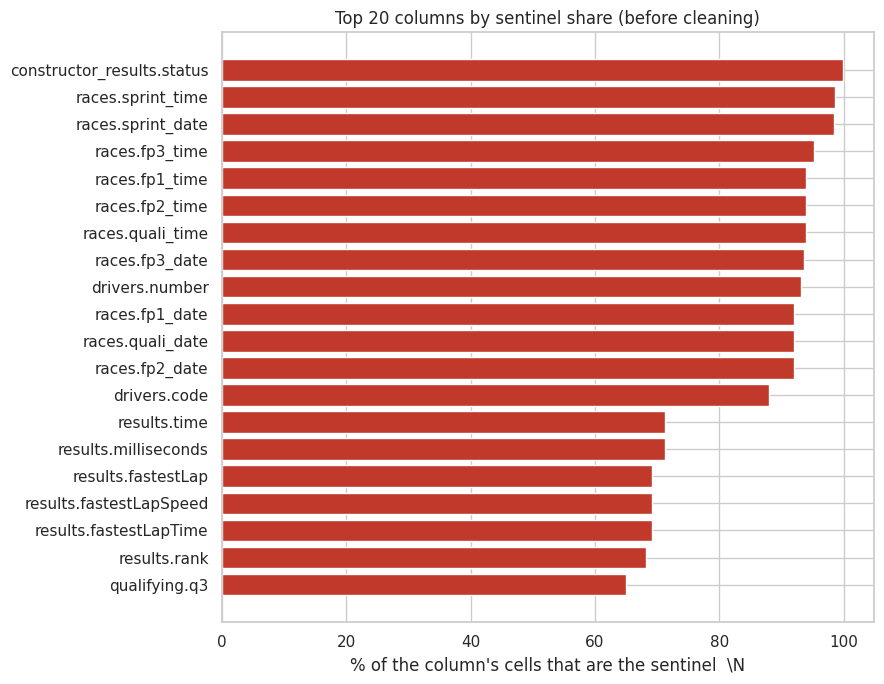

In [5]:
rows = []
for t in TABLES:
    s = count_sentinels(naive[t])
    for col, n in s[s > 0].items():
        rows.append({"table": t, "column": col, "sentinel_cells": int(n),
                     "pct_of_column": 100 * n / len(naive[t])})

sent_df = pd.DataFrame(rows).sort_values("pct_of_column", ascending=False).reset_index(drop=True)
sent_df["label"] = sent_df["table"] + "." + sent_df["column"]
display(sent_df.head(15))

top = sent_df.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top["label"], top["pct_of_column"], color="#c0392b")
ax.set_xlabel("% of the column's cells that are the sentinel  \\N")
ax.set_title("Top 20 columns by sentinel share (before cleaning)")
plt.tight_layout()
plt.show()

### 2.2 Sentinel values versus pandas missing values
Show why treating `\N` as ordinary text can hide missingness and affect data types.


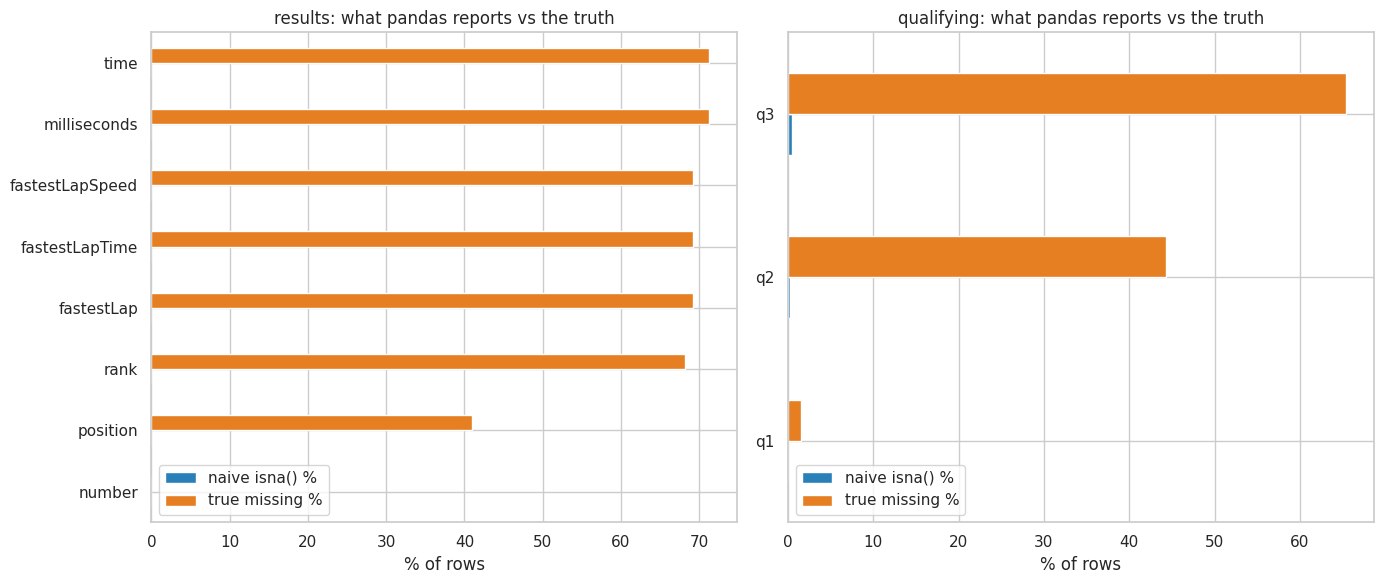

In [6]:
def missingness_table(df):
    """Naive isna() % versus the true missing % (isna + sentinel cells)."""
    n = len(df)
    sent = count_sentinels(df).reindex(df.columns).fillna(0)
    out = pd.DataFrame({
        "naive isna() %": 100 * df.isna().sum() / n,
        "true missing %": 100 * (df.isna().sum() + sent) / n,
    })
    return out[out["true missing %"] > 0].sort_values("true missing %")


fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, t in zip(axes, ["results", "qualifying"]):
    miss = missingness_table(naive[t])
    miss.plot.barh(ax=ax, color=["#2980b9", "#e67e22"])
    ax.set_title(f"{t}: what pandas reports vs the truth")
    ax.set_xlabel("% of rows")
plt.tight_layout()
plt.show()

### 2.3 Coverage over time
Check how race and qualifying coverage changes across F1 eras. This is important when interpreting later analyses.


First season with any qualifying rows: 1994
Seasons with full qualifying coverage (100% of races): 23 of 75


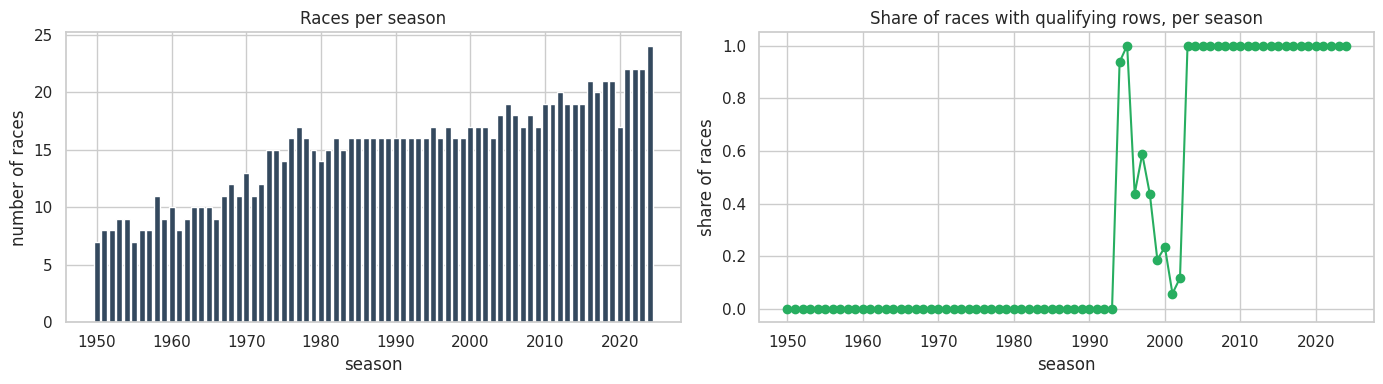

In [7]:
races_per_year = naive["races"].groupby("year").size()

q_races = (naive["qualifying"][["raceId"]].drop_duplicates()
           .merge(naive["races"][["raceId", "year"]], on="raceId", how="left")
           .groupby("year").size())
coverage = (q_races.reindex(races_per_year.index).fillna(0) / races_per_year).rename("share_of_races_with_qualifying")

first_year = coverage[coverage > 0].index.min()
print("First season with any qualifying rows:", first_year)
print("Seasons with full qualifying coverage (100% of races):", int((coverage == 1).sum()), "of", len(coverage))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(races_per_year.index, races_per_year.values, color="#34495e")
axes[0].set_title("Races per season")
axes[0].set_xlabel("season"); axes[0].set_ylabel("number of races")

axes[1].plot(coverage.index, coverage.values, marker="o", color="#27ae60")
axes[1].set_ylim(-0.05, 1.05)
axes[1].set_title("Share of races with qualifying rows, per season")
axes[1].set_xlabel("season"); axes[1].set_ylabel("share of races")
plt.tight_layout()
plt.show()

### 2.4 Initial target and modeling population
Inspect the initial podium rate and the definition of a driver-race observation before cleaning.


In [8]:
podium_rate_before = (pd.to_numeric(naive["results"]["positionOrder"], errors="coerce") <= 3).mean()
print(f"Podium base rate BEFORE cleaning: {podium_rate_before:.4f}  ({podium_rate_before*100:.2f}% of rows)")

pt = naive["results"]["positionText"].astype(str)
non_numeric = pt[~pt.str.fullmatch(r"\d+")]
print("\nNon-numeric positionText codes (why a row has no finishing position):")
print(non_numeric.value_counts().to_string())

Podium base rate BEFORE cleaning: 0.1269  (12.69% of rows)

Non-numeric positionText codes (why a row has no finishing position):
positionText
R    8897
F    1368
W     336
N     190
D     151
E       9


## 3. Cleaning
Convert sentinels to missing values and apply the semantic types needed for dates,durations,and numeric fields.


In [9]:
raw = {
    t: pd.read_csv(DATA_DIR / f"{t}.csv", na_values=[SENTINEL, ""], keep_default_na=False, low_memory=False)
    for t in TABLES
}

# Verification: no literal \N may remain anywhere.
remaining = sum(int(count_sentinels(raw[t]).sum()) for t in TABLES)
before_total = int(inventory["sentinel_cells"].sum())
print(f"Sentinel cells before: {before_total:,}   after sentinel-aware loading: {remaining:,}")
assert remaining == 0

# The work copy. From here on we only modify `clean`, never `raw`.
clean = {t: df.copy() for t, df in raw.items()}

display(clean["results"].dtypes.astype(str).to_frame("dtype_after_sentinel_handling").T)

Sentinel cells before: 160,076   after sentinel-aware loading: 0


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
dtype_after_sentinel_handling,int64,int64,int64,int64,float64,int64,float64,object,int64,float64,int64,object,float64,float64,float64,object,float64,int64


### 3.1 Semantic typing — dates
Convert date strings to actual datetime values and check for parsing failures.


In [10]:
def parse_dates(series, name):
    """Text 'YYYY-MM-DD' -> datetime64. Warn if a non-missing value fails to parse."""
    parsed = pd.to_datetime(series, format="%Y-%m-%d", errors="coerce")
    newly_missing = int(parsed.isna().sum() - series.isna().sum())
    if newly_missing:
        warnings.warn(f"{name}: {newly_missing} date strings could not be parsed")
    return parsed


races = clean["races"]
date_cols = [c for c in races.columns if c == "date" or c.endswith("_date")]   # date, fp1_date, quali_date, ...
for c in date_cols:
    races[c] = parse_dates(races[c], f"races.{c}")
clean["drivers"]["dob"] = parse_dates(clean["drivers"]["dob"], "drivers.dob")

print("Converted race date columns:", date_cols)
print("Race dates range from", races["date"].min().date(), "to", races["date"].max().date())
print("Driver birth dates range from", clean["drivers"]["dob"].min().date(), "to", clean["drivers"]["dob"].max().date())

Converted race date columns: ['date', 'fp1_date', 'fp2_date', 'fp3_date', 'quali_date', 'sprint_date']
Race dates range from 1950-05-13 to 2024-12-08
Driver birth dates range from 1896-12-28 to 2005-05-08


### 3.2 Semantic typing — durations
Convert lap-time strings to numeric seconds so duration variables can be analyzed correctly.


In [11]:
def time_to_seconds(value):
    """'1:27.452' -> 87.452 | '27.452' -> 27.452 | '1:02:03.456' -> 3723.456 | missing -> NaN"""
    if pd.isna(value):
        return np.nan
    try:
        seconds = 0.0
        for part in str(value).strip().split(":"):
            seconds = seconds * 60 + float(part)       # each ':' is a base-60 step
        return seconds
    except ValueError:
        return np.nan


# quick unit tests of the function
assert time_to_seconds("1:27.452") == 87.452
assert time_to_seconds("27.452") == 27.452
assert time_to_seconds("1:02:03.456") == 3723.456
assert np.isnan(time_to_seconds(np.nan))

DURATION_COLUMNS = {
    "qualifying": ["q1", "q2", "q3"],
    "results": ["fastestLapTime"],
    "lap_times": ["time"],
    "pit_stops": ["duration"],
}

for table, cols in DURATION_COLUMNS.items():
    df = clean[table]
    for col in cols:
        df[f"{col}_sec"] = df[col].map(time_to_seconds)
        failed = int(df[f"{col}_sec"].isna().sum() - df[col].isna().sum())
        print(f"{table}.{col:<15} -> {col}_sec   values that failed to parse: {failed}")

# cross-check against the milliseconds columns
for table, col in [("lap_times", "time_sec"), ("pit_stops", "duration_sec")]:
    df = clean[table]
    diff = (df[col] * 1000 - df["milliseconds"]).abs().dropna()
    status = "OK" if diff.max() < 1 else "CHECK"
    print(f"{table}: max |seconds*1000 - milliseconds| = {diff.max():.4f} ms   [{status}]")

qualifying.q1              -> q1_sec   values that failed to parse: 0
qualifying.q2              -> q2_sec   values that failed to parse: 0
qualifying.q3              -> q3_sec   values that failed to parse: 0
results.fastestLapTime  -> fastestLapTime_sec   values that failed to parse: 0
lap_times.time            -> time_sec   values that failed to parse: 0
pit_stops.duration        -> duration_sec   values that failed to parse: 0
lap_times: max |seconds*1000 - milliseconds| = 0.0000 ms   [OK]
pit_stops: max |seconds*1000 - milliseconds| = 0.0000 ms   [OK]


### 3.3 Basic range checks
Check key result variables for implausible ranges after typing.


In [12]:
display(clean["results"][["grid", "position", "positionOrder", "points", "laps"]].describe().T)
print("Season range:", int(clean["races"]["year"].min()), "to", int(clean["races"]["year"].max()))
print("grid == 0 rows (pit-lane start / no grid slot):", int((clean["results"]["grid"] == 0).sum()))

,count,mean,std,min,25%,50%,75%,max
grid,26759.0,11.134796,7.202860,0.0,5.0,11.0,17.0,34.0
position,15806.0,8.020499,4.840796,1.0,4.0,8.0,11.0,33.0
positionOrder,26759.0,12.794051,7.665951,1.0,6.0,12.0,18.0,39.0
points,26759.0,1.987632,4.351209,0.0,0.0,0.0,2.0,50.0
laps,26759.0,46.301768,29.496557,0.0,23.0,53.0,66.0,200.0


Season range: 1950 to 2024
grid == 0 rows (pit-lane start / no grid slot): 1638


## 4. Fix the Modeling Grain
The required modeling grain is exactly one row per `(raceId,driverId)`. Check duplicates and document how shared-drive duplicates are handled.


results rows                                  : 26,759
(raceId, driverId) pairs appearing > 1 times  : 85
extra rows that must be removed               : 91


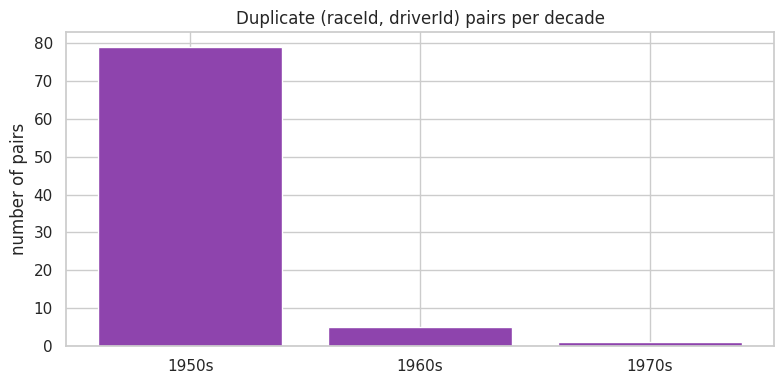

Examples (same driver, same race, two rows):


,raceId,year,name,driverId,constructorId,number,grid,positionOrder,points,laps,statusId
0,540,1978,Italian Grand Prix,229,54,10.0,0,26,0.0,0,81
1,540,1978,Italian Grand Prix,229,57,23.0,0,29,0.0,0,97
2,717,1964,United States Grand Prix,373,172,1.0,1,7,0.0,102,60
175,717,1964,United States Grand Prix,373,172,2.0,1,12,0.0,54,98
3,733,1962,British Grand Prix,465,172,48.0,0,22,0.0,0,54
4,733,1962,British Grand Prix,465,97,50.0,0,25,0.0,0,54
5,742,1961,British Grand Prix,475,102,26.0,20,19,0.0,56,2
6,742,1961,British Grand Prix,475,172,28.0,5,21,0.0,44,23


In [13]:
KEY = ["raceId", "driverId"]

res = clean["results"].copy()
res["podium"] = (res["positionOrder"] <= 3).astype(int)

n_results_before = len(res)
n_extra = int(res.duplicated(subset=KEY, keep="first").sum())
dup_rows = res[res.duplicated(subset=KEY, keep=False)].copy()
n_pairs = dup_rows.groupby(KEY).ngroups

print(f"results rows                                  : {n_results_before:,}")
print(f"(raceId, driverId) pairs appearing > 1 times  : {n_pairs}")
print(f"extra rows that must be removed               : {n_extra}")

dup_rows = dup_rows.merge(clean["races"][["raceId", "year", "name"]], on="raceId", how="left")
dup_rows["decade"] = (dup_rows["year"] // 10 * 10).astype(int)
pairs_per_decade = dup_rows.drop_duplicates(KEY).groupby("decade").size()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(pairs_per_decade.index.astype(str) + "s", pairs_per_decade.values, color="#8e44ad")
ax.set_title("Duplicate (raceId, driverId) pairs per decade")
ax.set_ylabel("number of pairs")
plt.tight_layout()
plt.show()

example_cols = ["raceId", "year", "name", "driverId", "constructorId", "number",
                "grid", "positionOrder", "points", "laps", "statusId"]
print("Examples (same driver, same race, two rows):")
display(dup_rows.sort_values(KEY + ["positionOrder"]).head(8)[example_cols])

### 4.1 Duplicate conflict check
Check whether duplicate driver-race rows disagree on the podium label before applying the deterministic rule.


In [14]:
conflict_pairs = int((dup_rows.groupby(KEY)["podium"].nunique() > 1).sum())
print(f"Duplicated pairs where the two rows disagree on the podium label: {conflict_pairs} "
      f"({100 * conflict_pairs / max(n_pairs, 1):.1f}% of duplicated pairs, "
      f"{100 * conflict_pairs / len(res):.4f}% of all rows)")

Duplicated pairs where the two rows disagree on the podium label: 21 (24.7% of duplicated pairs, 0.0785% of all rows)


### 4.2 Duplicate-handling rule
Keep the best recorded `positionOrder`; break ties with the lowest `resultId`. This produces one deterministic observation per driver-race pair.

**Why this rule.** These duplicates are shared drives from early F1, where one driver raced more than one car in the same race. The best position is the result that counts as that driver's outcome for the race, so keeping it makes the label match how the driver is credited. Breaking ties with the lowest `resultId` guarantees the same row is kept every time the notebook runs. Only 85 driver–race pairs (91 rows, 0.3% of all results) are affected, almost all from the 1950s. In the 21 pairs where the two rows disagree on podium, this rule keeps the podium row; with 21 rows out of 24,967 this cannot meaningfully change the model.

In [15]:
best = (res.sort_values(KEY + ["positionOrder", "resultId"])
           .drop_duplicates(subset=KEY, keep="first")
           .sort_values("resultId")
           .reset_index(drop=True))

# --- hard guarantees: these must be true, otherwise the notebook stops ---
assert not best.duplicated(subset=KEY).any(), "grain violated: duplicates remain"
assert best[KEY].notna().all().all(), "null key values"
assert len(best) == n_results_before - n_extra

clean["results"] = best.drop(columns=["podium"])   # the label is created again in the modeling table below

print(f"results rows: {n_results_before:,} -> {len(best):,}  (removed {n_extra})")
# Informational diagnostic (NOT an error): in this dataset some rows share a finishing position with another
# driver in the same race. Our hypothesis: co-drivers of a shared car are credited with the same classification.
shared = best[best.duplicated(subset=["raceId", "positionOrder"], keep=False)]
print(f"Rows that share a finishing position with another driver in the same race: {len(shared)}")
if len(shared):
    shared_years = shared.merge(clean["races"][["raceId", "year"]], on="raceId", how="left")["year"]
    print("  by decade:", (shared_years // 10 * 10).astype(int).value_counts().sort_index().to_dict())
    groups = shared.groupby(["raceId", "positionOrder"]).agg(n_rows=("driverId", "size"),
                                                          n_constructors=("constructorId", "nunique"))
    print(f"  groups of tied rows: {len(groups)}; share where all tied rows belong to the SAME constructor: "
          f"{(groups['n_constructors'] == 1).mean():.0%}  (supports the shared-car explanation if high)")
print("Consequence: a race can have more than 3 rows with positionOrder <= 3 (checked in Section 5.3).")

results rows: 26,759 -> 26,668  (removed 91)
Rows that share a finishing position with another driver in the same race: 184
  by decade: {1950: 178, 1960: 6}
  groups of tied rows: 87; share where all tied rows belong to the SAME constructor: 100%  (supports the shared-car explanation if high)
Consequence: a race can have more than 3 rows with positionOrder <= 3 (checked in Section 5.3).


## 5. Define the Modeling Population
Identify non-starters and exclude them from the modeling table because the prediction concerns drivers who actually start the race.


,rows,share_zero_laps,share_grid_zero,podium_labels,mean_positionOrder
is_non_starter,,,,,
"starters (finishers, R, D, E, N)",24967,0.033,0.003,3395,11.798
"non-starters (F, W)",1701,0.996,0.910,0,27.164


Podium labels among non-starters: 0  -> removing them can only remove negatives
Podium base rate: all rows 0.1273  vs  starters only 0.1360


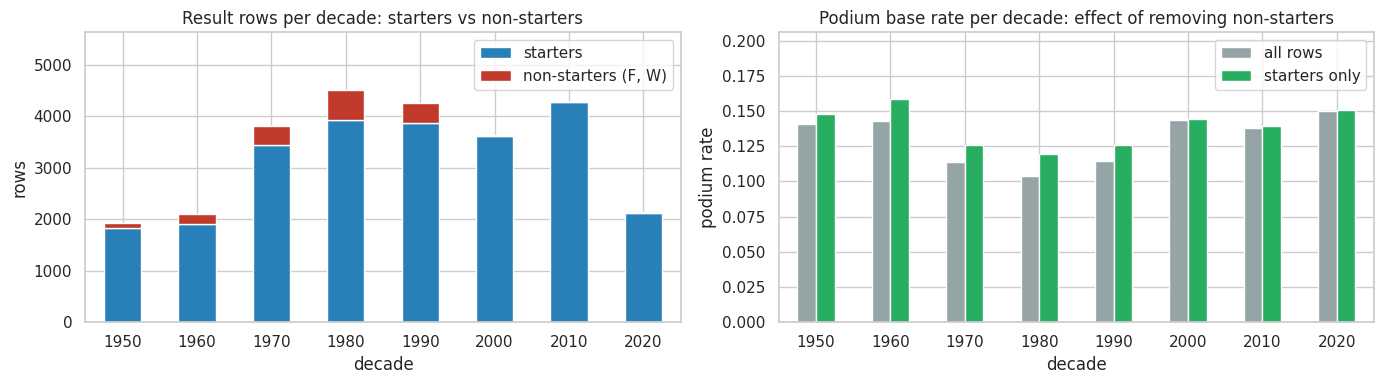

In [16]:
NON_STARTER_CODES = ["F", "W"]       # positionText codes of drivers who never took the start
EXCLUDE_NON_STARTERS = True          # team switch: set to False to keep them (reproduces the table without this rule)

res_check = clean["results"].merge(clean["races"][["raceId", "year"]], on="raceId", how="left", validate="many_to_one")
res_check["is_non_starter"] = res_check["positionText"].isin(NON_STARTER_CODES)
res_check["podium"] = (res_check["positionOrder"] <= 3).astype(int)
res_check["decade"] = (res_check["year"] // 10 * 10).astype(int)

evidence = (res_check.groupby("is_non_starter")
            .agg(rows=("resultId", "size"),
                 share_zero_laps=("laps", lambda s: (s == 0).mean()),
                 share_grid_zero=("grid", lambda s: (s == 0).mean()),
                 podium_labels=("podium", "sum"),
                 mean_positionOrder=("positionOrder", "mean"))
            .rename(index={False: "starters (finishers, R, D, E, N)", True: "non-starters (F, W)"}))
display(evidence.round(3))

lost_podiums = int(res_check.loc[res_check["is_non_starter"], "podium"].sum())
rate_all = res_check["podium"].mean()
rate_starters = res_check.loc[~res_check["is_non_starter"], "podium"].mean()
print(f"Podium labels among non-starters: {lost_podiums}  -> removing them can only remove negatives")
print(f"Podium base rate: all rows {rate_all:.4f}  vs  starters only {rate_starters:.4f}")

dec = res_check.groupby(["decade", "is_non_starter"]).size().unstack(fill_value=0)
dec.columns = ["starters" if not c else "non-starters (F, W)" for c in dec.columns]
rate_dec = pd.DataFrame({
    "all rows": res_check.groupby("decade")["podium"].mean(),
    "starters only": res_check[~res_check["is_non_starter"]].groupby("decade")["podium"].mean(),
})

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
dec.plot.bar(stacked=True, ax=axes[0], color=["#2980b9", "#c0392b"])
axes[0].set_title("Result rows per decade: starters vs non-starters")
axes[0].set_xlabel("decade"); axes[0].set_ylabel("rows")
rate_dec.plot.bar(ax=axes[1], color=["#95a5a6", "#27ae60"])
axes[1].set_title("Podium base rate per decade: effect of removing non-starters")
axes[1].set_xlabel("decade"); axes[1].set_ylabel("podium rate")
axes[0].set_ylim(0, dec.sum(axis=1).max() * 1.25)
axes[1].set_ylim(0, rate_dec.max().max() * 1.3)
for a in axes:
    a.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 6. Build the Driver-Race Foundation
Create the cleaned `driver_race` table by combining race information with driver results. This is the foundation for Tasks 2–6.


In [17]:
races_small = (clean["races"][["raceId", "year", "round", "circuitId", "name", "date"]]
               .rename(columns={"name": "race_name"}))

driver_race_all = clean["results"].merge(races_small, on="raceId", how="left", validate="many_to_one")
assert len(driver_race_all) == len(clean["results"]), "the join changed the number of rows!"

driver_race_all["podium"] = (driver_race_all["positionOrder"] <= 3).astype(int)
driver_race_all["is_non_starter"] = driver_race_all["positionText"].isin(NON_STARTER_CODES)
driver_race_all = driver_race_all.sort_values(["date", "raceId", "positionOrder"]).reset_index(drop=True)

# The modeling table: one row per driver who actually took the start (see Section 3.6).
if EXCLUDE_NON_STARTERS:
    driver_race = driver_race_all[~driver_race_all["is_non_starter"]].copy()
else:
    driver_race = driver_race_all.copy()
driver_race = driver_race.reset_index(drop=True)

assert not driver_race.duplicated(subset=KEY).any(), "grain violated in the modeling table"

# Known only AFTER the race -> never allowed as model inputs (data leakage).
# (is_non_starter is derived from positionText, so it is post-race information too: use it to filter rows, never as a feature.)
POST_RACE_COLUMNS = [
    "position", "positionText", "positionOrder", "points", "laps", "time", "milliseconds",
    "fastestLap", "rank", "fastestLapTime", "fastestLapTime_sec", "fastestLapSpeed", "statusId", "is_non_starter",
]
# Available at the prediction cutoff (after qualifying, before the start):
PRE_RACE_CANDIDATES = ["grid", "constructorId", "number", "year", "round", "circuitId", "date"]

print("driver_race_all (every de-duplicated result row):", driver_race_all.shape)
print("driver_race (modeling table, non-starters removed):", driver_race.shape)
driver_race.head()

driver_race_all (every de-duplicated result row): (26668, 26)
driver_race (modeling table, non-starters removed): (24967, 26)


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,fastestLapTime_sec,year,round,circuitId,race_name,date,podium,is_non_starter
0,20025,833,642,51,2.0,1,1.0,1,1,9.0,70,2:13:23.6,8003600.0,NaN,NaN,NaN,NaN,1,NaN,1950,1,9,British Grand Prix,1950-05-13,1,False
1,20026,833,786,51,3.0,2,2.0,2,2,6.0,70,+2.6,8006200.0,NaN,NaN,NaN,NaN,1,NaN,1950,1,9,British Grand Prix,1950-05-13,1,False
2,20027,833,686,51,4.0,4,3.0,3,3,4.0,70,+52.0,8055600.0,NaN,NaN,NaN,NaN,1,NaN,1950,1,9,British Grand Prix,1950-05-13,1,False
3,20028,833,704,154,14.0,6,4.0,4,4,3.0,68,NaN,NaN,NaN,NaN,NaN,NaN,12,NaN,1950,1,9,British Grand Prix,1950-05-13,0,False
4,20029,833,627,154,15.0,9,5.0,5,5,2.0,68,NaN,NaN,NaN,NaN,NaN,NaN,12,NaN,1950,1,9,British Grand Prix,1950-05-13,0,False


## 7. Primary-Key and Foreign-Key Audits
Verify that table keys are unique/non-null and that foreign-key values reconcile with their referenced tables.


In [18]:
# Primary keys as documented by the dataset (lap_times / pit_stops have no ID column, so their key is composite).
PRIMARY_KEYS = {
    "circuits": ["circuitId"],
    "constructors": ["constructorId"],
    "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"],
    "drivers": ["driverId"],
    "driver_standings": ["driverStandingsId"],
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"],
    "qualifying": ["qualifyId"],
    "races": ["raceId"],
    "results": ["resultId"],
    "seasons": ["year"],
    "sprint_results": ["resultId"],
    "status": ["statusId"],
}

# "Natural" keys: the business meaning of one row (these are the grain checks, like our (raceId, driverId)).
NATURAL_KEYS = {
    "results": ["raceId", "driverId"],
    "qualifying": ["raceId", "driverId"],
    "driver_standings": ["raceId", "driverId"],
    "constructor_standings": ["raceId", "constructorId"],
    "constructor_results": ["raceId", "constructorId"],
    "sprint_results": ["raceId", "driverId"],
}


def audit_keys(tables, key_map, kind):
    rows = []
    for name, cols in key_map.items():
        df = tables[name]
        absent = [c for c in cols if c not in df.columns]
        if absent:
            rows.append({"table": name, "kind": kind, "key": "+".join(cols), "rows": len(df),
                         "null_key_rows": None, "duplicate_rows": None, "status": f"MISSING COLUMN {absent}"})
            continue
        null_rows = int(df[cols].isna().any(axis=1).sum())
        dup_rows = int(df.duplicated(subset=cols, keep="first").sum())
        rows.append({"table": name, "kind": kind, "key": "+".join(cols), "rows": len(df),
                     "null_key_rows": null_rows, "duplicate_rows": dup_rows,
                     "status": "PASS" if (null_rows == 0 and dup_rows == 0) else "FAIL"})
    return pd.DataFrame(rows)


print("=== Primary keys on the CLEANED tables ===")
pk_audit = audit_keys(clean, PRIMARY_KEYS, "primary")
display(pk_audit)

=== Primary keys on the CLEANED tables ===


,table,kind,key,rows,null_key_rows,duplicate_rows,status
0,circuits,primary,circuitId,77,0,0,PASS
1,constructors,primary,constructorId,212,0,0,PASS
2,constructor_results,primary,constructorResultsId,12625,0,0,PASS
3,constructor_standings,primary,constructorStandingsId,13391,0,0,PASS
4,drivers,primary,driverId,861,0,0,PASS
5,driver_standings,primary,driverStandingsId,34863,0,0,PASS
6,lap_times,primary,raceId+driverId+lap,589081,0,0,PASS
7,pit_stops,primary,raceId+driverId+stop,11371,0,0,PASS
8,qualifying,primary,qualifyId,10494,0,0,PASS
9,races,primary,raceId,1125,0,0,PASS


,table,key,duplicate_rows_before,status_before,duplicate_rows_after,status_after
0,results,raceId+driverId,91,FAIL,0,PASS
1,qualifying,raceId+driverId,0,PASS,0,PASS
2,driver_standings,raceId+driverId,0,PASS,0,PASS
3,constructor_standings,raceId+constructorId,0,PASS,0,PASS
4,constructor_results,raceId+constructorId,0,PASS,0,PASS
5,sprint_results,raceId+driverId,0,PASS,0,PASS


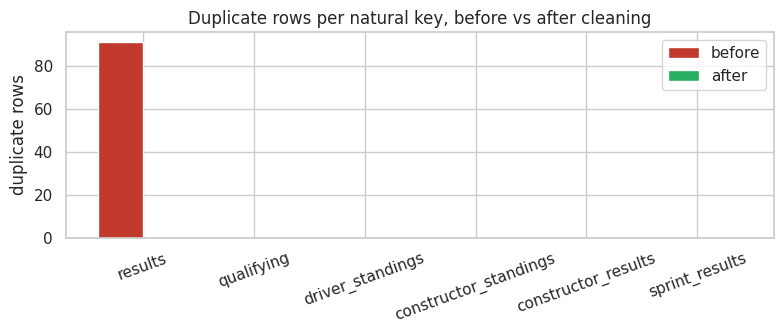

In [19]:
nat_before = audit_keys(raw, NATURAL_KEYS, "natural").add_suffix("_before")
nat_after = audit_keys(clean, NATURAL_KEYS, "natural").add_suffix("_after")
nat = pd.concat([nat_before[["table_before", "key_before", "duplicate_rows_before", "status_before"]],
                 nat_after[["duplicate_rows_after", "status_after"]]], axis=1).rename(columns={"table_before": "table", "key_before": "key"})
display(nat)

fig, ax = plt.subplots(figsize=(8, 3.5))
x = np.arange(len(nat))
ax.bar(x - 0.2, nat["duplicate_rows_before"].astype(float), width=0.4, label="before", color="#c0392b")
ax.bar(x + 0.2, nat["duplicate_rows_after"].astype(float), width=0.4, label="after", color="#27ae60")
ax.set_xticks(x); ax.set_xticklabels(nat["table"], rotation=20)
ax.set_ylabel("duplicate rows"); ax.set_title("Duplicate rows per natural key, before vs after cleaning")
ax.legend(); plt.tight_layout(); plt.show()

In [20]:
FOREIGN_KEYS = [
    ("races", "circuitId", "circuits", "circuitId"),
    ("races", "year", "seasons", "year"),
    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),
    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),
    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),
    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),
    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),
    ("lap_times", "raceId", "races", "raceId"),
    ("lap_times", "driverId", "drivers", "driverId"),
    ("pit_stops", "raceId", "races", "raceId"),
    ("pit_stops", "driverId", "drivers", "driverId"),
    ("sprint_results", "raceId", "races", "raceId"),
    ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "statusId", "status", "statusId"),
]


def audit_foreign_keys(tables, fk_list):
    rows = []
    for child, ccol, parent, pcol in fk_list:
        c, p = tables[child], tables[parent]
        label = f"{child}.{ccol} -> {parent}.{pcol}"
        if ccol not in c.columns or pcol not in p.columns:
            rows.append({"foreign_key": label, "child_rows": len(c), "null_fk_rows": None,
                         "orphan_rows": None, "orphan_distinct_values": None, "status": "MISSING COLUMN"})
            continue
        parent_values = set(p[pcol].dropna().unique())
        child_values = c[ccol].dropna()
        orphan_mask = ~child_values.isin(parent_values)
        rows.append({"foreign_key": label, "child_rows": len(c), "null_fk_rows": int(c[ccol].isna().sum()),
                     "orphan_rows": int(orphan_mask.sum()),
                     "orphan_distinct_values": int(child_values[orphan_mask].nunique()),
                     "status": "PASS" if orphan_mask.sum() == 0 else "FAIL"})
    return pd.DataFrame(rows)


fk_audit = audit_foreign_keys(clean, FOREIGN_KEYS)
display(fk_audit)
print(f"Foreign keys passing: {(fk_audit['status'] == 'PASS').sum()} / {len(fk_audit)}")

,foreign_key,child_rows,null_fk_rows,orphan_rows,orphan_distinct_values,status
0,races.circuitId -> circuits.circuitId,1125,0,0,0,PASS
1,races.year -> seasons.year,1125,0,0,0,PASS
2,results.raceId -> races.raceId,26668,0,0,0,PASS
3,results.driverId -> drivers.driverId,26668,0,0,0,PASS
4,results.constructorId -> constructors.construc...,26668,0,0,0,PASS
5,results.statusId -> status.statusId,26668,0,0,0,PASS
6,qualifying.raceId -> races.raceId,10494,0,0,0,PASS
7,qualifying.driverId -> drivers.driverId,10494,0,0,0,PASS
8,qualifying.constructorId -> constructors.const...,10494,0,0,0,PASS
9,driver_standings.raceId -> races.raceId,34863,0,0,0,PASS


Foreign keys passing: 23 / 23


In [21]:
races_without_results = set(clean["races"]["raceId"]) - set(clean["results"]["raceId"])
print("Races with no result rows:", len(races_without_results))
if races_without_results:
    display(clean["races"][clean["races"]["raceId"].isin(races_without_results)][["raceId", "year", "round", "name", "date"]]
            .sort_values("date"))

Races with no result rows: 0


## 8. EDA After Cleaning
Repeat the key checks after cleaning to show what changed and confirm that the modeling table is valid.


In [22]:
sentinels_after = sum(int(count_sentinels(clean[t]).sum()) for t in TABLES)
text_cols_before = sum(is_text_col(naive["results"][c]) for c in naive["results"].columns)
text_cols_after = sum(is_text_col(clean["results"][c]) for c in clean["results"].columns)

summary = pd.DataFrame({
    "metric": [
        "results rows",
        "duplicate (raceId, driverId) rows",
        "sentinel cells (\\N) across 14 tables",
        "non-numeric columns in results",
        "podium base rate (all rows)",
        "rows in the modeling table (non-starters removed)",
        "podium base rate (modeling table)",
    ],
    "before cleaning": [
        f"{len(naive['results']):,}",
        f"{n_extra}",
        f"{before_total:,}",
        f"{text_cols_before}",
        f"{podium_rate_before:.4f}",
        "-",
        "-",
    ],
    "after cleaning": [
        f"{len(driver_race_all):,}",
        f"{int(driver_race_all.duplicated(subset=KEY).sum())}",
        f"{sentinels_after:,}",
        f"{text_cols_after}",
        f"{driver_race_all['podium'].mean():.4f}",
        f"{len(driver_race):,}",
        f"{driver_race['podium'].mean():.4f}",
    ],
}).set_index("metric")
summary

,before cleaning,after cleaning
metric,,
results rows,"26,759","26,668"
"duplicate (raceId, driverId) rows",91,0
sentinel cells (\N) across 14 tables,"160,076",0
non-numeric columns in results,9,3
podium base rate (all rows),0.1269,0.1273
rows in the modeling table (non-starters removed),-,"24,967"
podium base rate (modeling table),-,0.1360


### 8.1 Missingness after cleaning
Compare missingness before and after cleaning to verify that sentinel handling worked.


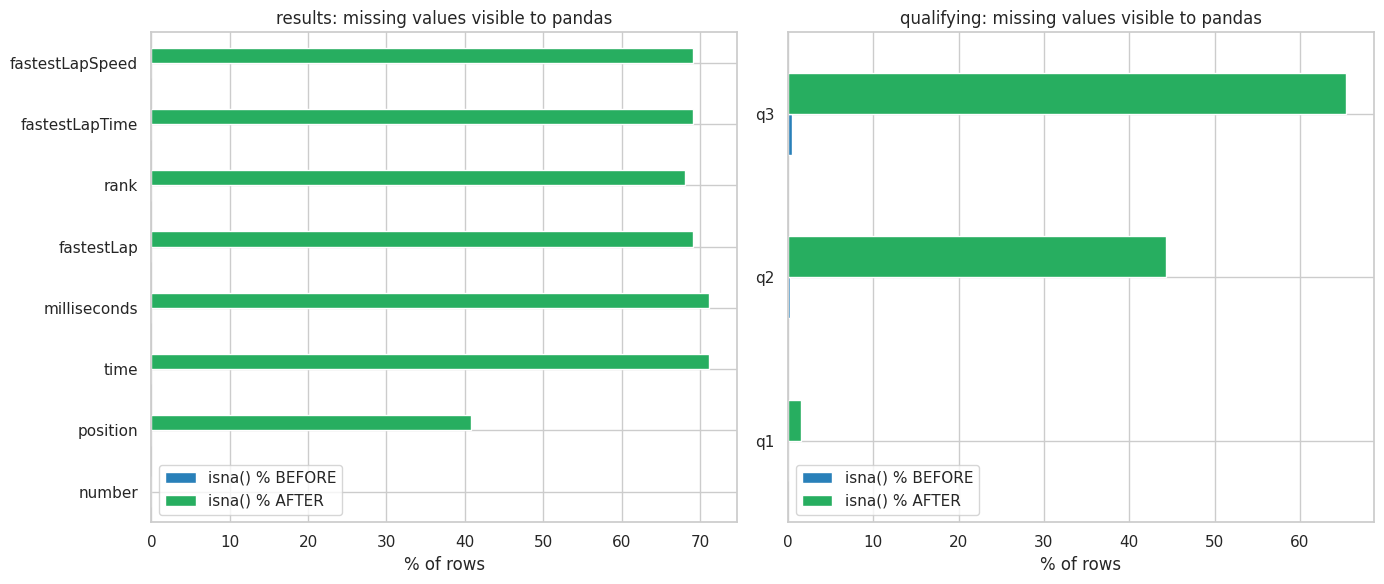

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, t in zip(axes, ["results", "qualifying"]):
    original_cols = list(naive[t].columns)
    before_pct = 100 * naive[t][original_cols].isna().mean()
    after_pct = 100 * clean[t][original_cols].isna().mean()
    comp = pd.DataFrame({"isna() % BEFORE": before_pct, "isna() % AFTER": after_pct})
    comp = comp[(comp > 0).any(axis=1) | (missingness_table(naive[t]).reindex(comp.index)["true missing %"] > 0)]
    comp.plot.barh(ax=ax, color=["#2980b9", "#27ae60"])
    ax.set_title(f"{t}: missing values visible to pandas")
    ax.set_xlabel("% of rows")
plt.tight_layout()
plt.show()

### 8.2 Podium-label sanity check
Confirm the expected podium count per race and inspect the podium base rate across eras.


Number of podium rows per race (value -> number of races):
podium
3    1107
4      16
5       2


,entries,races,podium_rate,avg_field_size
decade,,,,
1950,1834,84,0.148,21.833
1960,1901,100,0.158,19.010
1970,3434,144,0.126,23.847
1980,3929,156,0.119,25.186
1990,3863,162,0.126,23.846
2000,3611,174,0.145,20.753
2010,4268,198,0.139,21.556
2020,2127,107,0.151,19.879


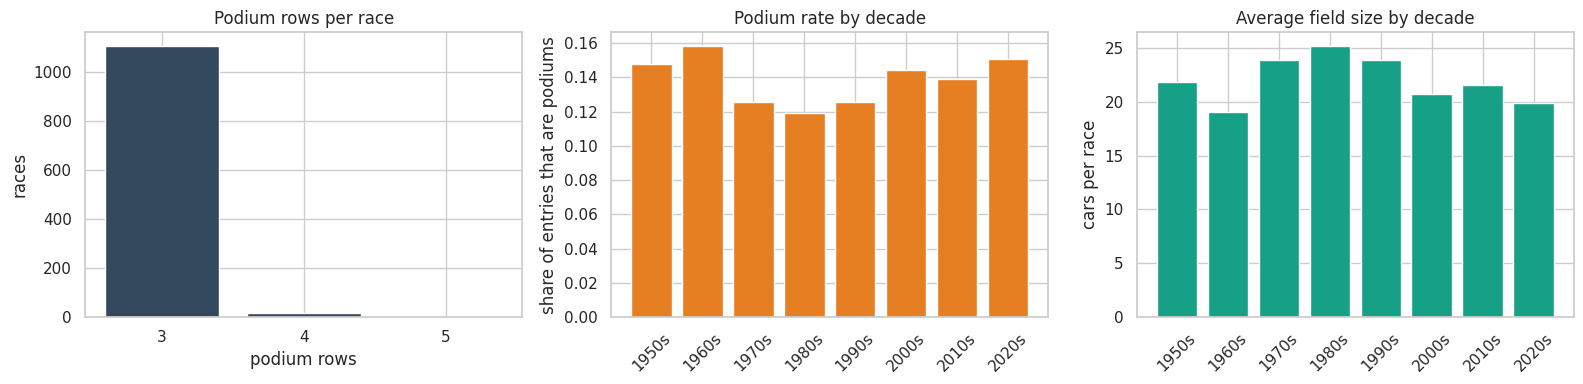

In [24]:
podium_per_race = driver_race.groupby("raceId")["podium"].sum()
counts = podium_per_race.value_counts().sort_index()
print("Number of podium rows per race (value -> number of races):")
print(counts.to_string())

driver_race["decade"] = (driver_race["year"] // 10 * 10).astype(int)
by_decade = driver_race.groupby("decade").agg(entries=("podium", "size"),
                                              races=("raceId", "nunique"),
                                              podium_rate=("podium", "mean"))
by_decade["avg_field_size"] = by_decade["entries"] / by_decade["races"]
display(by_decade.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].bar(counts.index.astype(str), counts.values, color="#34495e")
axes[0].set_title("Podium rows per race"); axes[0].set_xlabel("podium rows"); axes[0].set_ylabel("races")
axes[1].bar(by_decade.index.astype(str) + "s", by_decade["podium_rate"], color="#e67e22")
axes[1].set_title("Podium rate by decade"); axes[1].set_ylabel("share of entries that are podiums")
axes[2].bar(by_decade.index.astype(str) + "s", by_decade["avg_field_size"], color="#16a085")
axes[2].set_title("Average field size by decade"); axes[2].set_ylabel("cars per race")
for a in axes[1:]:
    a.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

### 8.3 Initial feature hypothesis: starting grid
Check whether starting position is associated with podium probability. This motivates later feature engineering without using future race information.


,podium_rate,entries
grid,,
0,0.000,87
1,0.644,1119
2,0.560,1117
3,0.466,1122
4,0.343,1126
5,0.252,1117
6,0.187,1119
7,0.131,1125
8,0.100,1115


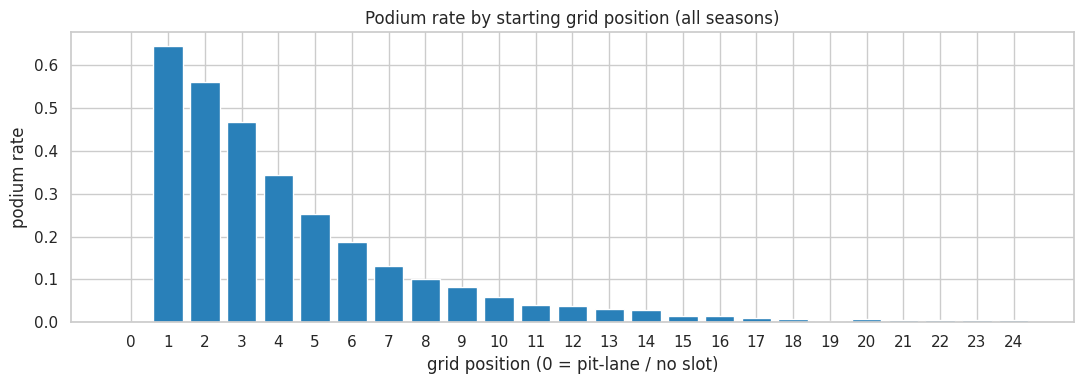

In [25]:
g = (driver_race[driver_race["grid"].between(0, 24)]
     .groupby("grid")["podium"].agg(podium_rate="mean", entries="size"))
display(g.head(12).round(3))

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(g.index.astype(str), g["podium_rate"], color=["#7f8c8d" if i == 0 else "#2980b9" for i in g.index])
ax.set_xlabel("grid position (0 = pit-lane / no slot)")
ax.set_ylabel("podium rate")
ax.set_title("Podium rate by starting grid position (all seasons)")
plt.tight_layout()
plt.show()

### 8.4 Qualifying coverage
Measure qualifying coverage after semantic typing because qualifying information is available at the prediction cutoff.


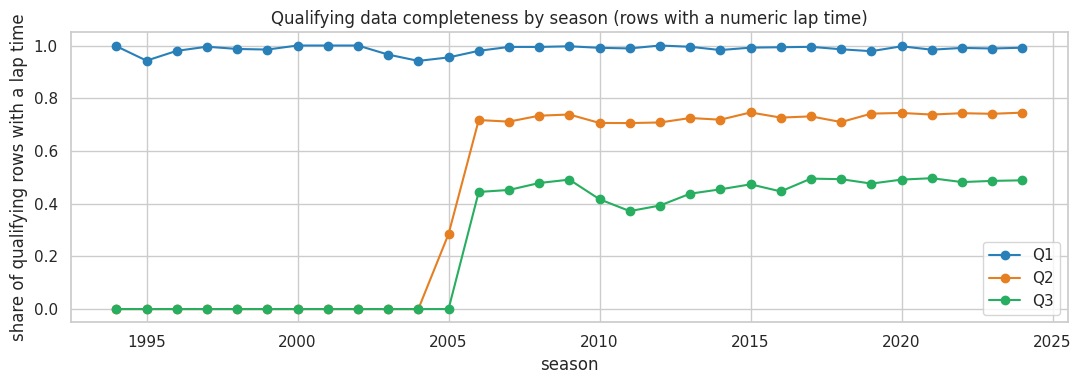

Seasons with qualifying rows: 1994 to 2024


In [26]:
q = clean["qualifying"].merge(clean["races"][["raceId", "year"]], on="raceId", how="left")
q = q.assign(has_q1=q["q1_sec"].notna(), has_q2=q["q2_sec"].notna(), has_q3=q["q3_sec"].notna())
cov = q.groupby("year")[["has_q1", "has_q2", "has_q3"]].mean()

fig, ax = plt.subplots(figsize=(11, 4))
for col, color in zip(["has_q1", "has_q2", "has_q3"], ["#2980b9", "#e67e22", "#27ae60"]):
    ax.plot(cov.index, cov[col], marker="o", label=col.replace("has_", "").upper(), color=color)
ax.set_ylim(-0.05, 1.05)
ax.set_xlabel("season"); ax.set_ylabel("share of qualifying rows with a lap time")
ax.set_title("Qualifying data completeness by season (rows with a numeric lap time)")
ax.legend()
plt.tight_layout()
plt.show()

print("Seasons with qualifying rows:", int(cov.index.min()), "to", int(cov.index.max()))

## 9. Task 1 Summary
Record the final modeling-table size,non-starter handling,and the key cleaning decisions.


In [27]:
print("driver_race_all:", driver_race_all.shape, "| driver_race (modeling table):", driver_race.shape)
print("non-starters removed :", len(driver_race_all) - len(driver_race))
print("distinct races   :", driver_race["raceId"].nunique())
print("distinct drivers :", driver_race["driverId"].nunique())
print("seasons          :", int(driver_race["year"].min()), "-", int(driver_race["year"].max()))
print("one row per (raceId, driverId):", not driver_race.duplicated(subset=KEY).any())
print("podium base rate :", round(driver_race["podium"].mean(), 4))

driver_race_all: (26668, 26) | driver_race (modeling table): (24967, 27)
non-starters removed : 1701
distinct races   : 1125
distinct drivers : 786
seasons          : 1950 - 2024
one row per (raceId, driverId): True
podium base rate : 0.136


# Task 2 — Data-Engineering Questions

These are historical data-engineering analyses,not predictive features. They deliberately use historical race outcomes to answer the three required questions. Their outcome-derived columns remain isolated from the predictive feature set in Tasks 3–6. For Q1,qualifying position and actual grid position are compared because penalties can make them differ.


## 10. Q1 — Front-Row to Podium Conversion
Question: which circuits most often convert a front-row start into a podium,and does the ranking change after the 2014 hybrid-era boundary? The primary measure uses actual starting grid positions 1–2. A separate qualifying-position analysis is shown as a sensitivity check because penalties and pit-lane starts can make qualifying order differ from the grid. Rates are accompanied by sample sizes and 95% Wilson confidence intervals; only circuit-era groups with at least 10 relevant starts are ranked.


In [28]:
from IPython.display import Markdown, display


def wilson_ci(k, n, z=1.96):
    """95% Wilson confidence interval for a proportion k/n. Works on arrays.
    Preferred over the textbook (normal) interval because it behaves well for small n and rates near 0 or 1."""
    k = np.asarray(k, dtype=float)
    n = np.asarray(n, dtype=float)
    with np.errstate(divide="ignore", invalid="ignore"):
        p = k / n
        denom = 1 + z ** 2 / n
        centre = (p + z ** 2 / (2 * n)) / denom
        half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / denom
        # keep the interval inside [0, 1] and guarantee low <= p <= high (protects against floating-point rounding,
        # which can otherwise make an error bar a hair negative when p is exactly 0 or 1)
        low = np.minimum(np.clip(centre - half, 0, 1), p)
        high = np.maximum(np.clip(centre + half, 0, 1), p)
    return low, high


def dumbbell_plot(df, label_col, col_a, col_b, name_a, name_b, title, xlabel):
    """One row per entity: a dot for period A, a dot for period B, a line between them."""
    df = df.sort_values(col_b)
    y = np.arange(len(df))
    fig, ax = plt.subplots(figsize=(9, max(3.5, 0.4 * len(df) + 1.5)))
    ax.hlines(y, df[col_a], df[col_b], color="#bdc3c7", zorder=1)
    ax.scatter(df[col_a], y, color="#e67e22", label=name_a, zorder=2)
    ax.scatter(df[col_b], y, color="#2980b9", label=name_b, zorder=2)
    ax.set_yticks(y)
    ax.set_yticklabels(df[label_col])
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.legend()
    plt.tight_layout()
    plt.show()


def safe_spearman(a, b):
    """Spearman rank correlation; NaN (instead of a warning) when it is undefined (too few points or constant input)."""
    a = pd.Series(np.asarray(a, dtype=float))
    b = pd.Series(np.asarray(b, dtype=float))
    if len(a) < 3 or a.nunique() < 2 or b.nunique() < 2:
        return np.nan
    return a.corr(b, method="spearman")


def fmt_rho(r):
    return "n/a" if pd.isna(r) else f"{r:.2f}"


# sanity check on the helper: 5 podiums out of 10 -> the interval must contain 0.5
lo, hi = wilson_ci(5, 10)
assert lo < 0.5 < hi

In [29]:
MIN_FRONT_ROW_STARTS = 10     # 10 front-row starts = at least 5 races at the circuit in that era

quali = (clean["qualifying"][["raceId", "driverId", "position"]]
         .rename(columns={"position": "qualifying_position"}))
circuits_small = clean["circuits"][["circuitId", "name", "country"]].rename(columns={"name": "circuit_name"})

q1_all = (driver_race[["raceId", "driverId", "circuitId", "year", "grid", "podium"]]
          .merge(quali, on=["raceId", "driverId"], how="left", validate="one_to_one")
          .merge(circuits_small, on="circuitId", how="left", validate="many_to_one"))
assert len(q1_all) == len(driver_race), "a join changed the number of rows"

# Race-level qualifying coverage: keep only races that have qualifying data (same races for both definitions).
races_with_quali = set(clean["qualifying"]["raceId"])
q1_all["race_has_quali_data"] = q1_all["raceId"].isin(races_with_quali)
q1 = q1_all[q1_all["race_has_quali_data"]].copy()

# ---- missingness report ----
season_cov = q1_all.drop_duplicates("raceId").groupby("year")["race_has_quali_data"].mean()
partial = season_cov[(season_cov > 0) & (season_cov < 1)]
n_no_qpos = int(q1["qualifying_position"].isna().sum())
print(f"Races in the modeling table                 : {q1_all['raceId'].nunique():,}")
print(f"Races with qualifying data (used in Q1)     : {q1['raceId'].nunique():,}  "
      f"(seasons {int(q1['year'].min())}-{int(q1['year'].max())})")
print(f"Driver rows dropped (race has no quali data): {len(q1_all) - len(q1):,} of {len(q1_all):,}")
print(f"Rows in covered races with no quali position: {n_no_qpos:,} ({n_no_qpos / len(q1):.1%}) -> counted as 'not front row'")
print(f"Seasons with only PARTIAL qualifying coverage: "
      + (", ".join(f"{int(y)} ({v:.0%})" for y, v in partial.items()) if len(partial) else "none"))

# ---- the two definitions and the two eras ----
q1["front_row_quali"] = q1["qualifying_position"].isin([1, 2])
q1["front_row_grid"] = q1["grid"].isin([1, 2])
ERA_A = f"{int(q1['year'].min())}–2013"
ERA_B = "2014–2024"
q1["era"] = np.where(q1["year"] <= 2013, ERA_A, ERA_B)

agree = (q1["front_row_quali"] == q1["front_row_grid"]).mean()
print(f"\nThe two definitions agree on {agree:.1%} of rows. Where they differ (grid penalties, pit-lane starts, "
      f"missing quali position):")
display(pd.crosstab(q1["front_row_quali"], q1["front_row_grid"],
                    rownames=["front-row qualifier"], colnames=["front-row starter (grid)"]))

Races in the modeling table                 : 1,125
Races with qualifying data (used in Q1)     : 494  (seasons 1994-2024)
Driver rows dropped (race has no quali data): 14,528 of 24,967
Rows in covered races with no quali position: 21 (0.2%) -> counted as 'not front row'
Seasons with only PARTIAL qualifying coverage: 1994 (94%), 1996 (44%), 1997 (59%), 1998 (44%), 1999 (19%), 2000 (24%), 2001 (6%), 2002 (12%)

The two definitions agree on 99.3% of rows. Where they differ (grid penalties, pit-lane starts, missing quali position):


front-row starter (grid),False,True
front-row qualifier,,
False,9419,36
True,37,947


Circuits ranked (>= minimum front-row starts): {'1994–2013': 22, '2014–2024': 19} | circuits left out for small samples: {'1994–2013': 10, '2014–2024': 13}

Top 10 circuits, front-row STARTER (grid 1-2), per era:


,era,circuit_name,starts,podiums,rate,ci_low,ci_high
7,1994–2013,Circuit de Nevers Magny-Cours,18,16,0.889,0.672,0.969
18,1994–2013,Indianapolis Motor Speedway,10,8,0.800,0.490,0.943
4,1994–2013,Istanbul Park,14,11,0.786,0.524,0.924
21,1994–2013,Suzuka Circuit,26,20,0.769,0.579,0.890
5,1994–2013,Circuit de Monaco,28,20,0.714,0.529,0.847
10,1994–2013,Hungaroring,26,18,0.692,0.500,0.835
13,1994–2013,Autodromo Nazionale di Monza,26,18,0.692,0.500,0.835
9,1994–2013,Hockenheimring,22,15,0.682,0.473,0.836
1,1994–2013,Sepang International Circuit,24,16,0.667,0.467,0.820
2,1994–2013,Bahrain International Circuit,18,12,0.667,0.437,0.837


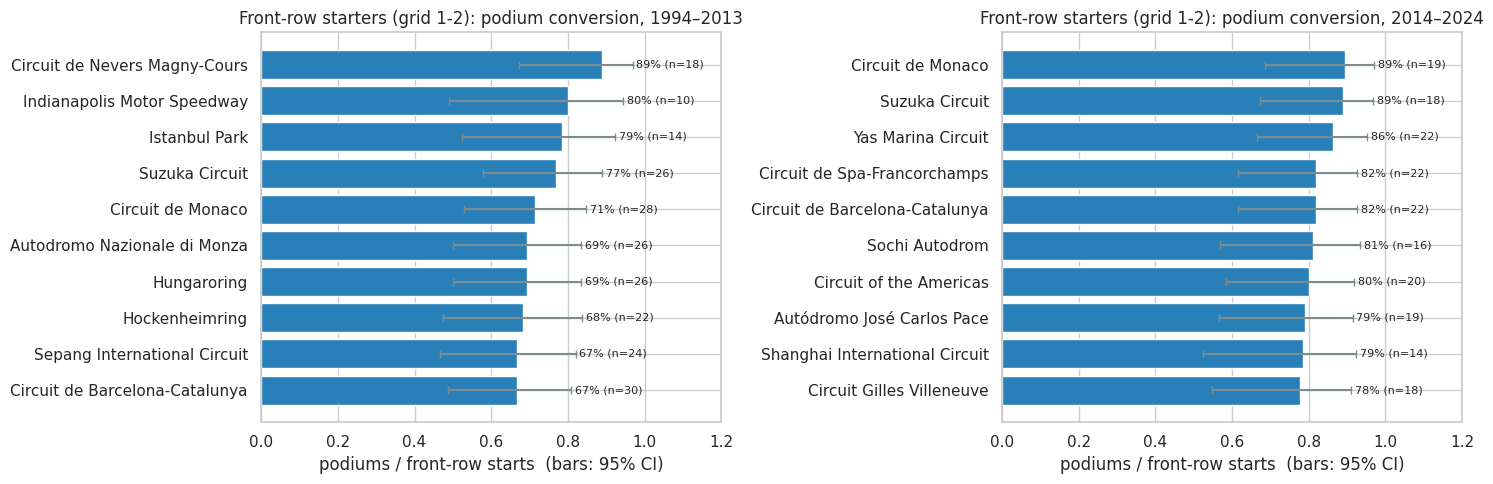

In [30]:
def conversion_table(df, flag, min_n):
    """Per era and circuit: front-row entries, podiums among them, conversion rate and 95% CI."""
    sub = df[df[flag]]
    g = (sub.groupby(["era", "circuitId", "circuit_name"])
            .agg(starts=("podium", "size"), podiums=("podium", "sum")).reset_index())
    g["rate"] = g["podiums"] / g["starts"]
    g["ci_low"], g["ci_high"] = wilson_ci(g["podiums"], g["starts"])
    g["meets_min"] = g["starts"] >= min_n
    return g


conv_grid = conversion_table(q1, "front_row_grid", MIN_FRONT_ROW_STARTS)     # front-row STARTER (grid)
conv_quali = conversion_table(q1, "front_row_quali", MIN_FRONT_ROW_STARTS)   # front-row QUALIFIER

print("Circuits ranked (>= minimum front-row starts):",
      {era: int(conv_grid[(conv_grid.era == era) & conv_grid.meets_min].shape[0]) for era in [ERA_A, ERA_B]},
      "| circuits left out for small samples:",
      {era: int(conv_grid[(conv_grid.era == era) & ~conv_grid.meets_min].shape[0]) for era in [ERA_A, ERA_B]})

print("\nTop 10 circuits, front-row STARTER (grid 1-2), per era:")
top10 = (conv_grid[conv_grid["meets_min"]].sort_values(["era", "rate"], ascending=[True, False])
         .groupby("era", group_keys=False).head(10))
display(top10[["era", "circuit_name", "starts", "podiums", "rate", "ci_low", "ci_high"]].round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=True)
for ax, era in zip(axes, [ERA_A, ERA_B]):
    d = (conv_grid[(conv_grid["era"] == era) & conv_grid["meets_min"]]
         .sort_values("rate", ascending=False).head(10).sort_values("rate"))
    ax.barh(d["circuit_name"], d["rate"], xerr=[d["rate"] - d["ci_low"], d["ci_high"] - d["rate"]],
            color="#2980b9", ecolor="#7f8c8d", capsize=3)
    for y, (_, r) in enumerate(d.iterrows()):
        ax.text(min(r["ci_high"] + 0.01, 1.02), y, f'{r["rate"]:.0%} (n={int(r["starts"])})', va="center", fontsize=8)
    ax.set_xlim(0, 1.2)
    ax.set_title(f"Front-row starters (grid 1-2): podium conversion, {era}")
    ax.set_xlabel("podiums / front-row starts  (bars: 95% CI)")
plt.tight_layout()
plt.show()

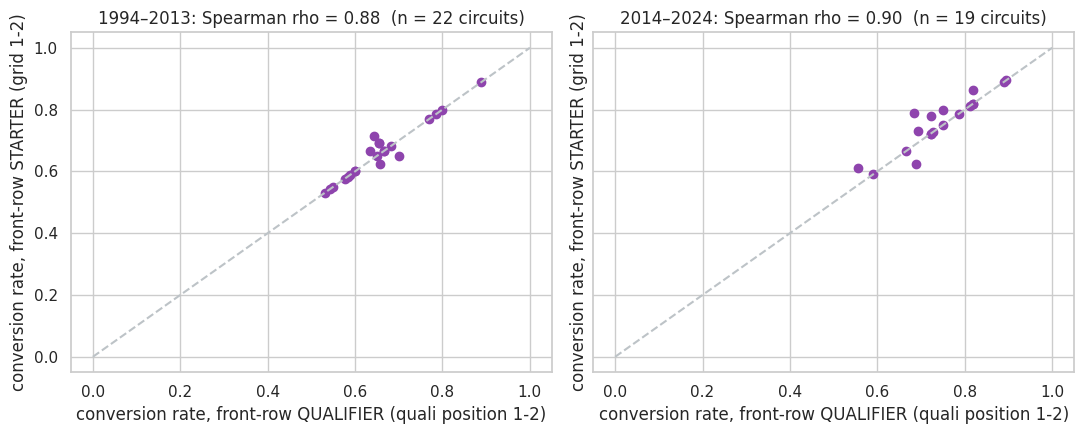

Mean absolute difference between the two definitions' circuit rates: 0.016
Points on the dashed diagonal = both definitions agree; spread around it = grid penalties change the picture.


In [31]:
# How much does the definition (qualifying position vs grid) change the circuit ranking?
both = conv_grid.merge(conv_quali, on=["era", "circuitId", "circuit_name"], suffixes=("_grid", "_quali"))
both = both[both["meets_min_grid"] & both["meets_min_quali"]]

rho_def = {}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, era in zip(axes, [ERA_A, ERA_B]):
    d = both[both["era"] == era]
    rho_def[era] = safe_spearman(d["rate_grid"], d["rate_quali"])
    ax.scatter(d["rate_quali"], d["rate_grid"], color="#8e44ad")
    ax.plot([0, 1], [0, 1], color="#bdc3c7", linestyle="--")
    ax.set_title(f"{era}: Spearman rho = {fmt_rho(rho_def[era])}  (n = {len(d)} circuits)")
    ax.set_xlabel("conversion rate, front-row QUALIFIER (quali position 1-2)")
    ax.set_ylabel("conversion rate, front-row STARTER (grid 1-2)")
plt.tight_layout()
plt.show()

diff = (both["rate_grid"] - both["rate_quali"]).abs()
print(f"Mean absolute difference between the two definitions' circuit rates: {diff.mean():.3f}")
print("Points on the dashed diagonal = both definitions agree; spread around it = grid penalties change the picture.")

Circuits ranked in both eras: 14
Spearman rank correlation between eras  (grid definition): 0.21   (quali definition): 0.14


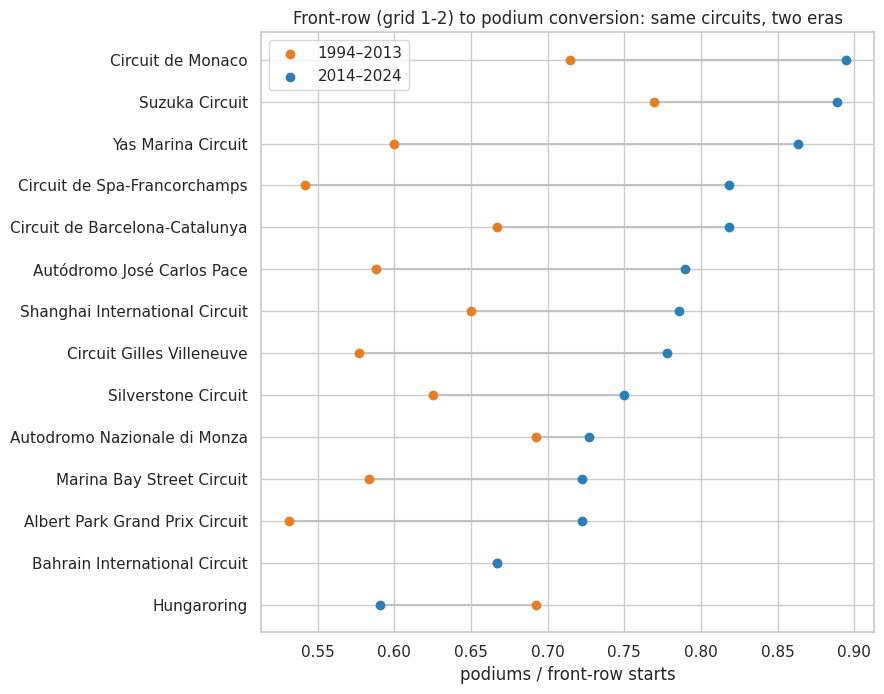

Biggest risers (rank improved from 1994–2013 to 2014–2024):


,circuit_name,rate_a,rate_b,rank_a,rank_b,rank_change
7,Circuit de Spa-Francorchamps,0.542,0.818,13.0,4.0,9.0
13,Yas Marina Circuit,0.600,0.864,9.0,3.0,6.0
4,Circuit Gilles Villeneuve,0.577,0.778,12.0,8.0,4.0


Biggest fallers:


,circuit_name,rate_a,rate_b,rank_a,rank_b,rank_change
6,Hungaroring,0.692,0.591,3.0,14.0,-11.0
1,Bahrain International Circuit,0.667,0.667,5.0,13.0,-8.0
8,Autodromo Nazionale di Monza,0.692,0.727,3.0,10.0,-7.0


In [32]:
def era_compare(conv):
    """Circuits ranked in BOTH eras: rate and rank in each era, plus rank-order (Spearman) correlation."""
    ok = conv[conv["meets_min"]]
    wide = (ok.pivot(index=["circuitId", "circuit_name"], columns="era", values="rate")
              .dropna().reset_index().rename(columns={ERA_A: "rate_a", ERA_B: "rate_b"}))
    wide["rank_a"] = wide["rate_a"].rank(ascending=False, method="min")
    wide["rank_b"] = wide["rate_b"].rank(ascending=False, method="min")
    wide["rank_change"] = wide["rank_a"] - wide["rank_b"]           # positive = moved UP in the later era
    wide.columns.name = None
    rho = safe_spearman(wide["rate_a"], wide["rate_b"])
    return wide, rho


wide_grid, rho_grid = era_compare(conv_grid)
wide_quali, rho_quali = era_compare(conv_quali)
n_common = len(wide_grid)

print(f"Circuits ranked in both eras: {n_common}")
print(f"Spearman rank correlation between eras  (grid definition): {fmt_rho(rho_grid)}   (quali definition): {fmt_rho(rho_quali)}")

if n_common:
    dumbbell_plot(wide_grid, "circuit_name", "rate_a", "rate_b", ERA_A, ERA_B,
                  "Front-row (grid 1-2) to podium conversion: same circuits, two eras",
                  "podiums / front-row starts")
    cols = ["circuit_name", "rate_a", "rate_b", "rank_a", "rank_b", "rank_change"]
    risers = wide_grid[wide_grid["rank_change"] > 0].sort_values("rank_change", ascending=False).head(3)
    fallers = wide_grid[wide_grid["rank_change"] < 0].sort_values("rank_change").head(3)
    print(f"Biggest risers (rank improved from {ERA_A} to {ERA_B}):")
    display(risers[cols].round(3) if len(risers) else pd.DataFrame({"note": ["no circuit moved up"]}))
    print("Biggest fallers:")
    display(fallers[cols].round(3) if len(fallers) else pd.DataFrame({"note": ["no circuit moved down"]}))

In [33]:
def top_text(conv, era, k=3):
    t = conv[(conv["era"] == era) & conv["meets_min"]].sort_values("rate", ascending=False).head(k)
    return "; ".join(f"**{r.circuit_name}** {r.rate:.0%} ({int(r.podiums)}/{int(r.starts)})" for r in t.itertuples())


def stability_word(rho):
    if np.isnan(rho):
        return "could not be assessed"
    return "largely stable" if rho >= 0.7 else ("only moderately stable" if rho >= 0.4 else "substantially reshuffled")


overall = q1[q1["front_row_grid"]].groupby("era")["podium"].mean()
rd = [v for v in rho_def.values() if not np.isnan(v)]
def_effect = "a little" if (rd and min(rd) >= 0.8) else ("noticeably" if rd else "to an extent that could not be assessed")
med_n = conv_grid[conv_grid["meets_min"]]["starts"].median()

display(Markdown(f"""
### Answer to Q1

**Which circuits convert a front-row start into a podium most often?** Using the actual starting grid (grid 1-2), the best converting circuits were
- **{ERA_A}:** {top_text(conv_grid, ERA_A)}
- **{ERA_B}:** {top_text(conv_grid, ERA_B)}

(rate = podiums / front-row starts, with the sample size in brackets). Across all circuits in the data a front-row start led to a podium {overall.get(ERA_A, float('nan')):.0%} of the time in {ERA_A} and {overall.get(ERA_B, float('nan')):.0%} in {ERA_B}.

**Does the ranking change after 2014?** For the {n_common} circuits ranked in both eras the rank-order correlation is rho = {fmt_rho(rho_grid)} (grid definition) and {fmt_rho(rho_quali)} (qualifying definition), so the ranking is **{stability_word(rho_grid)}**. See the dumbbell plot for the circuits that moved most. With a median of only {med_n:.0f} front-row starts per circuit and era, the confidence intervals are wide and neighbouring circuits are statistically hard to tell apart; only large moves should be read as real.

**Qualifying position vs grid.** The two definitions agree on {agree:.0%} of rows; the circuit-level rank correlation between the two definitions is {fmt_rho(rho_def[ERA_A])} ({ERA_A}) and {fmt_rho(rho_def[ERA_B])} ({ERA_B}). Grid penalties therefore change *who* is on the front row but, at circuit level, change the ranking only {def_effect}.

**Grain / missingness / cutoff.** One row per driver per race; races without qualifying data (all seasons before {int(q1['year'].min())}, plus some races in {len(partial)} later seasons) are excluded for both definitions, which is why the earlier era is "{ERA_A}"; qualifying position and grid are known before the race.
"""))


### Answer to Q1

**Which circuits convert a front-row start into a podium most often?** Using the actual starting grid (grid 1-2), the best converting circuits were
- **1994–2013:** **Circuit de Nevers Magny-Cours** 89% (16/18); **Indianapolis Motor Speedway** 80% (8/10); **Istanbul Park** 79% (11/14)
- **2014–2024:** **Circuit de Monaco** 89% (17/19); **Suzuka Circuit** 89% (16/18); **Yas Marina Circuit** 86% (19/22)

(rate = podiums / front-row starts, with the sample size in brackets). Across all circuits in the data a front-row start led to a podium 65% of the time in 1994–2013 and 76% in 2014–2024.

**Does the ranking change after 2014?** For the 14 circuits ranked in both eras the rank-order correlation is rho = 0.21 (grid definition) and 0.14 (qualifying definition), so the ranking is **substantially reshuffled**. See the dumbbell plot for the circuits that moved most. With a median of only 20 front-row starts per circuit and era, the confidence intervals are wide and neighbouring circuits are statistically hard to tell apart; only large moves should be read as real.

**Qualifying position vs grid.** The two definitions agree on 99% of rows; the circuit-level rank correlation between the two definitions is 0.88 (1994–2013) and 0.90 (2014–2024). Grid penalties therefore change *who* is on the front row but, at circuit level, change the ranking only a little.

**Grain / missingness / cutoff.** One row per driver per race; races without qualifying data (all seasons before 1994, plus some races in 8 later seasons) are excluded for both definitions, which is why the earlier era is "1994–2013"; qualifying position and grid are known before the race.


## 11. Q2 — Home-Country Podium Advantage
Question: do drivers podium more often at a circuit in their home country after controlling for starting position? We report the raw comparison,grid-band comparisons with confidence intervals,and logistic-regression odds ratios before and after controlling for grid position and decade. Driver nationality is an imperfect proxy for home country,so mapping coverage and exclusions are reported explicitly.


In [34]:
def normalize_label(value):
    if pd.isna(value):
        return None
    return " ".join(str(value).strip().casefold().replace("-", " ").split())


# nationality (as written in drivers.csv, normalised) -> country name (as written in circuits.csv, normalised)
NATIONALITY_TO_COUNTRY = {
    "british": "united kingdom", "dutch": "netherlands", "german": "germany", "spanish": "spain",
    "finnish": "finland", "brazilian": "brazil", "australian": "australia", "french": "france",
    "italian": "italy", "mexican": "mexico", "canadian": "canada", "japanese": "japan",
    "belgian": "belgium", "austrian": "austria", "swiss": "switzerland", "swedish": "sweden",
    "danish": "denmark", "american": "united states", "argentine": "argentina", "argentinian": "argentina",
    "colombian": "colombia", "venezuelan": "venezuela", "new zealander": "new zealand",
    "south african": "south africa", "russian": "russia", "polish": "poland", "portuguese": "portugal",
    "hungarian": "hungary", "irish": "ireland", "indian": "india", "malaysian": "malaysia", "thai": "thailand",
    "monegasque": "monaco", "chilean": "chile", "uruguayan": "uruguay", "rhodesian": "rhodesia",
    "indonesian": "indonesia", "czech": "czech republic", "liechtensteiner": "liechtenstein",
    "chinese": "china", "moroccan": "morocco", "turkish": "turkey", "east german": "east germany",
    "hong kong": "hong kong",
}
# circuit country labels that differ from the names above
CIRCUIT_COUNTRY_ALIASES = {
    "uk": "united kingdom", "great britain": "united kingdom", "usa": "united states",
    "united states of america": "united states", "uae": "united arab emirates", "korea": "south korea",
    "republic of korea": "south korea",
}


def home_countries(nationality):
    """'American-Italian' -> {'united states', 'italy'}. Parts we cannot map are ignored (and reported below)."""
    if pd.isna(nationality):
        return frozenset()
    found = {NATIONALITY_TO_COUNTRY.get(normalize_label(p)) for p in str(nationality).split("-")}
    return frozenset(c for c in found if c)


def unmapped_parts(nationality):
    return [normalize_label(p) for p in str(nationality).split("-")
            if normalize_label(p) not in NATIONALITY_TO_COUNTRY]


drv = clean["drivers"][["driverId", "nationality"]].copy()
drv["home_set"] = drv["nationality"].map(home_countries)
drv["unmapped"] = drv["nationality"].map(unmapped_parts)

entries_per_driver = driver_race.groupby("driverId").size()
unmapped_rows = drv[drv["unmapped"].map(len) > 0].copy()
unmapped_rows["entries"] = unmapped_rows["driverId"].map(entries_per_driver).fillna(0).astype(int)
unmapped_report = (unmapped_rows.groupby("nationality")
                   .agg(drivers=("driverId", "nunique"), entries=("entries", "sum"))
                   .sort_values("entries", ascending=False))

circuits_norm = clean["circuits"][["circuitId", "country"]].copy()
circuits_norm["country_norm"] = circuits_norm["country"].map(normalize_label).replace(CIRCUIT_COUNTRY_ALIASES)

print("Nationalities (or parts of them) with NO country mapping, review this list:")
display(unmapped_report if len(unmapped_report) else pd.DataFrame({"note": ["every nationality is mapped"]}))
print("Circuit countries in the dataset (after aliasing):")
print(sorted(circuits_norm["country_norm"].dropna().unique()))
print("\nRule of thumb: an unmapped nationality is only a problem if its country appears in the circuit list above.")

Nationalities (or parts of them) with NO country mapping, review this list:


,note
0,every nationality is mapped


Circuit countries in the dataset (after aliasing):
['argentina', 'australia', 'austria', 'azerbaijan', 'bahrain', 'belgium', 'brazil', 'canada', 'china', 'france', 'germany', 'hungary', 'india', 'italy', 'japan', 'malaysia', 'mexico', 'monaco', 'morocco', 'netherlands', 'portugal', 'qatar', 'russia', 'saudi arabia', 'singapore', 'south africa', 'south korea', 'spain', 'sweden', 'switzerland', 'turkey', 'united arab emirates', 'united kingdom', 'united states']

Rule of thumb: an unmapped nationality is only a problem if its country appears in the circuit list above.


In [35]:
home_all = (driver_race[["raceId", "driverId", "circuitId", "year", "grid", "podium"]]
            .merge(drv[["driverId", "home_set"]], on="driverId", how="left", validate="many_to_one")
            .merge(circuits_norm[["circuitId", "country_norm"]], on="circuitId", how="left", validate="many_to_one"))
assert len(home_all) == len(driver_race)

# Exclusions, counted one reason at a time (each row is counted under the first reason that applies).
m_unmapped = home_all["home_set"].map(lambda s: len(s) if isinstance(s, frozenset) else 0) == 0
step1 = home_all[~m_unmapped]
m_nocountry = step1["country_norm"].isna()
step2 = step1[~m_nocountry]
m_pit = ~(step2["grid"] > 0)
home_data = step2[~m_pit].copy()

print(f"Entries in the modeling table                       : {len(home_all):,}")
print(f"  excluded: driver nationality not mapped           : {int(m_unmapped.sum()):,}")
print(f"  excluded: circuit has no country                  : {int(m_nocountry.sum()):,}")
print(f"  excluded: pit-lane start / no grid slot (grid==0) : {int(m_pit.sum()):,}")
print(f"Entries used in this analysis                       : {len(home_data):,}")

home_data["home_match"] = [c in s for c, s in zip(home_data["country_norm"], home_data["home_set"])]
home_data["grid_band"] = pd.cut(home_data["grid"], bins=[0, 2, 5, 10, 20, float("inf")],
                                labels=["1–2", "3–5", "6–10", "11–20", "21+"], include_lowest=True)

n_home = int(home_data["home_match"].sum())
print(f"\nNationality-country matches: {n_home:,} entries across {home_data.loc[home_data.home_match, 'driverId'].nunique():,} drivers "
      f"({n_home / len(home_data):.1%} of entries). Other entries: {len(home_data) - n_home:,}.")
unadj_home = home_data.loc[home_data.home_match, "podium"].mean()
unadj_away = home_data.loc[~home_data.home_match, "podium"].mean()
print(f"UNADJUSTED podium rate: home {unadj_home:.3f} vs away {unadj_away:.3f}  "
      f"(this raw gap is what the question warns against reading without controlling for grid)")

Entries in the modeling table                       : 24,967
  excluded: driver nationality not mapped           : 0
  excluded: circuit has no country                  : 0
  excluded: pit-lane start / no grid slot (grid==0) : 87
Entries used in this analysis                       : 24,880

Nationality-country matches: 2,303 entries across 602 drivers (9.3% of entries). Other entries: 22,577.
UNADJUSTED podium rate: home 0.116 vs away 0.139  (this raw gap is what the question warns against reading without controlling for grid)


,grid_band,home_n,home_rate,away_n,away_rate,diff,diff_lo,diff_hi
0,1–2,178,0.556,2058,0.606,-0.050,-0.127,0.024
1,3–5,251,0.390,3114,0.351,0.040,-0.021,0.104
2,6–10,480,0.096,5126,0.114,-0.018,-0.043,0.013
3,11–20,965,0.020,9809,0.020,-0.000,-0.008,0.011
4,21+,429,0.009,2470,0.005,0.004,-0.002,0.019


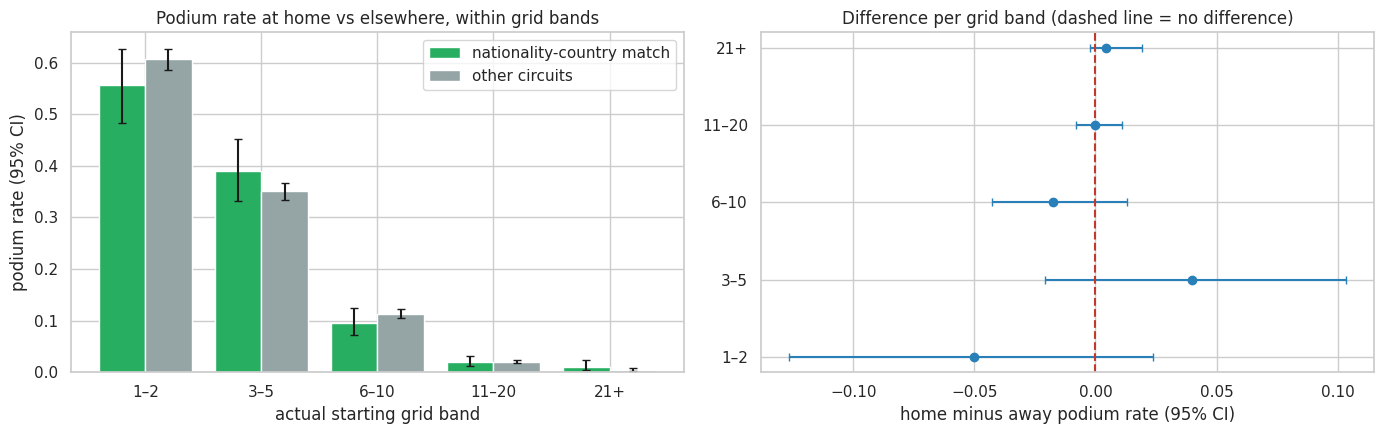

In [36]:
rows = []
for band, g in home_data.groupby("grid_band", observed=True):
    h, a = g[g["home_match"]], g[~g["home_match"]]
    n1, k1, n0, k0 = len(h), int(h["podium"].sum()), len(a), int(a["podium"].sum())
    if n1 == 0 or n0 == 0:
        continue
    p1, p0 = k1 / n1, k0 / n0
    h_lo, h_hi = wilson_ci(k1, n1)
    a_lo, a_hi = wilson_ci(k0, n0)
    # Newcombe interval for (home rate - away rate), built from the two Wilson intervals. Unlike the textbook
    # formula it does not collapse to a single point when a group has 0 podiums.
    d = p1 - p0
    d_lo = d - np.sqrt((p1 - h_lo) ** 2 + (a_hi - p0) ** 2)
    d_hi = d + np.sqrt((h_hi - p1) ** 2 + (p0 - a_lo) ** 2)
    rows.append({"grid_band": str(band), "home_n": n1, "home_rate": p1, "home_lo": float(h_lo), "home_hi": float(h_hi),
                 "away_n": n0, "away_rate": p0, "away_lo": float(a_lo), "away_hi": float(a_hi),
                 "diff": d, "diff_lo": float(d_lo), "diff_hi": float(d_hi)})
band_tbl = pd.DataFrame(rows)
display(band_tbl[["grid_band", "home_n", "home_rate", "away_n", "away_rate", "diff", "diff_lo", "diff_hi"]].round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(len(band_tbl))
axes[0].bar(x - 0.2, band_tbl["home_rate"], width=0.4, label="nationality-country match", color="#27ae60",
            yerr=[band_tbl["home_rate"] - band_tbl["home_lo"], band_tbl["home_hi"] - band_tbl["home_rate"]], capsize=3)
axes[0].bar(x + 0.2, band_tbl["away_rate"], width=0.4, label="other circuits", color="#95a5a6",
            yerr=[band_tbl["away_rate"] - band_tbl["away_lo"], band_tbl["away_hi"] - band_tbl["away_rate"]], capsize=3)
axes[0].set_xticks(x)
axes[0].set_xticklabels(band_tbl["grid_band"])
axes[0].set_xlabel("actual starting grid band")
axes[0].set_ylabel("podium rate (95% CI)")
axes[0].set_title("Podium rate at home vs elsewhere, within grid bands")
axes[0].legend()

axes[1].errorbar(band_tbl["diff"], x, xerr=[band_tbl["diff"] - band_tbl["diff_lo"], band_tbl["diff_hi"] - band_tbl["diff"]],
                 fmt="o", color="#2980b9", capsize=3)
axes[1].axvline(0, color="#c0392b", linestyle="--")
axes[1].set_yticks(x)
axes[1].set_yticklabels(band_tbl["grid_band"])
axes[1].set_xlabel("home minus away podium rate (95% CI)")
axes[1].set_title("Difference per grid band (dashed line = no difference)")
plt.tight_layout()
plt.show()

,model,odds_ratio,ci_low,ci_high,p_value,converged
0,unadjusted,0.812,0.711,0.926,0.002,True
1,controls for grid,0.969,0.837,1.122,0.673,True
2,controls for grid + decade,0.938,0.804,1.095,0.418,True


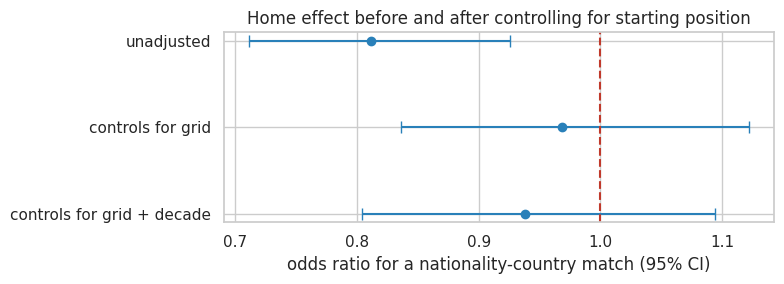

In [37]:
# One adjusted number: logistic regression  podium ~ home + grid (finely binned) [+ decade].
# The exp(coefficient of 'home') is an odds ratio: 1 = no difference, > 1 = home entries podium more often at the same grid.
# Standard errors are clustered by race, because drivers in the same race are not independent observations.
import statsmodels.formula.api as smf

model_df = home_data.copy()
model_df["home"] = model_df["home_match"].astype(int)
model_df["grid_cat"] = pd.cut(model_df["grid"], bins=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 15, np.inf]).astype(str)
model_df["decade"] = (model_df["year"] // 10 * 10).astype(int)

specs = {
    "unadjusted": "podium ~ home",
    "controls for grid": "podium ~ home + C(grid_cat)",
    "controls for grid + decade": "podium ~ home + C(grid_cat) + C(decade)",
}
groups = model_df["raceId"].to_numpy()
rows = []
for name, formula in specs.items():
    fit = smf.logit(formula, data=model_df).fit(disp=0, cov_type="cluster", cov_kwds={"groups": groups})
    ci = fit.conf_int().loc["home"]
    rows.append({"model": name, "odds_ratio": float(np.exp(fit.params["home"])),
                 "ci_low": float(np.exp(ci[0])), "ci_high": float(np.exp(ci[1])), "p_value": float(fit.pvalues["home"]),
                 "converged": bool(fit.mle_retvals.get("converged", True))})
or_tbl = pd.DataFrame(rows)
display(or_tbl.round(3))

fig, ax = plt.subplots(figsize=(8, 3))
y = np.arange(len(or_tbl))[::-1]
ax.errorbar(or_tbl["odds_ratio"], y, xerr=[or_tbl["odds_ratio"] - or_tbl["ci_low"], or_tbl["ci_high"] - or_tbl["odds_ratio"]],
            fmt="o", color="#2980b9", capsize=4)
ax.axvline(1, color="#c0392b", linestyle="--")
ax.set_yticks(y)
ax.set_yticklabels(or_tbl["model"])
ax.set_xlabel("odds ratio for a nationality-country match (95% CI)")
ax.set_title("Home effect before and after controlling for starting position")
plt.tight_layout()
plt.show()

In [38]:
r_un = or_tbl[or_tbl["model"] == "unadjusted"].iloc[0]
r_g = or_tbl[or_tbl["model"] == "controls for grid"].iloc[0]
r_gd = or_tbl[or_tbl["model"] == "controls for grid + decade"].iloc[0]


def verdict(r):
    if r["ci_low"] <= 1 <= r["ci_high"]:
        return "no statistically detectable difference"
    return "a significantly higher chance of a podium" if r["odds_ratio"] > 1 else "a significantly lower chance of a podium"


signs = band_tbl["diff"].apply(np.sign)
mixed = "mixed (some bands positive, some negative)" if signs.nunique() > 1 else "consistent in direction"

display(Markdown(f"""
### Answer to Q2

**Raw comparison (no control).** Entries where nationality matches the circuit's country podiumed {unadj_home:.1%} of the time vs {unadj_away:.1%} elsewhere (odds ratio {r_un.odds_ratio:.2f}, 95% CI {r_un.ci_low:.2f}-{r_un.ci_high:.2f}). This gap mixes two things: whether the driver is racing at home and how far forward he starts.

**After controlling for starting position.** Comparing home and away entries that start from the same grid positions, the odds ratio is **{r_g.odds_ratio:.2f}** (95% CI {r_g.ci_low:.2f}-{r_g.ci_high:.2f}, p = {r_g.p_value:.2f}): **{verdict(r_g)}**. Adding the decade as a further control gives {r_gd.odds_ratio:.2f} (95% CI {r_gd.ci_low:.2f}-{r_gd.ci_high:.2f}), i.e. {verdict(r_gd)}. The band-by-band differences are {mixed}, and most intervals contain zero (see the plots).

**Limitations.** Nationality is only a proxy for home. {int(m_unmapped.sum()):,} entries were dropped because the nationality could not be mapped (see the review table above), and {int(m_pit.sum()):,} pit-lane starts were dropped because they have no comparable grid slot. The adjustment controls for grid (and decade) only; constructor strength and driver skill are not controlled for. This is descriptive evidence, not a causal effect of "home advantage".

**Grain / missingness / cutoff.** One row per driver per race; exclusions are counted above; nationality, circuit and grid are all known before the race.
"""))


### Answer to Q2

**Raw comparison (no control).** Entries where nationality matches the circuit's country podiumed 11.6% of the time vs 13.9% elsewhere (odds ratio 0.81, 95% CI 0.71-0.93). This gap mixes two things: whether the driver is racing at home and how far forward he starts.

**After controlling for starting position.** Comparing home and away entries that start from the same grid positions, the odds ratio is **0.97** (95% CI 0.84-1.12, p = 0.67): **no statistically detectable difference**. Adding the decade as a further control gives 0.94 (95% CI 0.80-1.09), i.e. no statistically detectable difference. The band-by-band differences are mixed (some bands positive, some negative), and most intervals contain zero (see the plots).

**Limitations.** Nationality is only a proxy for home. 0 entries were dropped because the nationality could not be mapped (see the review table above), and 87 pit-lane starts were dropped because they have no comparable grid slot. The adjustment controls for grid (and decade) only; constructor strength and driver skill are not controlled for. This is descriptive evidence, not a causal effect of "home advantage".

**Grain / missingness / cutoff.** One row per driver per race; exclusions are counted above; nationality, circuit and grid are all known before the race.


## 12. Q3 — Mechanical Retirement Rates
Question: which constructor lineages have the highest mechanical-retirement rates in 2014–2021 versus 2022–2024? The denominator is race starts,not only retirements. Status labels are classified with transparent text rules; ambiguous component failures and generic “Retired” labels are audited separately,with sensitivity analysis and confidence intervals.


Every status used in 2014-2024 (65 labels) with the category our rules assign. REVIEW THIS TABLE:


,category,status,race_starts
5,"ambiguous component (tyre, wheel, wing, floor)",Wheel,11
1,"ambiguous component (tyre, wheel, wing, floor)",Puncture,7
3,"ambiguous component (tyre, wheel, wing, floor)",Tyre,4
4,"ambiguous component (tyre, wheel, wing, floor)",Undertray,4
0,"ambiguous component (tyre, wheel, wing, floor)",Front wing,3
...,...,...,...
51,mechanical,Spark plugs,1
61,mechanical,Water pump,1
63,unknown cause (e.g. generic 'Retired'),Retired,49
62,unknown cause (e.g. generic 'Retired'),Drivetrain,1



Race starts per category, 2014-2024:
category
finished (incl. lapped)                           3825
mechanical                                         361
crash / driver / regulation                        326
unknown cause (e.g. generic 'Retired')              51
ambiguous component (tyre, wheel, wing, floor)      35


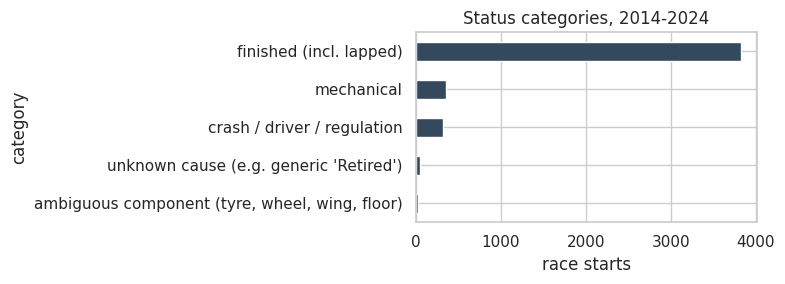


Starts that ended with an unknown cause (NOT counted as mechanical): 51 (1.1% of all starts) -> a source of under-counting, reported as a limitation.
Mechanical-status starts where the driver was still classified as a finisher (failure late in the race): 38


In [39]:
import re

retirement_data = (
    driver_race[["raceId", "driverId", "constructorId", "year", "statusId", "position"]]
    .merge(clean["status"][["statusId", "status"]], on="statusId", how="left", validate="many_to_one")
    .merge(clean["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor"}),
           on="constructorId", how="left", validate="many_to_one")
)
retirement_data = retirement_data[retirement_data["year"].between(2014, 2024)].copy()
retirement_data["period"] = np.where(retirement_data["year"] <= 2021, "2014–2021", "2022–2024")

CAT_FIN = "finished (incl. lapped)"
CAT_CRASH = "crash / driver / regulation"
CAT_AMBIG = "ambiguous component (tyre, wheel, wing, floor)"
CAT_MECH = "mechanical"
CAT_UNK = "unknown cause (e.g. generic 'Retired')"

# Ordered rules: the FIRST matching rule wins, so crash/regulation wording beats component wording.
STATUS_RULES = [
    (CAT_FIN, r"^finished$|^\+\d+ laps?$"),
    (CAT_CRASH, r"accident|collision|spun off|crash|disqualif|excluded|withdr|did not|illness|injur|driver|safety|"
                r"fatal|penalty|black flag|out of fuel|damage|debris"),
    (CAT_AMBIG, r"puncture|\btyres?\b|\btires?\b|wheel|wing|undertray|floor|bodywork"),
    (CAT_MECH, r"engine|power unit|power loss|\bers\b|\bmgu|gearbox|transmission|clutch|hydraulic|electrical|electronic|"
               r"brake|suspension|radiator|cooling|overheat|\boil\b|\bwater\b|fuel pressure|fuel pump|fuel system|"
               r"fuel leak|turbo|battery|alternator|differential|drive ?shaft|halfshaft|crankshaft|throttle|steering|"
               r"exhaust|pneumatic|vibration|spark|ignition|injection|fire|mechanical|technical|track rod|chassis"),
]


def classify_status(status):
    s = str(status).strip().casefold()
    for category, pattern in STATUS_RULES:
        if re.search(pattern, s):
            return category
    return CAT_UNK


# unit tests of the classifier (they run every time: a wrong rule stops the notebook instead of silently skewing results)
assert classify_status("Retired") == CAT_UNK             # must NOT be caught by the tyre rule ("re-tire-d")
assert classify_status("Engine") == CAT_MECH
assert classify_status("Power Unit") == CAT_MECH
assert classify_status("Collision damage") == CAT_CRASH
assert classify_status("Out of fuel") == CAT_CRASH
assert classify_status("Fuel pressure") == CAT_MECH
assert classify_status("Puncture") == CAT_AMBIG
assert classify_status("+2 Laps") == CAT_FIN

retirement_data["category"] = retirement_data["status"].map(classify_status)
retirement_data["mech_strict"] = retirement_data["category"] == CAT_MECH
retirement_data["mech_broad"] = retirement_data["category"].isin([CAT_MECH, CAT_AMBIG])

audit = (retirement_data.groupby(["category", "status"]).size().rename("race_starts").reset_index()
         .sort_values(["category", "race_starts"], ascending=[True, False]))
print(f"Every status used in 2014-2024 ({len(audit)} labels) with the category our rules assign. REVIEW THIS TABLE:")
display(audit)

cat_counts = retirement_data["category"].value_counts()
print("\nRace starts per category, 2014-2024:")
print(cat_counts.to_string())

fig, ax = plt.subplots(figsize=(8, 3))
cat_counts.sort_values().plot.barh(ax=ax, color="#34495e")
ax.set_xlabel("race starts")
ax.set_title("Status categories, 2014-2024")
plt.tight_layout()
plt.show()

n_unknown = int(cat_counts.get(CAT_UNK, 0))
print(f"\nStarts that ended with an unknown cause (NOT counted as mechanical): {n_unknown} "
      f"({n_unknown / len(retirement_data):.1%} of all starts) -> a source of under-counting, reported as a limitation.")
n_mech_classified = int(((retirement_data["category"] == CAT_MECH) & retirement_data["position"].notna()).sum())
print(f"Mechanical-status starts where the driver was still classified as a finisher (failure late in the race): {n_mech_classified}")

Registered constructor names merged into a lineage (review):


,team_lineage,constructor,first_year,last_year,race_starts
1,Enstone: Lotus F1 / Renault / Alpine,Alpine F1 Team,2021,2024,179
2,Enstone: Lotus F1 / Renault / Alpine,Lotus F1,2014,2015,75
3,Enstone: Lotus F1 / Renault / Alpine,Renault,2016,2020,199
5,Force India / Racing Point / Aston Martin,Aston Martin,2021,2024,178
6,Force India / Racing Point / Aston Martin,Force India,2014,2018,198
7,Force India / Racing Point / Aston Martin,Racing Point,2019,2020,75
9,Marussia / Manor,Manor Marussia,2015,2016,77
10,Marussia / Manor,Marussia,2014,2014,31
14,Sauber / Alfa Romeo,Alfa Romeo,2019,2023,208
15,Sauber / Alfa Romeo,Sauber,2014,2024,247



Top 10 team lineages by mechanical-retirement rate, per period:


,period,team_lineage,race_starts,events,rate,ci_low,ci_high
0,2014–2021,Caterham,33,7,0.212,0.107,0.378
10,2014–2021,Toro Rosso / AlphaTauri / RB,319,45,0.141,0.107,0.184
1,2014–2021,Enstone: Lotus F1 / Renault / Alpine,318,42,0.132,0.099,0.174
6,2014–2021,McLaren,316,41,0.130,0.097,0.171
8,2014–2021,Red Bull,318,34,0.107,0.078,0.146
9,2014–2021,Sauber / Alfa Romeo,319,25,0.078,0.054,0.113
4,2014–2021,Haas F1 Team,241,18,0.075,0.048,0.115
11,2014–2021,Williams,319,23,0.072,0.049,0.106
5,2014–2021,Marussia / Manor,108,7,0.065,0.032,0.128
3,2014–2021,Force India / Racing Point / Aston Martin,317,18,0.057,0.036,0.088


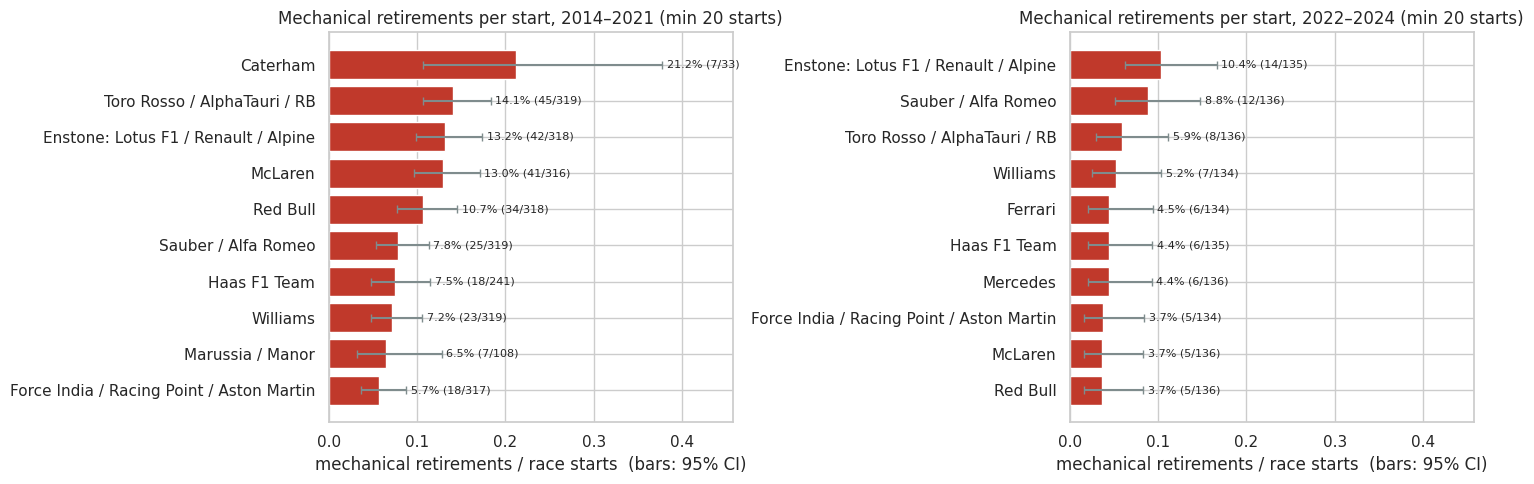

In [40]:
# Team lineage: merge renamed/sold teams so the two periods can be compared. Edit this list if you disagree.
LINEAGE_RULES = [
    (("toro rosso", "alphatauri", "rb f1"), "Toro Rosso / AlphaTauri / RB"),
    (("lotus f1", "renault", "alpine"), "Enstone: Lotus F1 / Renault / Alpine"),
    (("force india", "racing point", "aston martin"), "Force India / Racing Point / Aston Martin"),
    (("sauber", "alfa romeo"), "Sauber / Alfa Romeo"),
    (("marussia", "manor"), "Marussia / Manor"),
]


def lineage_of(name):
    n = str(name).casefold()
    for keys, lineage in LINEAGE_RULES:
        if any(k in n for k in keys):
            return lineage
    return name


retirement_data["team_lineage"] = retirement_data["constructor"].map(lineage_of)
mapping_tbl = (retirement_data.groupby(["team_lineage", "constructor"])
               .agg(first_year=("year", "min"), last_year=("year", "max"), race_starts=("raceId", "size")).reset_index())
print("Registered constructor names merged into a lineage (review):")
display(mapping_tbl[mapping_tbl["team_lineage"] != mapping_tbl["constructor"]])

MIN_STARTS = 20      # minimum starts in a period for a team to be ranked


def rate_table(df, group_col, flag_col, min_starts):
    g = (df.groupby(["period", group_col])
           .agg(race_starts=("raceId", "size"), events=(flag_col, "sum")).reset_index())
    g["rate"] = g["events"] / g["race_starts"]
    g["ci_low"], g["ci_high"] = wilson_ci(g["events"], g["race_starts"])
    return g[g["race_starts"] >= min_starts].copy()


rates = rate_table(retirement_data, "team_lineage", "mech_strict", MIN_STARTS)
print("\nTop 10 team lineages by mechanical-retirement rate, per period:")
top = (rates.sort_values(["period", "rate"], ascending=[True, False]).groupby("period", group_keys=False).head(10))
display(top.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=True)
for ax, period in zip(axes, ["2014–2021", "2022–2024"]):
    d = rates[rates["period"] == period].sort_values("rate", ascending=False).head(10).sort_values("rate")
    ax.barh(d["team_lineage"], d["rate"], xerr=[d["rate"] - d["ci_low"], d["ci_high"] - d["rate"]],
            color="#c0392b", ecolor="#7f8c8d", capsize=3)
    for y, (_, r) in enumerate(d.iterrows()):
        ax.text(r["ci_high"] + 0.005, y, f'{r["rate"]:.1%} ({int(r["events"])}/{int(r["race_starts"])})', va="center", fontsize=8)
    ax.set_xlim(0, max(0.35, rates["ci_high"].max() + 0.08))
    ax.set_title(f"Mechanical retirements per start, {period} (min {MIN_STARTS} starts)")
    ax.set_xlabel("mechanical retirements / race starts  (bars: 95% CI)")
plt.tight_layout()
plt.show()

Team lineages ranked in BOTH periods: 10


,team_lineage,2014–2021,2022–2024,change
4,McLaren,0.130,0.037,-0.093
8,Toro Rosso / AlphaTauri / RB,0.141,0.059,-0.082
6,Red Bull,0.107,0.037,-0.070
3,Haas F1 Team,0.075,0.044,-0.030
0,Enstone: Lotus F1 / Renault / Alpine,0.132,0.104,-0.028
9,Williams,0.072,0.052,-0.020
2,Force India / Racing Point / Aston Martin,0.057,0.037,-0.019
1,Ferrari,0.047,0.045,-0.002
5,Mercedes,0.038,0.044,0.007
7,Sauber / Alfa Romeo,0.078,0.088,0.010


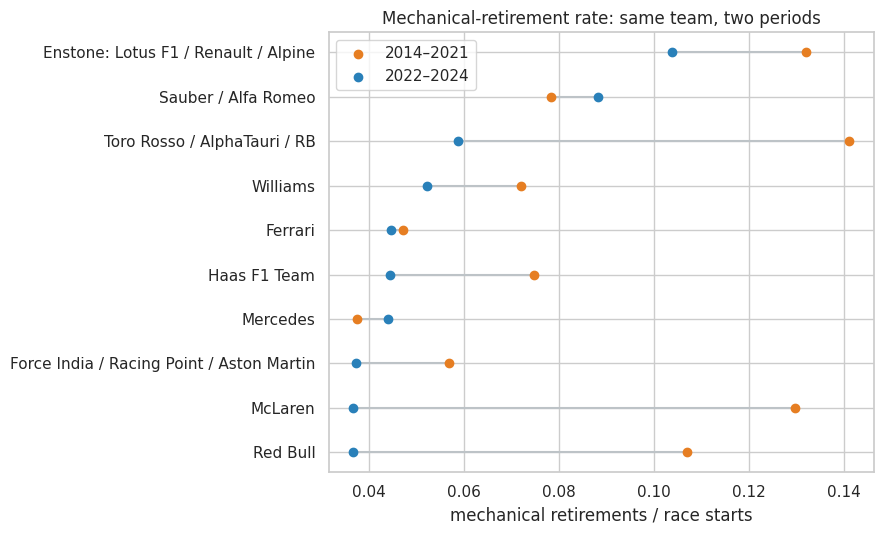


All teams pooled:


,period,race_starts,events,rate,ci_low,ci_high
0,2014–2021,3246,287,0.0884,0.0791,0.0987
1,2022–2024,1352,74,0.0547,0.0438,0.0682


Spearman correlation of team rankings, strict vs broad definition: {'2014–2021': '0.99', '2022–2024': '0.95'}

Top 10 by REGISTERED constructor name (no merging), per period:


,period,constructor,race_starts,events,rate,ci_low,ci_high
4,2014–2021,Caterham,33,7,0.212,0.107,0.378
8,2014–2021,Lotus F1,75,13,0.173,0.104,0.274
17,2014–2021,Toro Rosso,242,38,0.157,0.117,0.208
15,2014–2021,Renault,199,26,0.131,0.091,0.185
11,2014–2021,McLaren,316,41,0.130,0.097,0.171
14,2014–2021,Red Bull,318,34,0.107,0.078,0.146
16,2014–2021,Sauber,199,21,0.106,0.070,0.156
10,2014–2021,Marussia,31,3,0.097,0.033,0.249
1,2014–2021,AlphaTauri,77,7,0.091,0.045,0.176
13,2014–2021,Racing Point,75,6,0.080,0.037,0.164


In [41]:
# (1) Same team lineage in both periods
wide = (rates.pivot(index="team_lineage", columns="period", values="rate").dropna().reset_index())
wide.columns.name = None
print(f"Team lineages ranked in BOTH periods: {len(wide)}")
if len(wide):
    wide["change"] = wide["2022–2024"] - wide["2014–2021"]
    display(wide.sort_values("change").round(3))
    dumbbell_plot(wide, "team_lineage", "2014–2021", "2022–2024", "2014–2021", "2022–2024",
                  "Mechanical-retirement rate: same team, two periods", "mechanical retirements / race starts")

# (2) Pooled rate over all teams, per period
pooled = (retirement_data.groupby("period").agg(race_starts=("raceId", "size"), events=("mech_strict", "sum")).reset_index())
pooled["rate"] = pooled["events"] / pooled["race_starts"]
pooled["ci_low"], pooled["ci_high"] = wilson_ci(pooled["events"], pooled["race_starts"])
print("\nAll teams pooled:")
display(pooled.round(4))

# (3) Sensitivity: does the ranking depend on counting ambiguous labels (tyre, wheel, wing...) as mechanical?
rates_broad = rate_table(retirement_data, "team_lineage", "mech_broad", MIN_STARTS)
rho_sens = {}
for period in ["2014–2021", "2022–2024"]:
    a = rates[rates["period"] == period].set_index("team_lineage")["rate"]
    b = rates_broad[rates_broad["period"] == period].set_index("team_lineage")["rate"]
    common = a.index.intersection(b.index)
    rho_sens[period] = safe_spearman(a[common], b[common])
print("Spearman correlation of team rankings, strict vs broad definition:", {k: fmt_rho(v) for k, v in rho_sens.items()})

# (4) Same ranking by registered constructor name (no lineage merging)
rates_raw = rate_table(retirement_data, "constructor", "mech_strict", MIN_STARTS)
print("\nTop 10 by REGISTERED constructor name (no merging), per period:")
display(rates_raw.sort_values(["period", "rate"], ascending=[True, False]).groupby("period", group_keys=False).head(10).round(3))

In [42]:
def top_teams(period, k=3):
    t = rates[rates["period"] == period].sort_values("rate", ascending=False).head(k)
    return "; ".join(f"**{r.team_lineage}** {r.rate:.1%} ({int(r.events)}/{int(r.race_starts)})" for r in t.itertuples())


pooled_i = pooled.set_index("period")
p1, p2 = pooled_i.loc["2014–2021"], pooled_i.loc["2022–2024"]
overlap = not (p1.ci_low > p2.ci_high or p2.ci_low > p1.ci_high)
direction = "fell" if p2.rate < p1.rate else "rose"

display(Markdown(f"""
### Answer to Q3

**Highest mechanical-retirement rates** (mechanical retirements per race start, teams with at least {MIN_STARTS} starts in the period; counts in brackets):
- **2014-2021:** {top_teams('2014–2021')}
- **2022-2024:** {top_teams('2022–2024')}

**Did it change between the two periods?** Pooled over all teams, the mechanical-retirement rate {direction} from {p1.rate:.1%} ({int(p1.events)}/{int(p1.race_starts)} starts) in 2014-2021 to {p2.rate:.1%} ({int(p2.events)}/{int(p2.race_starts)}) in 2022-2024; the 95% intervals {'overlap, so the overall change is not clearly distinguishable from noise' if overlap else 'do not overlap, so the overall change is unlikely to be noise'}. Team-level rates rest on small counts (single digits to a few dozen events), so only large gaps should be read as real; the plot shows the intervals.

**Robustness.** The team ranking correlates at rho = {fmt_rho(rho_sens['2014–2021'])} (2014-2021) and {fmt_rho(rho_sens['2022–2024'])} (2022-2024) between the strict definition and a broad one that also counts ambiguous labels (tyre, wheel, wing, floor), so the conclusions do not hinge on that choice. Merging renamed teams into lineages (mapping printed above) is a judgement call; the ranking by registered constructor name is shown as well.

**Limitations.** The classification is a text-based proxy for the brief's definition, not an official FIA taxonomy. {n_unknown} starts ended with the generic status "Retired" (cause unknown) and are not counted, so rates are slight under-estimates. Some "mechanical" statuses may follow contact damage that the status text does not reveal.

**Grain / missingness / cutoff.** One row per driver start (non-starters removed); the status text is post-race information used only to describe the past.
"""))


### Answer to Q3

**Highest mechanical-retirement rates** (mechanical retirements per race start, teams with at least 20 starts in the period; counts in brackets):
- **2014-2021:** **Caterham** 21.2% (7/33); **Toro Rosso / AlphaTauri / RB** 14.1% (45/319); **Enstone: Lotus F1 / Renault / Alpine** 13.2% (42/318)
- **2022-2024:** **Enstone: Lotus F1 / Renault / Alpine** 10.4% (14/135); **Sauber / Alfa Romeo** 8.8% (12/136); **Toro Rosso / AlphaTauri / RB** 5.9% (8/136)

**Did it change between the two periods?** Pooled over all teams, the mechanical-retirement rate fell from 8.8% (287/3246 starts) in 2014-2021 to 5.5% (74/1352) in 2022-2024; the 95% intervals do not overlap, so the overall change is unlikely to be noise. Team-level rates rest on small counts (single digits to a few dozen events), so only large gaps should be read as real; the plot shows the intervals.

**Robustness.** The team ranking correlates at rho = 0.99 (2014-2021) and 0.95 (2022-2024) between the strict definition and a broad one that also counts ambiguous labels (tyre, wheel, wing, floor), so the conclusions do not hinge on that choice. Merging renamed teams into lineages (mapping printed above) is a judgement call; the ranking by registered constructor name is shown as well.

**Limitations.** The classification is a text-based proxy for the brief's definition, not an official FIA taxonomy. 51 starts ended with the generic status "Retired" (cause unknown) and are not counted, so rates are slight under-estimates. Some "mechanical" statuses may follow contact damage that the status text does not reveal.

**Grain / missingness / cutoff.** One row per driver start (non-starters removed); the status text is post-race information used only to describe the past.


# 13. Task 2 — Interpretation and Limitations

The three questions use different populations and outcome definitions,so their estimates should not be compared as though they were one experiment. The generated answer blocks above report the results from the actual data loaded at runtime; no numeric conclusion is hard-coded.

- **Q1:** qualifying coverage is historically uneven. The grid-based estimate uses actual starting grid positions in races with qualifying-table coverage; the qualifying-position sensitivity analysis only counts known qualifying positions as candidates for the front row. Circuit-era rankings require a minimum sample and should be interpreted with their confidence intervals.
- **Q2:** nationality is a proxy for home country,not a verified residence or birthplace. Unmapped nationality components and races without a circuit country are excluded and counted. Grid-band comparisons can be noisy in sparse bands; logistic regression adjusts for grid and decade but does not control fully for driver skill,constructor strength,or all historical changes.
- **Q3:** the status-to-cause mapping is a transparent text-based approximation,not an official failure taxonomy. Generic “Retired” outcomes are unknown,not automatically mechanical. The strict/broad sensitivity analysis shows how ambiguous tyre/wheel/wing/floor failures affect rankings. Team lineages across renames are documented as judgment calls.
- All three questions are descriptive. Their post-race labels are used only to analyze historical outcomes and never enter the predictive feature matrix. Confidence intervals quantify sampling uncertainty under the chosen definitions; they do not remove bias from coverage gaps or classification assumptions.


### Limitations common to all three questions
- All results are **descriptive**,not causal; the outcomes are used only in Task 2 and are excluded from model features.
- Per-circuit and per-team samples can be small; interpret rates with sample sizes and confidence intervals.
- Q1 depends on qualifying-table coverage and distinguishes qualifying order from the actual grid.
- Q2 depends on nationality-to-country mappings and controls only for measured grid position and decade.
- Q3 depends on a transparent but imperfect text-based classification of `status`,including an explicit unknown category and a broad-definition sensitivity check.

# 14. Tasks 1 & 2 — Final Checklist

- [x] EDA before and after cleaning,with plots.
- [x] Literal `\N` sentinels converted to missing values on working copies.
- [x] Dates and duration fields semantically typed;range and parsing checks shown.
- [x] Modeling grain validated as one row per `(raceId,driverId)`.
- [x] Duplicate shared-drive records handled by a deterministic,documented rule.
- [x] Non-starters excluded from the prediction population with counts reported.
- [x] Primary-key and foreign-key integrity audited.
- [x] All three data-engineering questions answered with tables,plots,and limitations.
- [x] Task 2 results remain separate from model predictors.


# Task 3 — Feature Selection & Engineering

We predict whether a driver finishes on the podium using only information available after the starting grid is fixed and before the race begins.

## 3.1 Prediction Cutoff and Leakage Rules

The prediction is made after the starting grid is fixed and before the race begins.

**Selected predictors**
- `grid`: actual starting grid position,known before the start.
- `driver_recent_podium_rate_5`: the driver's podium rate across the five previous race entries.
- `constructor_recent_podium_rate_5`: the constructor's average podium-entry rate across its five previous races.

**Never use as predictors:** current-race `position`,`positionOrder`,`points`,`laps`,`statusId`,`time`,`milliseconds`,`fastestLap`,pit-stop records,or current/post-race standings. These fields describe outcomes or events unavailable at the prediction cutoff.

Task 2 has its own historical analyses and does not feed the model feature matrix.

In [43]:
# Start Task 3 from the complete driver-race table created in the previous sections.
df = driver_race.copy()

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df.sort_values(["date", "raceId", "driverId"]).reset_index(drop=True)

print("Rows:", len(df))
print("Date range:", df["date"].min(), "to", df["date"].max())


Rows: 24967
Date range: 1950-05-13 00:00:00 to 2024-12-08 00:00:00


## 3.2 Candidate Features

The candidate set contains the actual starting grid position and two historical-form features. We use a compact feature set that is interpretable,available at the prediction cutoff,and can be audited for leakage. The feature plots below provide empirical evidence for each choice.

In [44]:
leakage_columns = [
    "position","positionOrder","points","laps","time","milliseconds",
    "fastestLap","rank","fastestLapTime","fastestLapSpeed","statusId"
]

print("Target:", "podium")
print("Grid available:", "grid" in df.columns)
print("Race-result columns excluded from features:")
print([c for c in leakage_columns if c in df.columns])


Target: podium
Grid available: True
Race-result columns excluded from features:
['position', 'positionOrder', 'points', 'laps', 'time', 'milliseconds', 'fastestLap', 'rank', 'fastestLapTime', 'fastestLapSpeed', 'statusId']


## 3.3 Exploratory Evidence

### 3.3.1 Grid Position


In [45]:
grid_eda = (
    df.groupby("grid")["podium"]
      .agg(["count","mean"])
      .reset_index()
)

display(grid_eda.head(20))


,grid,count,mean
0,0,87,0.000000
1,1,1119,0.644325
2,2,1117,0.560430
3,3,1122,0.466132
4,4,1126,0.342806
5,5,1117,0.251567
6,6,1119,0.186774
7,7,1125,0.130667
8,8,1115,0.100448
9,9,1128,0.083333


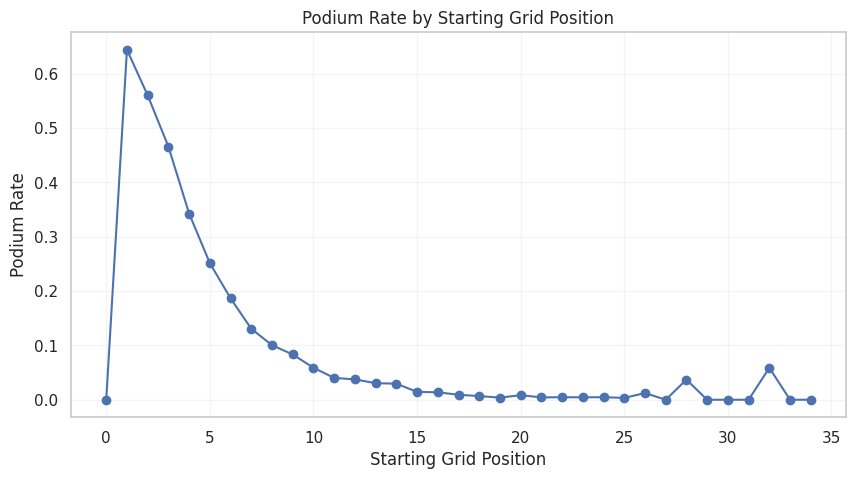

In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.plot(grid_eda["grid"],grid_eda["mean"],marker="o")
plt.xlabel("Starting Grid Position")
plt.ylabel("Podium Rate")
plt.title("Podium Rate by Starting Grid Position")
plt.grid(alpha=0.2)
plt.show()


**Reading the grid plot.** Podium probability falls steeply with grid position: pole (grid 1) converts 64.4% of the time, grid 2 56.0%, grid 3 46.6%, and by grid 10 it is only 5.9%. This strong, monotonic relationship is why grid is the main feature.

The 87 rows with `grid = 0` (pit-lane starts) have a podium rate of 0.000. Numerically 0 looks better than pole, so these rows are recoded to the back of the grid in Section 3.6 before modeling.

### 3.3.2 Why Historical Form Is Shifted

The current race outcome is used only as the label. Historical-form predictors are shifted by one race before rolling,so a driver's or constructor's current result cannot leak into its own feature. Constructor form is first aggregated at constructor–race level,then shifted,so a teammate's current-race result cannot leak into another teammate's feature.

### 3.3.3 Driver Historical Form

The feature uses only the driver's previous five race entries. The current race is excluded with `shift(1)`. The first five entries for a driver have no complete five-race history and remain missing until preprocessing.

In [47]:
df = df.sort_values(["date","raceId","driverId"]).reset_index(drop=True)

df["driver_recent_podium_rate_5"] = (
    df.groupby("driverId")["podium"]
      .transform(
          lambda s: s.shift(1)
                   .rolling(5,min_periods=5)
                   .mean()
      )
)

driver_form_eda = (
    df.dropna(subset=["driver_recent_podium_rate_5"])
      .groupby("driver_recent_podium_rate_5")["podium"]
      .agg(["count","mean"])
      .reset_index()
)

display(driver_form_eda.head(20))


,driver_recent_podium_rate_5,count,mean
0,0.0,14182,0.040897
1,0.2,3388,0.191558
2,0.4,2026,0.363771
3,0.6,1391,0.463695
4,0.8,818,0.584352
5,1.0,291,0.652921


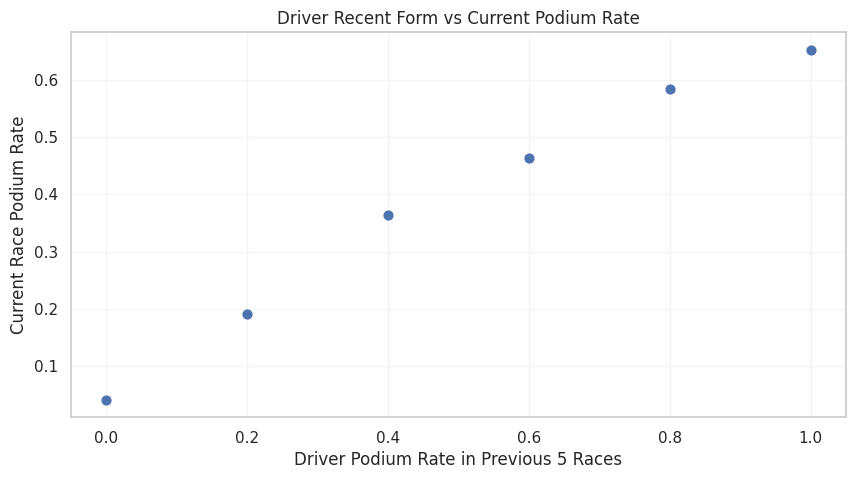

In [48]:
plt.figure(figsize=(10,5))
plt.scatter(
    driver_form_eda["driver_recent_podium_rate_5"],
    driver_form_eda["mean"],
    s=40
)
plt.xlabel("Driver Podium Rate in Previous 5 Races")
plt.ylabel("Current Race Podium Rate")
plt.title("Driver Recent Form vs Current Podium Rate")
plt.grid(alpha=0.2)
plt.show()


**Reading the driver-form plot.** The relationship is strong and monotonic:

| Driver podium rate in previous 5 races | Rows | Podium rate this race |
| --- | --- | --- |
| 0.0 | 14,182 | 4.1% |
| 0.2 | 3,388 | 19.2% |
| 0.4 | 2,026 | 36.4% |
| 0.6 | 1,391 | 46.4% |
| 0.8 | 818 | 58.4% |
| 1.0 | 291 | 65.3% |

A driver with podiums in all of his last five races is about 16 times more likely to podium than one with none. The window of five races (about a quarter of a modern season) was chosen to reflect recent form while still averaging over enough races to reduce noise from a single result.

### 3.3.4 Constructor Historical Form

Constructor form is first calculated at the constructor–race level. The rolling feature then uses the constructor's previous five races only. This avoids treating two teammates' results from the current race as historical information for one another.

In [49]:
constructor_race = (
    df.groupby(["constructorId","raceId","date"],as_index=False)
      .agg(constructor_podiums=("podium","sum"))
      .sort_values(["constructorId","date","raceId"])
      .reset_index(drop=True)
)

constructor_entries = (
    df.groupby(["constructorId","raceId"])["driverId"]
      .nunique()
      .rename("constructor_entries")
      .reset_index()
)

constructor_race = constructor_race.merge(
    constructor_entries,
    on=["constructorId","raceId"],
    how="left",
    validate="one_to_one"
)

constructor_race["constructor_podium_rate"] = (
    constructor_race["constructor_podiums"] /
    constructor_race["constructor_entries"]
)

constructor_race["constructor_recent_podium_rate_5"] = (
    constructor_race.groupby("constructorId")["constructor_podium_rate"]
      .transform(
          lambda s: s.shift(1)
                   .rolling(5,min_periods=5)
                   .mean()
      )
)

df = df.drop(columns=["constructor_recent_podium_rate_5"],errors="ignore")

df = df.merge(
    constructor_race[
        ["constructorId","raceId","constructor_recent_podium_rate_5"]
    ],
    on=["constructorId","raceId"],
    how="left",
    validate="many_to_one"
)

constructor_form_eda = (
    df.dropna(subset=["constructor_recent_podium_rate_5"])
      .groupby("constructor_recent_podium_rate_5")["podium"]
      .agg(["count","mean"])
      .reset_index()
)

display(constructor_form_eda.head(20))


,constructor_recent_podium_rate_5,count,mean
0,0.000000,12288,0.024495
1,0.016667,7,0.000000
2,0.018182,5,0.400000
3,0.020000,11,0.090909
4,0.020833,8,0.000000
5,0.025000,13,0.000000
6,0.028571,7,0.000000
7,0.033333,18,0.166667
8,0.033333,23,0.000000
9,0.038182,8,0.000000


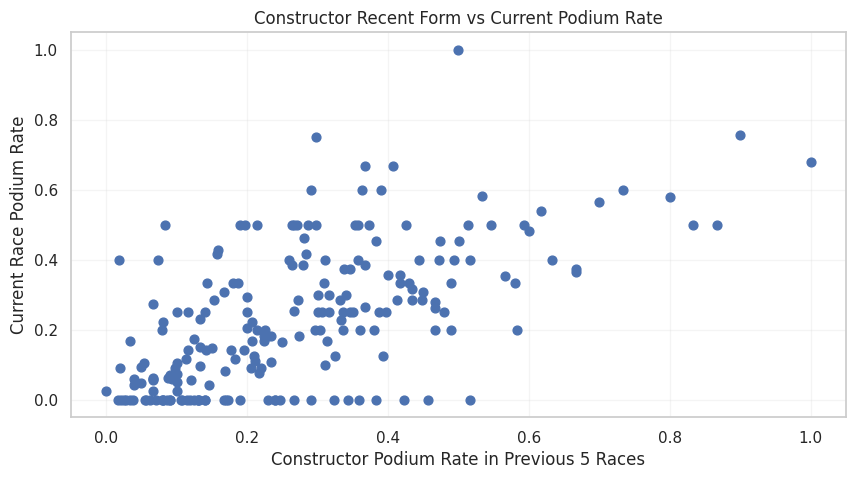

In [50]:
plt.figure(figsize=(10,5))
plt.scatter(
    constructor_form_eda["constructor_recent_podium_rate_5"],
    constructor_form_eda["mean"],
    s=40
)
plt.xlabel("Constructor Podium Rate in Previous 5 Races")
plt.ylabel("Current Race Podium Rate")
plt.title("Constructor Recent Form vs Current Podium Rate")
plt.grid(alpha=0.2)
plt.show()


**Reading the constructor-form plot.** Constructors with no podiums in their last five races (constructor form = 0, 12,288 rows) podium only 2.4% of the time, and the podium rate rises as constructor form rises. The scatter is noisy at intermediate values because each distinct rate value is plotted separately and many have fewer than 20 rows; the overall upward trend is what supports the feature. It captures car strength, which grid only partly reflects.

## 3.4 Feature Missingness & Coverage

Missing driver and constructor history is expected early in a driver's or constructor's history. These missing values are retained in the modeling table and handled by an imputer fitted on the training data only.


In [51]:
candidate_features = [
    "grid",
    "driver_recent_podium_rate_5",
    "constructor_recent_podium_rate_5"
]

coverage = pd.DataFrame({
    "missing": df[candidate_features].isna().sum(),
    "missing_rate": df[candidate_features].isna().mean(),
    "coverage": df[candidate_features].notna().mean()
})

display(coverage.sort_values("missing_rate"))


,missing,missing_rate,coverage
grid,0,0.000000,1.000000
constructor_recent_podium_rate_5,1398,0.055994,0.944006
driver_recent_podium_rate_5,2871,0.114992,0.885008


## 3.5 Final Feature Set

The final model uses exactly three pre-race features: actual grid position,driver recent form,and constructor recent form. Both historical-form features use prior races only.

**Why these three.**
- **Grid** has the strongest relationship with podiums in the EDA (Section 3.3.1) and is fixed before the start.
- **Driver form** and **constructor form** add information grid does not fully contain: a strong driver or car starting further back still podiums more often (Sections 3.3.3 and 3.3.4).

**Why qualifying position is not used.** Qualifying is available at the cutoff, but it adds almost nothing beyond grid and has poor coverage:
- The `qualifying` table only starts in 1994 and has partial coverage until 2002 (Section 2.3), so it would be missing for most of the training years (1950–2001).
- Where both exist, qualifying and grid agree on the front row for 99.3% of rows (Q1, Section 10). Grid already contains the qualifying result plus any penalties, so it is the more accurate pre-race signal.

**Why pre-race championship standings are not used.** Standings from the previous round would be leakage-safe, but they accumulate points over the whole season, so they mostly repeat what the five-race form features already capture, and they reset at every season start. We kept the feature set small and interpretable.

In [52]:
final_features = [
    "grid",
    "driver_recent_podium_rate_5",
    "constructor_recent_podium_rate_5"
]

print("Final features:")
for feature in final_features:
    print("-",feature)


Final features:
- grid
- driver_recent_podium_rate_5
- constructor_recent_podium_rate_5


## 3.6 Modeling Population

Rows with missing selected features are retained. Missing feature values are imputed using medians learned from the training set only. Rows are removed here only if the target is missing. This avoids unnecessarily discarding historical races because historical-form data is unavailable.

**Pit-lane starts (`grid = 0`).** In this dataset `grid = 0` means the driver started from the pit lane (or had no grid slot). The grid EDA above shows these starters have a podium rate of 0.000. If 0 were left as a number, the models would treat it as *better* than pole position (1). We therefore move every pit-lane start to the back of that race's grid: `grid = (highest grid slot in that race) + 1`. The highest grid slot is known before the start, so this stays within the pre-race cutoff. The recoding is applied before the train/validation/test split.

In [53]:
model_df = df[
    ["raceId", "driverId", "constructorId", "year", "round", "date", "podium"]
    + final_features
].copy()

before = len(model_df)

# Remove rows only when the target is missing.
model_df = model_df.dropna(subset=["podium"]).reset_index(drop=True)

print("Rows before filtering:", before)
print("Rows after filtering:", len(model_df))
print("Rows removed:", before - len(model_df))

# Pit-lane starts (grid = 0) go to the back of that race's grid (see markdown above).
pit_lane_start = model_df["grid"] == 0
back_of_grid = model_df.groupby("raceId")["grid"].transform("max") + 1
print("\nPit-lane starts (grid = 0) recoded to the back of the grid:", int(pit_lane_start.sum()))
print("Podium rate of these rows:", round(float(model_df.loc[pit_lane_start, "podium"].mean()), 4))
model_df.loc[pit_lane_start, "grid"] = back_of_grid[pit_lane_start]
assert (model_df["grid"] > 0).all(), "grid = 0 values remain after recoding"
print("Recoded grid range for these rows:",
      int(model_df.loc[pit_lane_start, "grid"].min()), "to", int(model_df.loc[pit_lane_start, "grid"].max()))

print("\nMissing feature values retained for preprocessing:")
display(model_df[final_features].isna().sum().to_frame("Missing values"))

Rows before filtering: 24967
Rows after filtering: 24967
Rows removed: 0

Pit-lane starts (grid = 0) recoded to the back of the grid: 87
Podium rate of these rows: 0.0
Recoded grid range for these rows: 17 to 27

Missing feature values retained for preprocessing:


,Missing values
grid,0
driver_recent_podium_rate_5,2871
constructor_recent_podium_rate_5,1398


## 3.7 Chronological Train / Validation / Test Split

The split is chronological so future races are not used to train the model.

**Why a chronological split.** The model is meant to predict podiums in races that have not happened yet, so it must be tested on seasons that come after the ones it learned from. A random split would mix races from the same season into training and testing, so the model would learn from "future" races and its scores would look better than they really are. Splitting by whole seasons also keeps every race entirely in one set.

**How the seasons are divided.** The 75 seasons are split 70% / 15% / 15% in time order:

| Set | Seasons | Rows | Podium rate |
| --- | --- | --- | --- |
| Train | 1950–2001 (52 seasons) | 15,704 | 13.1% |
| Validation | 2002–2012 (11 seasons) | 4,248 | 14.0% |
| Test | 2013–2024 (12 seasons) | 5,015 | 14.8% |

Validation is used to choose the model and the decision threshold; the test set (the most recent seasons) is used only once, for the final report. The podium rate is similar in all three sets, so the class balance does not change much over time.

In [54]:
model_df = model_df.sort_values(
    ["date","raceId","driverId"]
).reset_index(drop=True)

years = sorted(model_df["year"].dropna().unique())
assert len(years) >= 6, "Not enough distinct seasons for a chronological train/validation/test split."

train_end = int(len(years)*0.70)
val_end = int(len(years)*0.85)

train_years = years[:train_end]
val_years = years[train_end:val_end]
test_years = years[val_end:]

train_df = model_df[model_df["year"].isin(train_years)].copy()
val_df = model_df[model_df["year"].isin(val_years)].copy()
test_df = model_df[model_df["year"].isin(test_years)].copy()

print("Train:",train_years[0],"→",train_years[-1])
print("Validation:",val_years[0],"→",val_years[-1])
print("Test:",test_years[0],"→",test_years[-1])
assert train_years[-1] < val_years[0] and val_years[-1] < test_years[0], "Chronological split overlap detected."

print("\nRows:")
print("Train:",len(train_df))
print("Validation:",len(val_df))
print("Test:",len(test_df))


Train: 1950 → 2001
Validation: 2002 → 2012
Test: 2013 → 2024

Rows:
Train: 15704
Validation: 4248
Test: 5015


In [55]:
X_train = train_df[final_features].copy()
y_train = train_df["podium"].copy()

X_val = val_df[final_features].copy()
y_val = val_df["podium"].copy()

X_test = test_df[final_features].copy()
y_test = test_df["podium"].copy()

print("X_train:",X_train.shape)
print("X_val:",X_val.shape)
print("X_test:",X_test.shape)


X_train: (15704, 3)
X_val: (4248, 3)
X_test: (5015, 3)


## 3.8 Preprocessing

The imputer and scaler are fitted only on the training set and then applied to validation/test.


In [56]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

preprocessor = Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])

X_train_prepared = preprocessor.fit_transform(X_train)
X_val_prepared = preprocessor.transform(X_val)
X_test_prepared = preprocessor.transform(X_test)

print("Prepared train:",X_train_prepared.shape)
print("Prepared validation:",X_val_prepared.shape)
print("Prepared test:",X_test_prepared.shape)


Prepared train: (15704, 3)
Prepared validation: (4248, 3)
Prepared test: (5015, 3)


### 3.8.1 Effect of Preprocessing on the Data

This step shows what imputation and scaling do to the training features: the number of missing values, the range and the distribution at each stage. All statistics come from the training set only.

Training medians used for imputation:
  grid: 12.0000
  driver_recent_podium_rate_5: 0.0000
  constructor_recent_podium_rate_5: 0.0667

StandardScaler parameters (learned on imputed training data):
  grid: mean = 12.3833, std = 7.1570
  driver_recent_podium_rate_5: mean = 0.1238, std = 0.2176
  constructor_recent_podium_rate_5: mean = 0.1337, std = 0.1811


,stage,feature,missing,mean,std,min,median,max
0,1. Raw,grid,0,12.3833,7.1572,1.0000,12.0000,34.0000
1,1. Raw,driver_recent_podium_rate_5,2421,0.1464,0.2295,0.0000,0.0000,1.0000
2,1. Raw,constructor_recent_podium_rate_5,1185,0.1391,0.1873,0.0000,0.0667,0.9000
3,2. After median imputation,grid,0,12.3833,7.1572,1.0000,12.0000,34.0000
4,2. After median imputation,driver_recent_podium_rate_5,0,0.1238,0.2176,0.0000,0.0000,1.0000
5,2. After median imputation,constructor_recent_podium_rate_5,0,0.1337,0.1811,0.0000,0.0667,0.9000
6,3. After StandardScaler,grid,0,0.0000,1.0000,-1.5905,-0.0536,3.0204
7,3. After StandardScaler,driver_recent_podium_rate_5,0,0.0000,1.0000,-0.5691,-0.5691,4.0270
8,3. After StandardScaler,constructor_recent_podium_rate_5,0,-0.0000,1.0000,-0.7382,-0.3700,4.2322


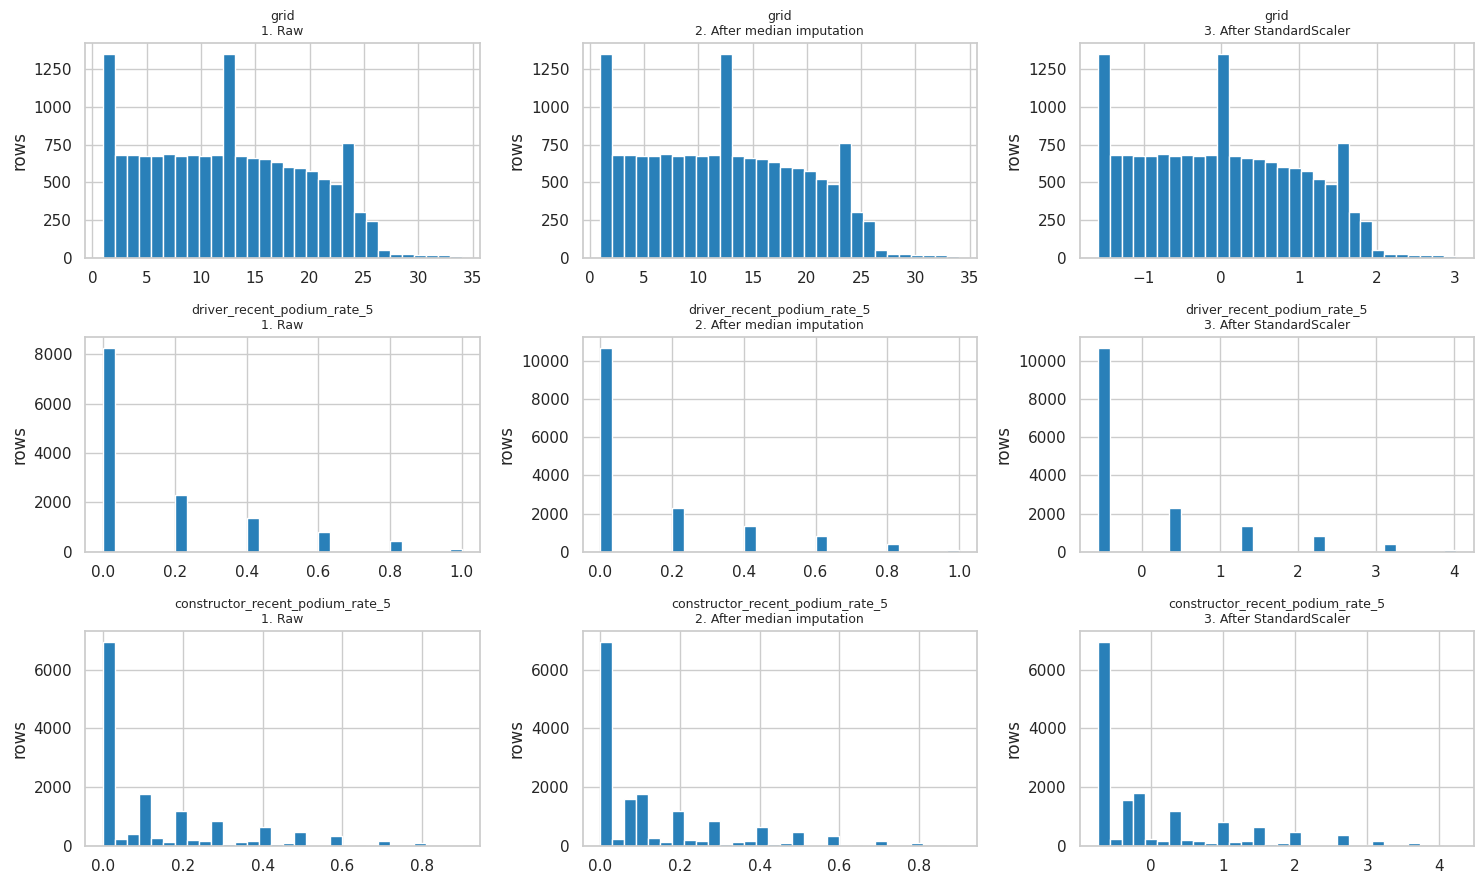

In [57]:
imputer_fitted = preprocessor.named_steps["imputer"]
scaler_fitted = preprocessor.named_steps["scaler"]

X_train_imputed = pd.DataFrame(imputer_fitted.transform(X_train), columns=final_features, index=X_train.index)
X_train_scaled = pd.DataFrame(X_train_prepared, columns=final_features, index=X_train.index)

print("Training medians used for imputation:")
for feature, value in zip(final_features, imputer_fitted.statistics_):
    print(f"  {feature}: {value:.4f}")

print("\nStandardScaler parameters (learned on imputed training data):")
for feature, mean, scale in zip(final_features, scaler_fitted.mean_, scaler_fitted.scale_):
    print(f"  {feature}: mean = {mean:.4f}, std = {scale:.4f}")

stages = [
    ("1. Raw", X_train),
    ("2. After median imputation", X_train_imputed),
    ("3. After StandardScaler", X_train_scaled),
]

summary_rows = []
for stage_name, data in stages:
    for feature in final_features:
        col = data[feature]
        summary_rows.append({
            "stage": stage_name,
            "feature": feature,
            "missing": int(col.isna().sum()),
            "mean": col.mean(),
            "std": col.std(),
            "min": col.min(),
            "median": col.median(),
            "max": col.max(),
        })

preprocessing_effect = pd.DataFrame(summary_rows)
display(preprocessing_effect.round(4))

fig, axes = plt.subplots(len(final_features), len(stages), figsize=(15, 9))
for r, feature in enumerate(final_features):
    for c, (stage_name, data) in enumerate(stages):
        ax = axes[r, c]
        ax.hist(data[feature].dropna(), bins=30, color="#2980b9")
        ax.set_title(f"{feature}\n{stage_name}", fontsize=9)
        ax.set_ylabel("rows")
plt.tight_layout()
plt.show()

**What the preprocessing changed.**

- **Imputation** fills every missing form value with the training median, so the missing count drops to 0. Because most drivers and constructors score 0 podiums in a five-race window, the medians are at or near 0, so a missing history is treated as "no recent podiums". This adds rows to the bar at 0 but does not change the range.
- **Scaling** subtracts the training mean and divides by the training standard deviation. Every feature ends with mean 0 and standard deviation 1, but the **shape of each distribution is unchanged**: scaling only shifts and stretches the axis.
- Scaling matters for Logistic Regression, the SVM, KNN and the neural network, which are sensitive to feature magnitude. Tree models (Decision Tree, Random Forest, Gradient Boosting, XGBoost) give the same splits with or without scaling.
- The validation and test sets are transformed with these same training medians, means and standard deviations; nothing is re-fitted on them.

## 3.9 Final Modeling Table


In [58]:
final_modeling_table = model_df[
    ["raceId","driverId","constructorId","year","round","date","podium"]
    + final_features
].copy()

display(final_modeling_table.head())

print("Final modeling table:",final_modeling_table.shape)


,raceId,driverId,constructorId,year,round,date,podium,grid,driver_recent_podium_rate_5,constructor_recent_podium_rate_5
0,833,579,51,1950,1,1950-05-13,0,3,NaN,NaN
1,833,589,105,1950,1,1950-05-13,0,11,NaN,NaN
2,833,619,151,1950,1,1950-05-13,0,13,NaN,NaN
3,833,627,154,1950,1,1950-05-13,0,9,NaN,NaN
4,833,640,105,1950,1,1950-05-13,0,8,NaN,NaN


Final modeling table: (24967, 10)


## 3.10 Final Leakage & Data Audit


In [59]:
duplicate_driver_race_rows = int(final_modeling_table.duplicated(subset=["raceId", "driverId"]).sum())
print("Duplicate driver-race rows:", duplicate_driver_race_rows)
assert duplicate_driver_race_rows == 0, "Modeling table is not unique by raceId and driverId."

print("\nTarget values:", sorted(final_modeling_table["podium"].dropna().unique()))
assert set(final_modeling_table["podium"].dropna().unique()).issubset({0, 1})

print("\nMissing selected features before imputation:")
display(final_modeling_table[final_features].isna().sum().to_frame("missing"))

print("\nSelected features:", final_features)
assert set(final_features) == {"grid", "driver_recent_podium_rate_5", "constructor_recent_podium_rate_5"}

print("\nLeakage audit (none of these outcome columns may be predictors):")
for col in ["position", "positionOrder", "points", "laps", "time", "milliseconds", "fastestLap", "rank", "statusId"]:
    print(f"{col}:", "USED — ERROR" if col in final_features else "not used")
assert not set(final_features).intersection({"position", "positionOrder", "points", "laps", "time", "milliseconds", "fastestLap", "rank", "statusId"})

print("\nChronological split check:")
print("Train max date:", train_df["date"].max())
print("Validation min/max date:", val_df["date"].min(), "/", val_df["date"].max())
print("Test min date:", test_df["date"].min())
assert train_df["date"].max() < val_df["date"].min()
assert val_df["date"].max() < test_df["date"].min()

Duplicate driver-race rows: 0

Target values: [np.int64(0), np.int64(1)]

Missing selected features before imputation:


,missing
grid,0
driver_recent_podium_rate_5,2871
constructor_recent_podium_rate_5,1398



Selected features: ['grid', 'driver_recent_podium_rate_5', 'constructor_recent_podium_rate_5']

Leakage audit (none of these outcome columns may be predictors):
position: not used
positionOrder: not used
points: not used
laps: not used
time: not used
milliseconds: not used
fastestLap: not used
rank: not used
statusId: not used

Chronological split check:
Train max date: 2001-10-14 00:00:00
Validation min/max date: 2002-03-03 00:00:00 / 2012-11-25 00:00:00
Test min date: 2013-03-17 00:00:00


## 4.1 Modeling Setup

All candidate models use the same rows,three predictors,chronological split,and training-fitted preprocessing. **PR-AUC is the primary ranking metric** because podiums are the minority class; ROC-AUC is a secondary ranking metric. F1,precision,and recall describe decisions at a threshold selected using validation data only.

The model family includes multiple statistical machine-learning approaches and a shallow feed-forward neural network. We report five metrics (ROC-AUC,PR-AUC,F1,precision,recall) for training,validation,and test. Test scores are reported for transparency but are never used to select models,hyperparameters,or thresholds.

In [60]:
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score
)

## 4.2 Models

We compare nine well-known classification models:

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Gradient Boosting
5. XGBoost
6. Support Vector Machine
7. K-Nearest Neighbors
8. Naive Bayes
9. Shallow Neural Network

### Baseline

**Logistic Regression is the baseline.** It is the simplest reasonable model for a binary target: one weight per feature, no tuning, fully interpretable. Every other model is compared against it on validation PR-AUC. A more complex model is only worth keeping if it clearly beats this baseline.

### How the main models work and their limitations

**Logistic Regression (statistical model, baseline).** It computes a weighted sum of the three scaled features and passes it through the sigmoid function to get a podium probability. The weights are learned by maximising the likelihood of the training labels (with L2 regularisation).
*Limitations:* it can only learn a monotonic, roughly linear relationship in log-odds. It cannot model interactions (for example, grid mattering more for a strong constructor) unless they are added by hand, and it extrapolates outside the training range.

**Gradient Boosting (statistical model).** It builds 200 small decision trees (depth 3) one after another. Each new tree is fitted to the errors left by the trees before it, and the final prediction adds them up with a learning rate of 0.05.
*Limitations:* it has more hyperparameters, can overfit if trees are deep or numerous, is less interpretable than a linear model, and its probabilities are not always well calibrated. Tree models also cannot extrapolate beyond values seen in training.

**Shallow Neural Network (MLP).** One hidden layer with 32 ReLU units feeds a sigmoid output. It is trained with the Adam optimiser; early stopping holds out 10% of the training rows and stops when that score stops improving. One small hidden layer is enough for three input features: a deeper network would add parameters without adding information.
*Limitations:* results depend on the random initialisation (different seeds give slightly different scores), it needs scaled inputs, it is a black box, and the early-stopping hold-out is a random split, not a chronological one.

The other models (Decision Tree, Random Forest, XGBoost, SVM, KNN, Naive Bayes) are included as further statistical-model attempts so the comparison covers linear, tree-based, distance-based and probabilistic families.

In [61]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    "SVM": SVC(
        probability=True,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=15
    ),

    "Naive Bayes": GaussianNB(),

    "Shallow Neural Network": MLPClassifier(
        hidden_layer_sizes=(32,),
        max_iter=500,
        random_state=42,
        early_stopping=True
    )
}

## 4.3 XGBoost

XGBoost is a popular gradient-boosting algorithm for structured/tabular data.

In [62]:
try:
    from xgboost import XGBClassifier

    models["XGBoost"] = XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42
    )

    print("XGBoost added successfully.")

except ImportError:
    print("XGBoost is not installed,so it will be skipped.")

XGBoost added successfully.


## 4.4 Model Training

Each model is trained using the same training data.

The validation set is used for comparison,while the test set remains unseen until the final evaluation.

In [63]:
trained_models = {}

for name,model in models.items():
    print(f"Training {name}...")
    
    model.fit(X_train_prepared,y_train)
    trained_models[name] = model

print("\nFinished training",len(trained_models),"models.")

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training Gradient Boosting...
Training SVM...
Training KNN...
Training Naive Bayes...
Training Shallow Neural Network...
Training XGBoost...

Finished training 9 models.


## 4.5 Evaluation Metrics and Threshold Selection

ROC-AUC and PR-AUC use predicted probabilities and do not require a classification threshold. For F1,precision,and recall,the probability threshold is selected separately for each model by maximizing F1 on the validation set. That threshold is then frozen and applied to training,validation,and test. The test set is never used to choose a threshold.

In [64]:
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    precision_score, recall_score, precision_recall_curve
)


def choose_f1_threshold(model, X, y):
    """Choose a decision threshold by validation F1 only."""
    probabilities = model.predict_proba(X)[:, 1]
    precision, recall, thresholds = precision_recall_curve(y, probabilities)
    if len(thresholds) == 0:
        return 0.5, float(f1_score(y, (probabilities >= 0.5).astype(int), zero_division=0))
    f1_values = (2 * precision[:-1] * recall[:-1]) / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
    best_idx = int(np.nanargmax(f1_values))
    return float(thresholds[best_idx]), float(f1_values[best_idx])


def evaluate_model(model, X, y, threshold):
    probabilities = model.predict_proba(X)[:, 1]
    predictions = (probabilities >= threshold).astype(int)
    return {
        "ROC-AUC": roc_auc_score(y, probabilities),
        "PR-AUC": average_precision_score(y, probabilities),
        "F1": f1_score(y, predictions, zero_division=0),
        "Precision": precision_score(y, predictions, zero_division=0),
        "Recall": recall_score(y, predictions, zero_division=0),
    }


# Thresholds are chosen using validation data only.
model_thresholds = {}
for name, model in trained_models.items():
    model_thresholds[name], best_val_f1 = choose_f1_threshold(model, X_val_prepared, y_val)
    print(f"{name}: validation-selected threshold={model_thresholds[name]:.4f}; validation F1={best_val_f1:.4f}")

results = []
for name, model in trained_models.items():
    threshold = model_thresholds[name]
    train_metrics = evaluate_model(model, X_train_prepared, y_train, threshold)
    val_metrics = evaluate_model(model, X_val_prepared, y_val, threshold)
    test_metrics = evaluate_model(model, X_test_prepared, y_test, threshold)
    row = {"Model": name, "Validation-selected threshold": threshold}
    for split_name, metric_values in [("Train", train_metrics), ("Validation", val_metrics), ("Test", test_metrics)]:
        for metric_name, value in metric_values.items():
            row[f"{split_name} {metric_name}"] = value
    results.append(row)

results_df = pd.DataFrame(results)
display(results_df.sort_values("Validation PR-AUC", ascending=False).round(4))

Logistic Regression: validation-selected threshold=0.3372; validation F1=0.6482
Decision Tree: validation-selected threshold=0.3326; validation F1=0.6446
Random Forest: validation-selected threshold=0.3385; validation F1=0.6418
Gradient Boosting: validation-selected threshold=0.2983; validation F1=0.6486
SVM: validation-selected threshold=0.0925; validation F1=0.6262
KNN: validation-selected threshold=0.3333; validation F1=0.6067
Naive Bayes: validation-selected threshold=0.2051; validation F1=0.5868
Shallow Neural Network: validation-selected threshold=0.3640; validation F1=0.6032
XGBoost: validation-selected threshold=0.3362; validation F1=0.6408


,Model,Validation-selected threshold,Train ROC-AUC,Train PR-AUC,Train F1,Train Precision,Train Recall,Validation ROC-AUC,Validation PR-AUC,Validation F1,Validation Precision,Validation Recall,Test ROC-AUC,Test PR-AUC,Test F1,Test Precision,Test Recall
0,Logistic Regression,0.3372,0.8803,0.4898,0.5230,0.4993,0.5490,0.9139,0.6474,0.6482,0.5960,0.7104,0.9324,0.7029,0.6951,0.6340,0.7692
3,Gradient Boosting,0.2983,0.8894,0.5277,0.5529,0.4782,0.6553,0.9170,0.6363,0.6486,0.5520,0.7862,0.9362,0.7032,0.6868,0.5872,0.8273
8,XGBoost,0.3362,0.8923,0.5366,0.5570,0.5025,0.6248,0.9154,0.6344,0.6408,0.5589,0.7508,0.9370,0.7101,0.6911,0.6074,0.8016
2,Random Forest,0.3385,0.9016,0.5740,0.5713,0.5259,0.6252,0.9160,0.6329,0.6418,0.5672,0.7391,0.9366,0.7015,0.6863,0.6077,0.7881
7,Shallow Neural Network,0.3640,0.8656,0.4672,0.5128,0.4708,0.5631,0.9024,0.6046,0.6032,0.5278,0.7037,0.9283,0.6737,0.6659,0.5832,0.7760
1,Decision Tree,0.3326,0.8818,0.4861,0.5409,0.4844,0.6121,0.9119,0.6034,0.6446,0.5628,0.7542,0.9372,0.6842,0.6946,0.6176,0.7935
4,SVM,0.0925,0.7585,0.4376,0.5327,0.4869,0.5879,0.8403,0.6007,0.6262,0.5488,0.7290,0.8669,0.6692,0.6813,0.5962,0.7949
6,Naive Bayes,0.2051,0.8726,0.4552,0.5190,0.4162,0.6893,0.8997,0.5707,0.5868,0.4663,0.7912,0.9239,0.6376,0.6527,0.5251,0.8623
5,KNN,0.3333,0.8780,0.4923,0.5465,0.4498,0.6961,0.8949,0.5570,0.6067,0.4926,0.7896,0.9180,0.6202,0.6462,0.5258,0.8381


## 4.6 Model Comparison

The validation results are used to compare the models and identify the strongest candidate before looking at the final unseen test performance.

In [65]:
validation_columns = [
    "Model", "Validation-selected threshold", "Validation ROC-AUC",
    "Validation PR-AUC", "Validation F1", "Validation Precision", "Validation Recall"
]
validation_comparison = (
    results_df[validation_columns]
    .sort_values("Validation PR-AUC", ascending=False)
    .reset_index(drop=True)
)
display(validation_comparison.round(4))

print("Primary metric: validation PR-AUC. Secondary ranking metric: validation ROC-AUC.")
print("Threshold-dependent metrics use each model's validation-selected threshold.")

,Model,Validation-selected threshold,Validation ROC-AUC,Validation PR-AUC,Validation F1,Validation Precision,Validation Recall
0,Logistic Regression,0.3372,0.9139,0.6474,0.6482,0.5960,0.7104
1,Gradient Boosting,0.2983,0.9170,0.6363,0.6486,0.5520,0.7862
2,XGBoost,0.3362,0.9154,0.6344,0.6408,0.5589,0.7508
3,Random Forest,0.3385,0.9160,0.6329,0.6418,0.5672,0.7391
4,Shallow Neural Network,0.3640,0.9024,0.6046,0.6032,0.5278,0.7037
5,Decision Tree,0.3326,0.9119,0.6034,0.6446,0.5628,0.7542
6,SVM,0.0925,0.8403,0.6007,0.6262,0.5488,0.7290
7,Naive Bayes,0.2051,0.8997,0.5707,0.5868,0.4663,0.7912
8,KNN,0.3333,0.8949,0.5570,0.6067,0.4926,0.7896


Primary metric: validation PR-AUC. Secondary ranking metric: validation ROC-AUC.
Threshold-dependent metrics use each model's validation-selected threshold.


## 4.7 Overall Validation Ranking

Models are ranked using their validation ROC-AUC,PR-AUC,and F1 scores.

PR-AUC is particularly useful because podium finishes are much less common than non-podium finishes.

In [66]:
ranking = validation_comparison.copy()
ranking.insert(0, "Rank by validation PR-AUC", range(1, len(ranking) + 1))
display(ranking.round(4))

print("Do not choose the final model by test scores. The ranking above is based on validation PR-AUC only.")

,Rank by validation PR-AUC,Model,Validation-selected threshold,Validation ROC-AUC,Validation PR-AUC,Validation F1,Validation Precision,Validation Recall
0,1,Logistic Regression,0.3372,0.9139,0.6474,0.6482,0.5960,0.7104
1,2,Gradient Boosting,0.2983,0.9170,0.6363,0.6486,0.5520,0.7862
2,3,XGBoost,0.3362,0.9154,0.6344,0.6408,0.5589,0.7508
3,4,Random Forest,0.3385,0.9160,0.6329,0.6418,0.5672,0.7391
4,5,Shallow Neural Network,0.3640,0.9024,0.6046,0.6032,0.5278,0.7037
5,6,Decision Tree,0.3326,0.9119,0.6034,0.6446,0.5628,0.7542
6,7,SVM,0.0925,0.8403,0.6007,0.6262,0.5488,0.7290
7,8,Naive Bayes,0.2051,0.8997,0.5707,0.5868,0.4663,0.7912
8,9,KNN,0.3333,0.8949,0.5570,0.6067,0.4926,0.7896


Do not choose the final model by test scores. The ranking above is based on validation PR-AUC only.


## 4.8 Validation Metric Comparison

The following plots compare the models across ROC-AUC,PR-AUC,and F1 score.

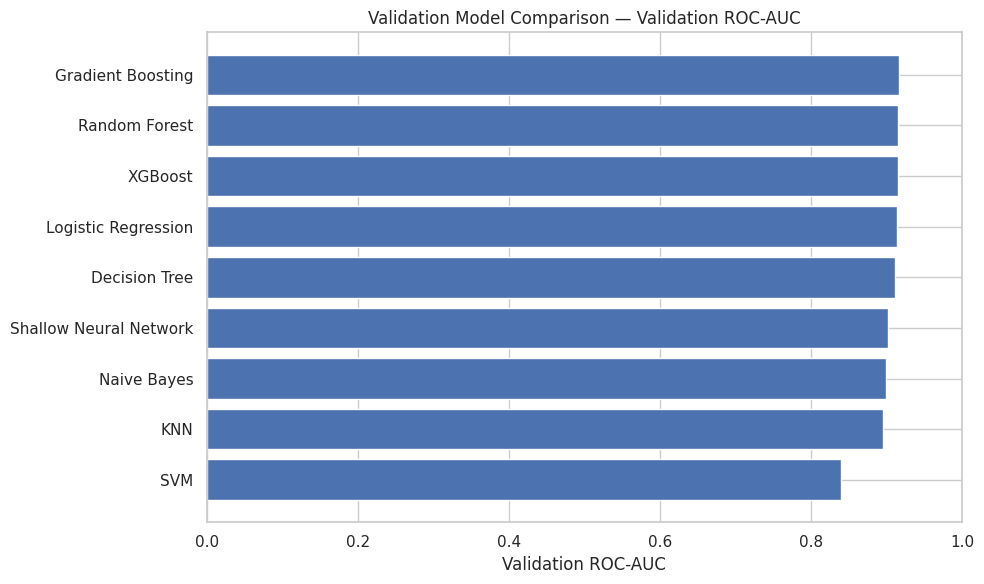

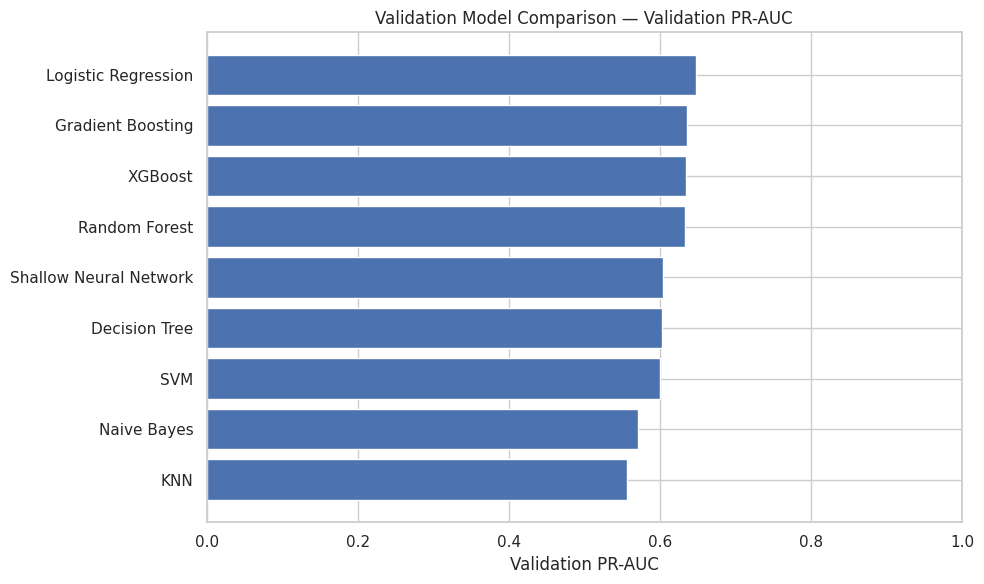

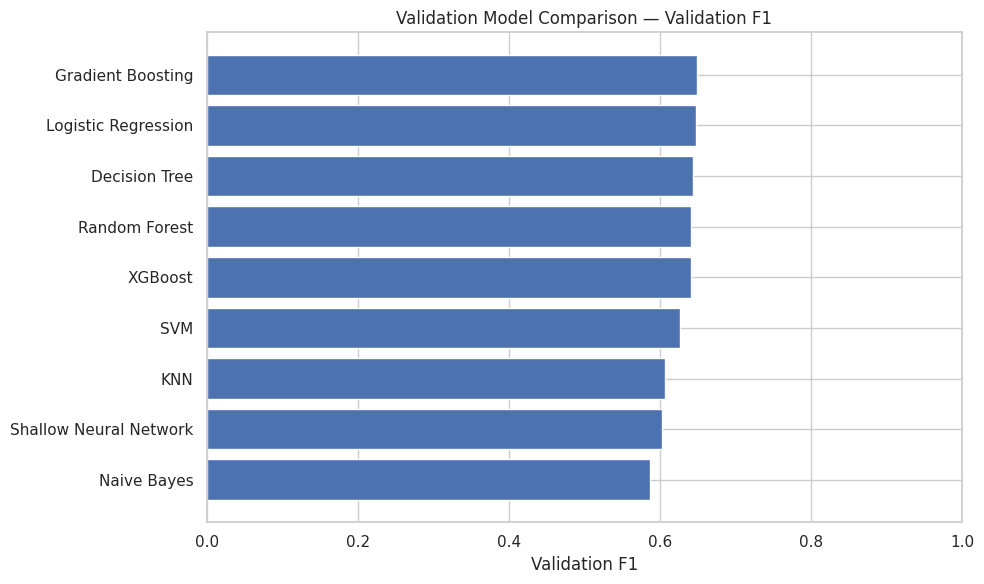

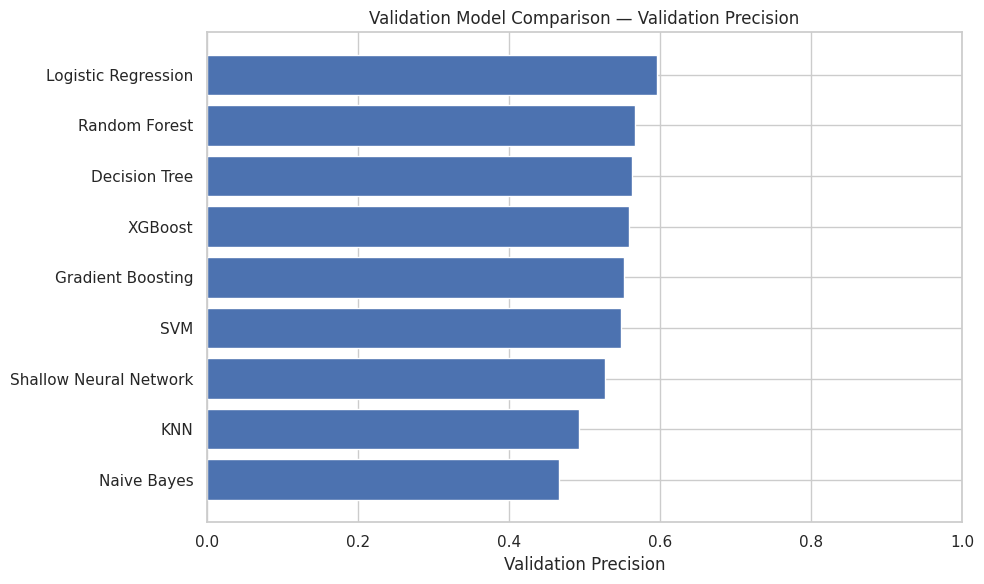

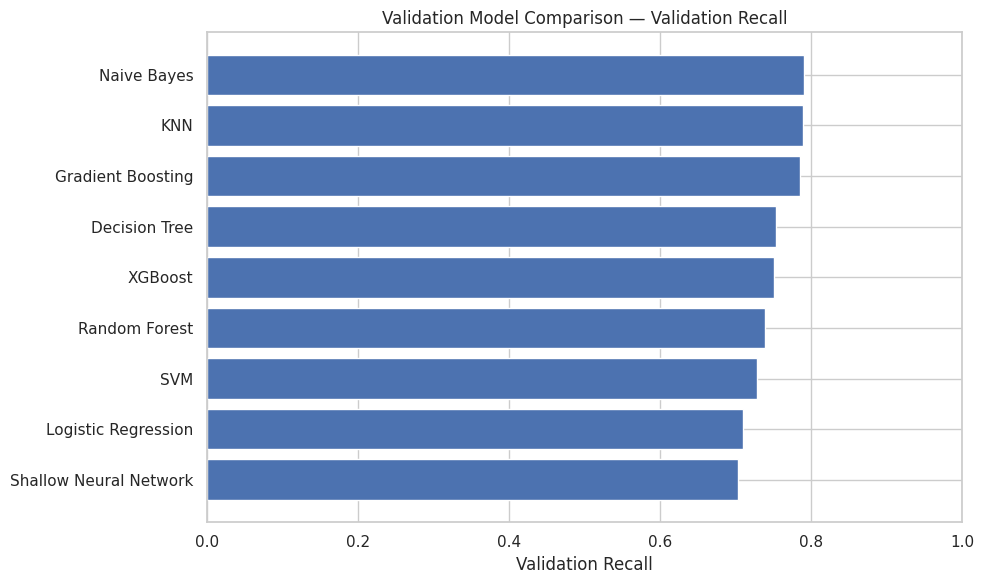

In [67]:
metrics = [
    "Validation ROC-AUC", "Validation PR-AUC", "Validation F1",
    "Validation Precision", "Validation Recall"
]
for metric in metrics:
    plot_df = validation_comparison.sort_values(metric, ascending=True)
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(plot_df["Model"], plot_df[metric])
    ax.set_xlabel(metric)
    ax.set_title(f"Validation Model Comparison — {metric}")
    ax.set_xlim(0, 1)
    plt.tight_layout()
    plt.show()

## 4.9 Training vs Validation Performance

A large difference between training and validation performance can indicate overfitting.

In [68]:
train_val_comparison = results_df[[
    "Model", "Train ROC-AUC", "Validation ROC-AUC",
    "Train PR-AUC", "Validation PR-AUC",
    "Train F1", "Validation F1",
    "Train Precision", "Validation Precision",
    "Train Recall", "Validation Recall"
]].copy()
display(train_val_comparison.round(4))

print("A large train–validation gap may indicate overfitting or temporal drift.")

,Model,Train ROC-AUC,Validation ROC-AUC,Train PR-AUC,Validation PR-AUC,Train F1,Validation F1,Train Precision,Validation Precision,Train Recall,Validation Recall
0,Logistic Regression,0.8803,0.9139,0.4898,0.6474,0.5230,0.6482,0.4993,0.5960,0.5490,0.7104
1,Decision Tree,0.8818,0.9119,0.4861,0.6034,0.5409,0.6446,0.4844,0.5628,0.6121,0.7542
2,Random Forest,0.9016,0.9160,0.5740,0.6329,0.5713,0.6418,0.5259,0.5672,0.6252,0.7391
3,Gradient Boosting,0.8894,0.9170,0.5277,0.6363,0.5529,0.6486,0.4782,0.5520,0.6553,0.7862
4,SVM,0.7585,0.8403,0.4376,0.6007,0.5327,0.6262,0.4869,0.5488,0.5879,0.7290
5,KNN,0.8780,0.8949,0.4923,0.5570,0.5465,0.6067,0.4498,0.4926,0.6961,0.7896
6,Naive Bayes,0.8726,0.8997,0.4552,0.5707,0.5190,0.5868,0.4162,0.4663,0.6893,0.7912
7,Shallow Neural Network,0.8656,0.9024,0.4672,0.6046,0.5128,0.6032,0.4708,0.5278,0.5631,0.7037
8,XGBoost,0.8923,0.9154,0.5366,0.6344,0.5570,0.6408,0.5025,0.5589,0.6248,0.7508


A large train–validation gap may indicate overfitting or temporal drift.


## 4.10 Final Test Evaluation

The test scores below are the final held-out evaluation. Models and thresholds were selected without using test labels. The test results are reported for the candidate models,not used to revise the selection.

In [69]:
# Select two statistical ML models using validation PR-AUC,then include the shallow neural network.
# This selection is dynamic: the best models may change after feature/preprocessing corrections.
statistical_names = [name for name in trained_models if name != "Shallow Neural Network"]
statistical_ranking = (
    validation_comparison[validation_comparison["Model"].isin(statistical_names)]
    .sort_values("Validation PR-AUC", ascending=False)
)
selected_model_names = statistical_ranking["Model"].head(2).tolist()
if "Shallow Neural Network" in trained_models:
    selected_model_names.append("Shallow Neural Network")
selected_model_names = list(dict.fromkeys(selected_model_names))

print("Selected models for Task 5 and detailed XAI (chosen on validation only):")
print(selected_model_names)
print("Their selection metric is validation PR-AUC; the shallow neural network is retained to satisfy the required model-family comparison.")

test_results = []
for name in selected_model_names:
    model = trained_models[name]
    metrics = evaluate_model(model, X_test_prepared, y_test, model_thresholds[name])
    test_results.append({
        "Model": name,
        "Threshold (validation-selected)": model_thresholds[name],
        **{f"Test {metric}": value for metric, value in metrics.items()}
    })
test_results_df = pd.DataFrame(test_results)
display(test_results_df.sort_values("Test PR-AUC", ascending=False).round(4))
print("The test PR-AUC sort above is descriptive only; model selection remains based on validation PR-AUC.")

Selected models for Task 5 and detailed XAI (chosen on validation only):
['Logistic Regression', 'Gradient Boosting', 'Shallow Neural Network']
Their selection metric is validation PR-AUC; the shallow neural network is retained to satisfy the required model-family comparison.


,Model,Threshold (validation-selected),Test ROC-AUC,Test PR-AUC,Test F1,Test Precision,Test Recall
1,Gradient Boosting,0.2983,0.9362,0.7032,0.6868,0.5872,0.8273
0,Logistic Regression,0.3372,0.9324,0.7029,0.6951,0.6340,0.7692
2,Shallow Neural Network,0.3640,0.9283,0.6737,0.6659,0.5832,0.7760


The test PR-AUC sort above is descriptive only; model selection remains based on validation PR-AUC.


## 4.11 Final Model Comparison

The validation results were used to select the three final models.

Their performance on the unseen test set is compared below.

In [70]:
# Validation-selected models remain fixed. This table is only a final descriptive test-set comparison.
final_comparison = test_results_df.copy()
display(final_comparison.round(4))

,Model,Threshold (validation-selected),Test ROC-AUC,Test PR-AUC,Test F1,Test Precision,Test Recall
0,Logistic Regression,0.3372,0.9324,0.7029,0.6951,0.6340,0.7692
1,Gradient Boosting,0.2983,0.9362,0.7032,0.6868,0.5872,0.8273
2,Shallow Neural Network,0.3640,0.9283,0.6737,0.6659,0.5832,0.7760


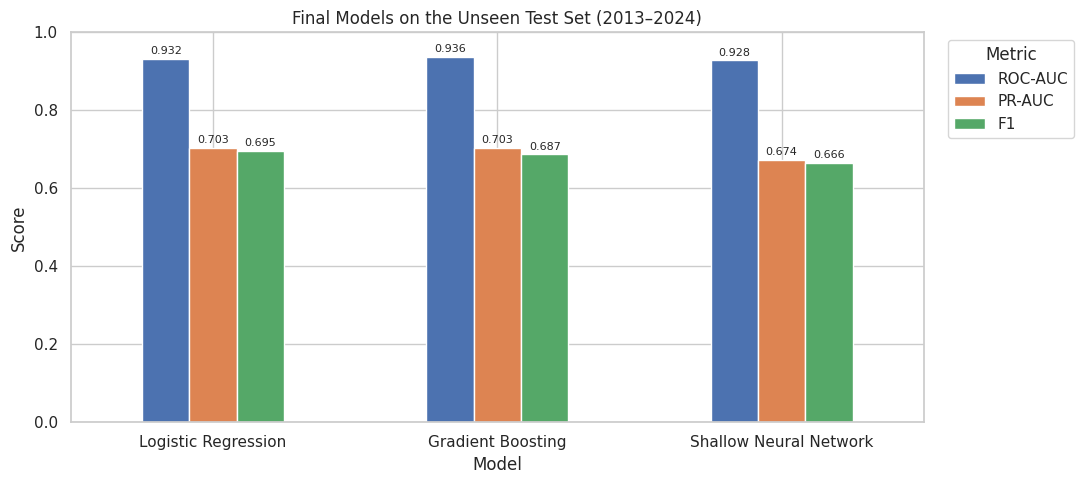

In [71]:
test_plot = final_comparison.set_index("Model")[["Test ROC-AUC", "Test PR-AUC", "Test F1"]]
test_plot.columns = ["ROC-AUC", "PR-AUC", "F1"]

ax = test_plot.plot(kind="bar", figsize=(11, 5), ylim=(0, 1), rot=0)
ax.set_title("Final Models on the Unseen Test Set (2013–2024)")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)
plt.tight_layout()
plt.show()

# 5. Experimental Evaluation

Task 5 investigates how feature selection and preprocessing choices affect the predictive performance of the F1 podium prediction models.

Two experiments are conducted:

1. **Feature-group ablation:** One feature group is removed at a time,and the models are retrained to measure the contribution of each group.
2. **Preprocessing-order experiments:** Three preprocessing pipelines are compared to investigate whether changing the order of imputation and scaling affects predictive performance.

The experiments use the same chronological training and validation splits established in Task 3. Preprocessing parameters are learned from training data only,and validation data is used to compare experimental configurations.

The evaluation metrics are ROC-AUC,PR-AUC,and F1-score. PR-AUC is particularly relevant because podium finishes represent the minority class.

The test set is reserved for the final evaluation and is not used to select the best feature set or preprocessing configuration.

In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_recall_curve
)

# Use the final features established in Task 3.
full_features = list(final_features)

feature_groups = {
    "Grid": ["grid"],
    "Driver Form": ["driver_recent_podium_rate_5"],
    "Constructor Form": ["constructor_recent_podium_rate_5"]
}

# Confirm that the feature groups cover the selected features exactly once.
grouped_features = [
    feature
    for features in feature_groups.values()
    for feature in features
]

assert set(grouped_features) == set(full_features), (
    "Feature groups do not match final_features. "
    "Check the feature names before continuing."
)

assert len(grouped_features) == len(set(grouped_features)), (
    "A feature appears in more than one feature group."
)

print("Full feature set:")
print(full_features)

print("\nFeature groups:")
for group_name, features in feature_groups.items():
    print(f"{group_name}: {features}")

Full feature set:
['grid', 'driver_recent_podium_rate_5', 'constructor_recent_podium_rate_5']

Feature groups:
Grid: ['grid']
Driver Form: ['driver_recent_podium_rate_5']
Constructor Form: ['constructor_recent_podium_rate_5']


In [73]:
# Use the models selected for Task 5 in Task 4.
selected_models = {
    name: trained_models[name]
    for name in selected_model_names
}

print("Models included in Task 5:")
for model_name in selected_models:
    print("-", model_name)

assert len(selected_models) > 0, (
    "No models were selected. Check selected_model_names in Task 4."
)

assert all(
    hasattr(model, "predict_proba")
    for model in selected_models.values()
), "Every selected model must support predict_proba."

Models included in Task 5:
- Logistic Regression
- Gradient Boosting
- Shallow Neural Network


In [74]:
def choose_f1_threshold(y_true, probabilities):
    """
    Select the decision threshold that maximizes validation F1.
    This function must not be applied to the test set for selection.
    """
    precision, recall, thresholds = precision_recall_curve(
        y_true,
        probabilities
    )

    if len(thresholds) == 0:
        return 0.5

    f1_values = (
        2 * precision[:-1] * recall[:-1]
    ) / np.clip(
        precision[:-1] + recall[:-1],
        1e-12,
        None
    )

    best_index = int(np.nanargmax(f1_values))

    return float(thresholds[best_index])


def evaluate_validation_model(model, X_val_data, y_val_data):
    """
    Evaluate a fitted model using validation data.
    The threshold is selected using the same validation data.
    """
    probabilities = model.predict_proba(X_val_data)[:, 1]

    threshold = choose_f1_threshold(
        y_val_data,
        probabilities
    )

    predictions = (
        probabilities >= threshold
    ).astype(int)

    return {
        "Validation threshold": threshold,
        "ROC-AUC": roc_auc_score(
            y_val_data,
            probabilities
        ),
        "PR-AUC": average_precision_score(
            y_val_data,
            probabilities
        ),
        "F1": f1_score(
            y_val_data,
            predictions,
            zero_division=0
        )
    }

### 5.1 Full-Feature Baseline

The full three-feature set provides the reference performance for the ablation experiments.

Each selected model is evaluated on the validation set using all three features. The reduced-feature experiments are then compared with this baseline to assess the effect of removing individual feature groups.

In [75]:
ablation_results = []

for model_name, fitted_model in selected_models.items():

    metrics = evaluate_validation_model(
        fitted_model,
        X_val_prepared,
        y_val
    )

    ablation_results.append({
        "Model": model_name,
        "Experiment": "Full Feature Set",
        "Removed Group": "None",
        **metrics
    })

ablation_results_df = pd.DataFrame(ablation_results)

display(
    ablation_results_df
    .sort_values("PR-AUC", ascending=False)
    .round(4)
)

,Model,Experiment,Removed Group,Validation threshold,ROC-AUC,PR-AUC,F1
0,Logistic Regression,Full Feature Set,None,0.3372,0.9139,0.6474,0.6482
1,Gradient Boosting,Full Feature Set,None,0.2983,0.9170,0.6363,0.6486
2,Shallow Neural Network,Full Feature Set,None,0.3640,0.9024,0.6046,0.6032


### 5.1.2 Feature-Group Ablation

Each feature group is removed separately while the other features are retained.

The model is retrained for each reduced feature set. The same chronological training and validation splits are used throughout,and preprocessing is fitted independently on each training subset.

This design allows us to evaluate the contribution of each feature group without using information from the validation set to fit preprocessing transformations.

In [76]:
ablation_datasets = {}

for group_name, removed_features in feature_groups.items():

    remaining_features = [
        feature
        for feature in full_features
        if feature not in removed_features
    ]

    if not remaining_features:
        raise ValueError(
            f"Removing {group_name} leaves no features."
        )

    ablation_datasets[group_name] = {
        "features": remaining_features,
        "X_train": X_train[remaining_features].copy(),
        "X_val": X_val[remaining_features].copy()
    }

    print(f"\nExperiment: Remove {group_name}")
    print("Removed features:", removed_features)
    print("Remaining features:", remaining_features)
    print(
        "Training shape:",
        ablation_datasets[group_name]["X_train"].shape
    )
    print(
        "Validation shape:",
        ablation_datasets[group_name]["X_val"].shape
    )


Experiment: Remove Grid
Removed features: ['grid']
Remaining features: ['driver_recent_podium_rate_5', 'constructor_recent_podium_rate_5']
Training shape: (15704, 2)
Validation shape: (4248, 2)

Experiment: Remove Driver Form
Removed features: ['driver_recent_podium_rate_5']
Remaining features: ['grid', 'constructor_recent_podium_rate_5']
Training shape: (15704, 2)
Validation shape: (4248, 2)

Experiment: Remove Constructor Form
Removed features: ['constructor_recent_podium_rate_5']
Remaining features: ['grid', 'driver_recent_podium_rate_5']
Training shape: (15704, 2)
Validation shape: (4248, 2)


In [77]:
ablation_model_results = []

for removed_group, data in ablation_datasets.items():

    print(f"\n===== Removing {removed_group} =====")

    Xtr = data["X_train"]
    Xv = data["X_val"]

    # Fit preprocessing on the reduced training data only.
    ablation_preprocessor = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    Xtr_prepared = ablation_preprocessor.fit_transform(Xtr)
    Xv_prepared = ablation_preprocessor.transform(Xv)

    for model_name, original_model in selected_models.items():

        model = clone(original_model)
        model.fit(Xtr_prepared, y_train)

        metrics = evaluate_validation_model(
            model,
            Xv_prepared,
            y_val
        )

        ablation_model_results.append({
            "Model": model_name,
            "Experiment": f"Remove {removed_group}",
            "Removed Group": removed_group,
            **metrics
        })

ablation_results_df = pd.concat(
    [
        ablation_results_df,
        pd.DataFrame(ablation_model_results)
    ],
    ignore_index=True
)

display(
    ablation_results_df
    .sort_values(
        ["Model", "Experiment"]
    )
    .round(4)
)


===== Removing Grid =====

===== Removing Driver Form =====

===== Removing Constructor Form =====


,Model,Experiment,Removed Group,Validation threshold,ROC-AUC,PR-AUC,F1
1,Gradient Boosting,Full Feature Set,None,0.2983,0.9170,0.6363,0.6486
10,Gradient Boosting,Remove Constructor Form,Constructor Form,0.3343,0.9154,0.6337,0.6461
7,Gradient Boosting,Remove Driver Form,Driver Form,0.3346,0.9139,0.6378,0.6355
4,Gradient Boosting,Remove Grid,Grid,0.3018,0.8592,0.4939,0.5489
0,Logistic Regression,Full Feature Set,None,0.3372,0.9139,0.6474,0.6482
9,Logistic Regression,Remove Constructor Form,Constructor Form,0.3192,0.9133,0.6483,0.6470
6,Logistic Regression,Remove Driver Form,Driver Form,0.3497,0.9117,0.6396,0.6425
3,Logistic Regression,Remove Grid,Grid,0.1696,0.8610,0.5086,0.5524
2,Shallow Neural Network,Full Feature Set,None,0.3640,0.9024,0.6046,0.6032
11,Shallow Neural Network,Remove Constructor Form,Constructor Form,0.3457,0.9058,0.6235,0.6149


### 5.1.3 Ablation Results

The full-feature model is compared with three reduced-feature models,each excluding one feature group.

A decrease in validation performance after removing a feature group suggests that the model benefits from that group. An increase suggests that the removed group may introduce redundant or unhelpful information for that model.

The results are model-specific and should be interpreted as predictive evidence rather than causal effects.

In [78]:
ablation_comparison = ablation_results_df.pivot_table(
    index=["Model", "Removed Group"],
    values=["ROC-AUC", "PR-AUC", "F1"],
    aggfunc="mean"
).reset_index()

display(
    ablation_comparison
    .sort_values(["Model", "PR-AUC"], ascending=[True, False])
    .round(4)
)

,Model,Removed Group,F1,PR-AUC,ROC-AUC
1,Gradient Boosting,Driver Form,0.6355,0.6378,0.9139
3,Gradient Boosting,None,0.6486,0.6363,0.9170
0,Gradient Boosting,Constructor Form,0.6461,0.6337,0.9154
2,Gradient Boosting,Grid,0.5489,0.4939,0.8592
4,Logistic Regression,Constructor Form,0.6470,0.6483,0.9133
7,Logistic Regression,None,0.6482,0.6474,0.9139
5,Logistic Regression,Driver Form,0.6425,0.6396,0.9117
6,Logistic Regression,Grid,0.5524,0.5086,0.8610
9,Shallow Neural Network,Driver Form,0.6254,0.6259,0.9119
8,Shallow Neural Network,Constructor Form,0.6149,0.6235,0.9058


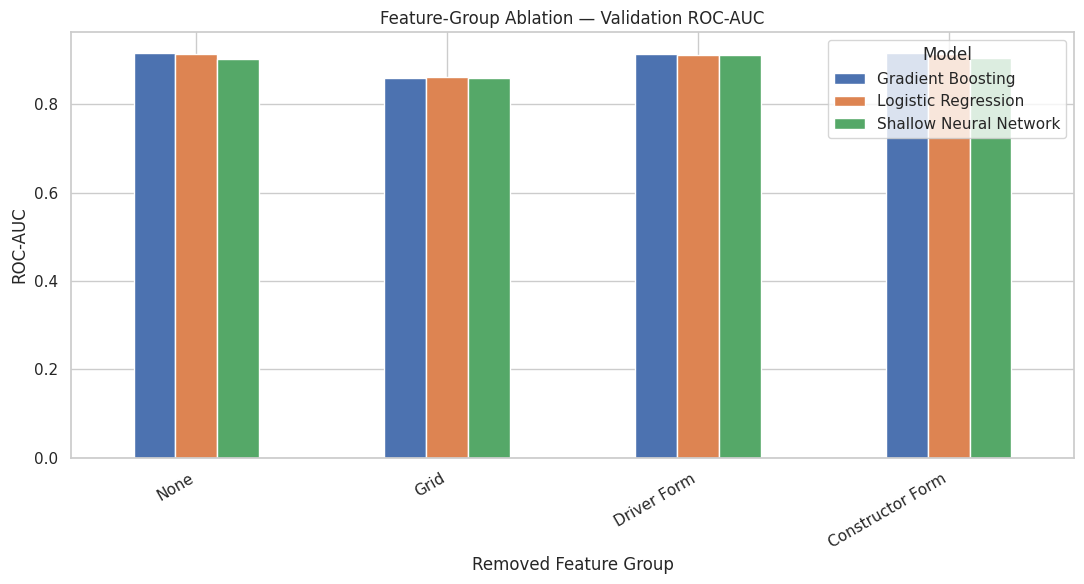

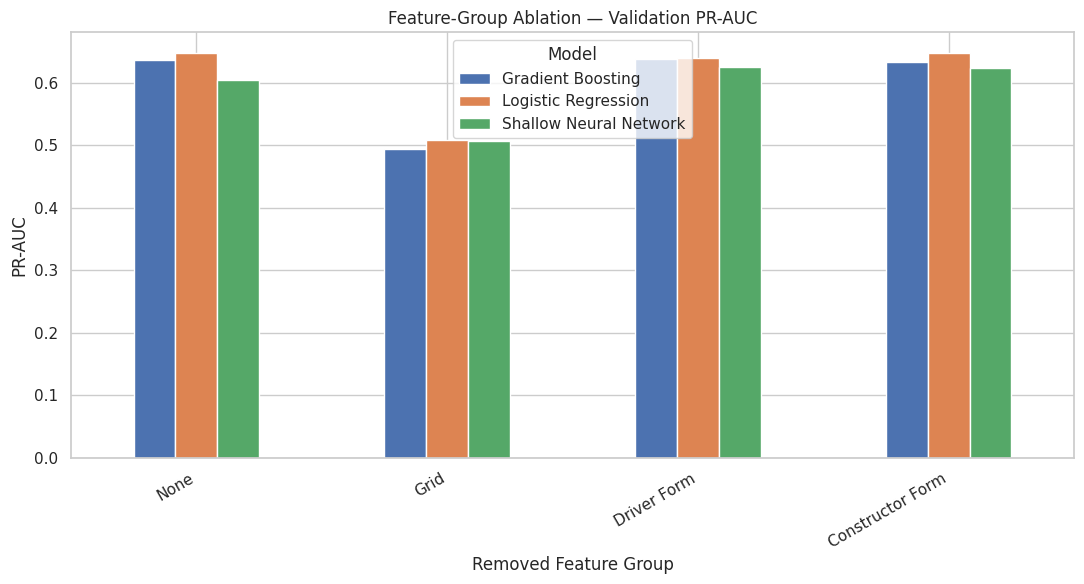

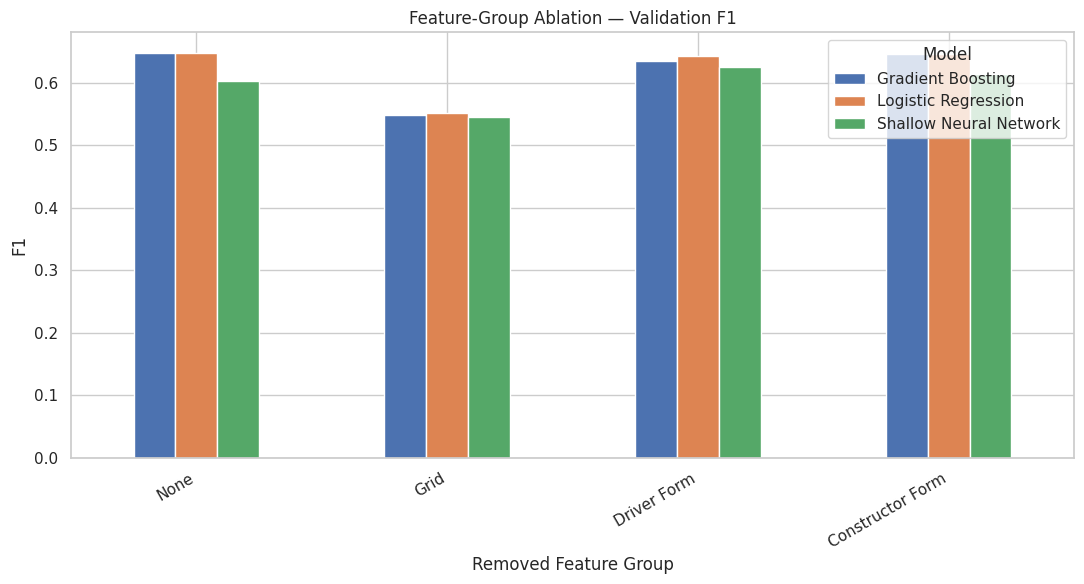

In [79]:
ablation_plot = ablation_results_df.copy()

ablation_order = [
    "None",
    "Grid",
    "Driver Form",
    "Constructor Form"
]

for metric in ["ROC-AUC", "PR-AUC", "F1"]:

    pivot = ablation_plot.pivot(
        index="Removed Group",
        columns="Model",
        values=metric
    ).reindex(ablation_order)

    ax = pivot.plot(
        kind="bar",
        figsize=(11, 6)
    )

    ax.set_title(f"Feature-Group Ablation — Validation {metric}")
    ax.set_xlabel("Removed Feature Group")
    ax.set_ylabel(metric)
    ax.legend(title="Model")

    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

## 5.2 Preprocessing-Order Experiments

Three preprocessing pipelines are compared:

- **Pipeline A — Imputation → StandardScaler:** Missing values are replaced with training-set medians before scaling.
- **Pipeline B — StandardScaler → Imputation:** The scaler is fitted to observed training values,and missing values are imputed after scaling.
- **Pipeline C — RobustScaler → Imputation:** Robust scaling is fitted to observed training values,and missing values are imputed after scaling.

All pipelines are fitted on the training data only. The same training and validation splits and the same selected models are used across experiments.

StandardScaler and RobustScaler support missing values in the scikit-learn versions used for these experiments. If the installed version does not support this behavior,the affected pipeline must not be silently substituted; the environment and implementation should be checked.

Because these pipelines differ in both order and scaling method,the comparison measures the combined effect of those choices rather than isolating order alone.

Validation ROC-AUC,PR-AUC,and F1 are used to compare the configurations. The test set is not used to select a pipeline.

In [80]:
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

preprocessing_configs = {
    "A: Imputation → StandardScaler": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]),
    "B: StandardScaler → Imputation": Pipeline([
        ("scaler", StandardScaler()),
        ("imputer", SimpleImputer(strategy="median"))
    ]),
    "C: RobustScaler → Imputation": Pipeline([
        ("scaler", RobustScaler()),
        ("imputer", SimpleImputer(strategy="median"))
    ])
}

print("Preprocessing configurations:")

for name, pipeline in preprocessing_configs.items():
    print(f"\n{name}")
    print(pipeline)

Preprocessing configurations:

A: Imputation → StandardScaler
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])

B: StandardScaler → Imputation
Pipeline(steps=[('scaler', StandardScaler()),
                ('imputer', SimpleImputer(strategy='median'))])

C: RobustScaler → Imputation
Pipeline(steps=[('scaler', RobustScaler()),
                ('imputer', SimpleImputer(strategy='median'))])


In [81]:
preprocessing_results = []

for config_name, preprocessor_exp in preprocessing_configs.items():

    print(f"\n===== {config_name} =====")

    # Fit preprocessing only on training data.
    Xtr = preprocessor_exp.fit_transform(X_train)
    Xv = preprocessor_exp.transform(X_val)

    # Confirm that preprocessing produced valid numerical arrays.
    if not np.isfinite(Xtr).all():
        raise ValueError(
            f"Non-finite values remain in training data for {config_name}."
        )

    if not np.isfinite(Xv).all():
        raise ValueError(
            f"Non-finite values remain in validation data for {config_name}."
        )

    for model_name, original_model in selected_models.items():

        model = clone(original_model)
        model.fit(Xtr, y_train)

        metrics = evaluate_validation_model(
            model,
            Xv,
            y_val
        )

        preprocessing_results.append({
            "Pipeline": config_name,
            "Model": model_name,
            **metrics
        })

preprocessing_results_df = pd.DataFrame(
    preprocessing_results
)

display(
    preprocessing_results_df
    .sort_values(
        ["Pipeline", "PR-AUC"],
        ascending=[True, False]
    )
    .round(4)
)


===== A: Imputation → StandardScaler =====

===== B: StandardScaler → Imputation =====

===== C: RobustScaler → Imputation =====


,Pipeline,Model,Validation threshold,ROC-AUC,PR-AUC,F1
0,A: Imputation → StandardScaler,Logistic Regression,0.3372,0.9139,0.6474,0.6482
1,A: Imputation → StandardScaler,Gradient Boosting,0.2983,0.9170,0.6363,0.6486
2,A: Imputation → StandardScaler,Shallow Neural Network,0.3640,0.9024,0.6046,0.6032
3,B: StandardScaler → Imputation,Logistic Regression,0.3373,0.9139,0.6474,0.6482
4,B: StandardScaler → Imputation,Gradient Boosting,0.2983,0.9170,0.6363,0.6486
5,B: StandardScaler → Imputation,Shallow Neural Network,0.3481,0.8961,0.5876,0.5855
6,C: RobustScaler → Imputation,Logistic Regression,0.3382,0.9139,0.6474,0.6482
7,C: RobustScaler → Imputation,Gradient Boosting,0.2998,0.9174,0.6395,0.6477
8,C: RobustScaler → Imputation,Shallow Neural Network,0.3273,0.9086,0.6190,0.6142


### 5.2.1 Full Preprocessing Comparison

This table presents the validation performance of each selected model under each preprocessing configuration.

The decision threshold is selected separately for each model and pipeline using validation F1. ROC-AUC and PR-AUC are calculated from predicted probabilities and do not depend on the decision threshold.

In [82]:
preprocessing_comparison = (
    preprocessing_results_df
    .sort_values(
        ["Pipeline", "PR-AUC"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

display(
    preprocessing_comparison.round(4)
)

,Pipeline,Model,Validation threshold,ROC-AUC,PR-AUC,F1
0,A: Imputation → StandardScaler,Logistic Regression,0.3372,0.9139,0.6474,0.6482
1,A: Imputation → StandardScaler,Gradient Boosting,0.2983,0.9170,0.6363,0.6486
2,A: Imputation → StandardScaler,Shallow Neural Network,0.3640,0.9024,0.6046,0.6032
3,B: StandardScaler → Imputation,Logistic Regression,0.3373,0.9139,0.6474,0.6482
4,B: StandardScaler → Imputation,Gradient Boosting,0.2983,0.9170,0.6363,0.6486
5,B: StandardScaler → Imputation,Shallow Neural Network,0.3481,0.8961,0.5876,0.5855
6,C: RobustScaler → Imputation,Logistic Regression,0.3382,0.9139,0.6474,0.6482
7,C: RobustScaler → Imputation,Gradient Boosting,0.2998,0.9174,0.6395,0.6477
8,C: RobustScaler → Imputation,Shallow Neural Network,0.3273,0.9086,0.6190,0.6142


Pipeline,A: Imputation → StandardScaler,B: StandardScaler → Imputation,C: RobustScaler → Imputation
Model,,,
Gradient Boosting,0.9170,0.9170,0.9174
Logistic Regression,0.9139,0.9139,0.9139
Shallow Neural Network,0.9024,0.8961,0.9086


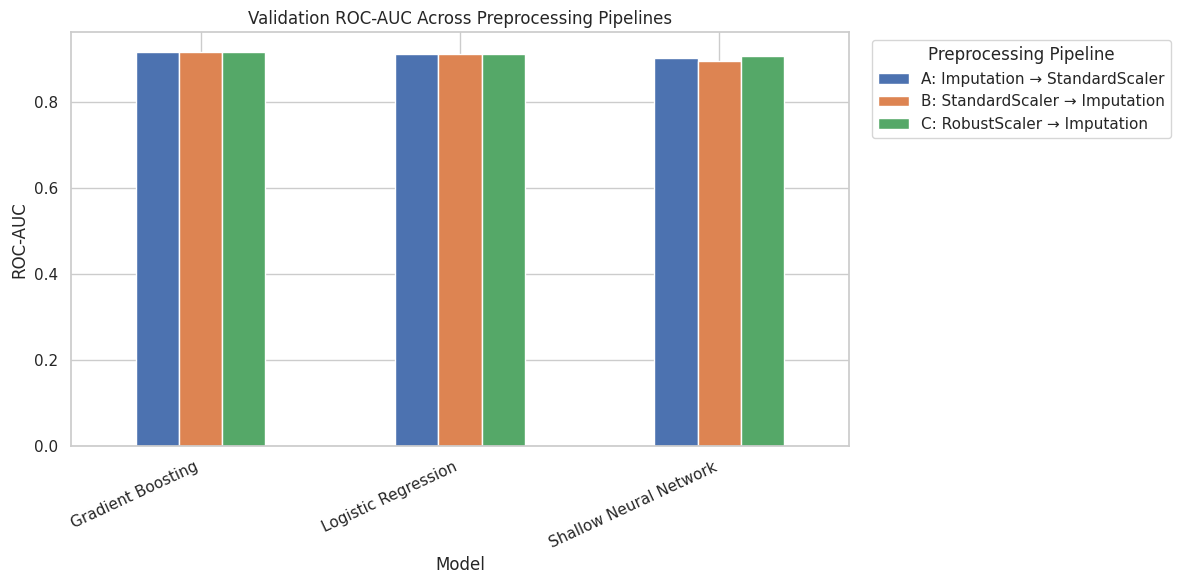

In [83]:
roc_table = preprocessing_results_df.pivot(
    index="Model",
    columns="Pipeline",
    values="ROC-AUC"
)

display(roc_table.round(4))

ax = roc_table.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title("Validation ROC-AUC Across Preprocessing Pipelines")
ax.set_xlabel("Model")
ax.set_ylabel("ROC-AUC")
ax.legend(title="Preprocessing Pipeline", bbox_to_anchor=(1.02, 1))

plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

Pipeline,A: Imputation → StandardScaler,B: StandardScaler → Imputation,C: RobustScaler → Imputation
Model,,,
Gradient Boosting,0.6363,0.6363,0.6395
Logistic Regression,0.6474,0.6474,0.6474
Shallow Neural Network,0.6046,0.5876,0.6190


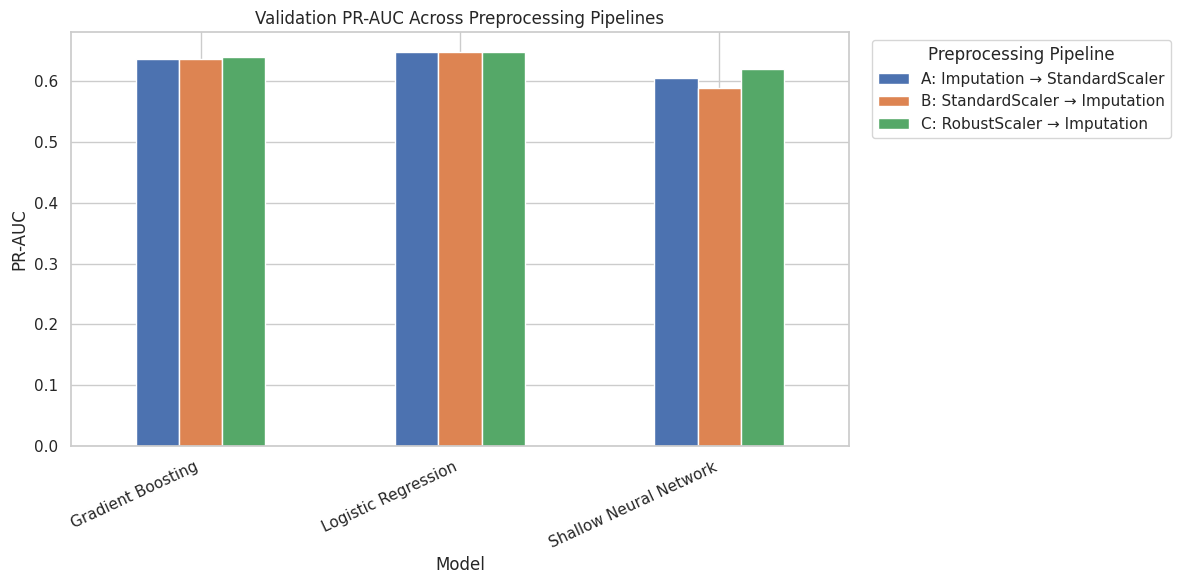

In [84]:
pr_table = preprocessing_results_df.pivot(
    index="Model",
    columns="Pipeline",
    values="PR-AUC"
)

display(pr_table.round(4))

ax = pr_table.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title("Validation PR-AUC Across Preprocessing Pipelines")
ax.set_xlabel("Model")
ax.set_ylabel("PR-AUC")
ax.legend(title="Preprocessing Pipeline", bbox_to_anchor=(1.02, 1))

plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

Pipeline,A: Imputation → StandardScaler,B: StandardScaler → Imputation,C: RobustScaler → Imputation
Model,,,
Gradient Boosting,0.6486,0.6486,0.6477
Logistic Regression,0.6482,0.6482,0.6482
Shallow Neural Network,0.6032,0.5855,0.6142


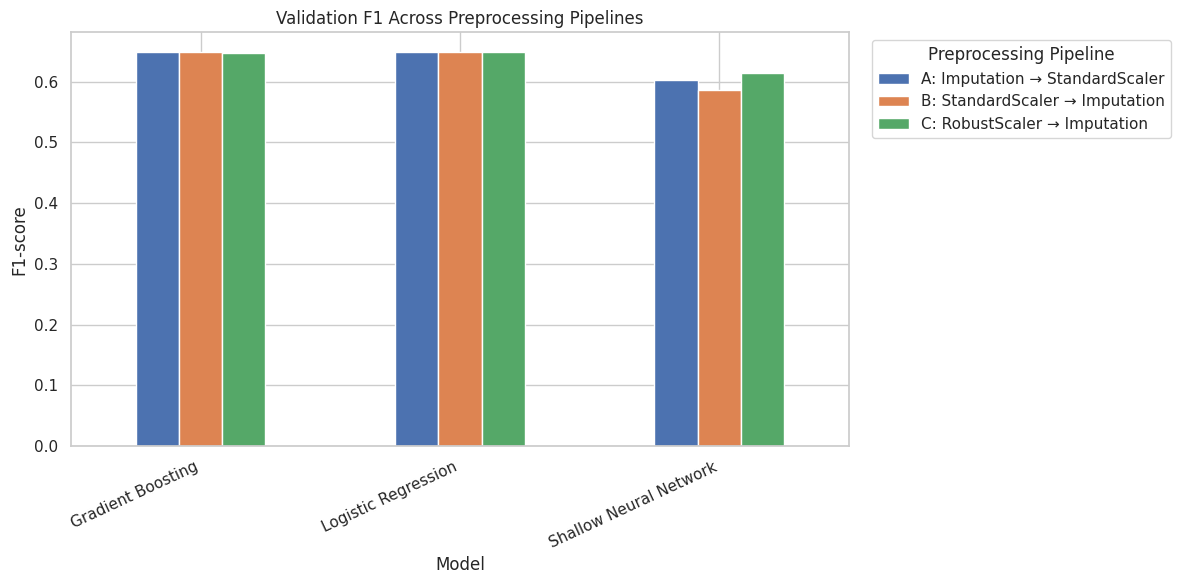

In [85]:
f1_table = preprocessing_results_df.pivot(
    index="Model",
    columns="Pipeline",
    values="F1"
)

display(f1_table.round(4))

ax = f1_table.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title("Validation F1 Across Preprocessing Pipelines")
ax.set_xlabel("Model")
ax.set_ylabel("F1-score")
ax.legend(title="Preprocessing Pipeline", bbox_to_anchor=(1.02, 1))

plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

### 5.2.2 Best Preprocessing Configuration

The preprocessing configuration with the highest validation PR-AUC is identified separately for each model.

PR-AUC is the primary selection metric because podium finishes are the minority class. ROC-AUC and F1 are reported alongside PR-AUC to provide additional context.

The best configuration may differ between models. These results identify the strongest validation configuration and do not guarantee the same ranking on unseen data.

In [86]:
best_preprocessing = (
    preprocessing_results_df
    .sort_values(
        ["Model", "PR-AUC", "ROC-AUC"],
        ascending=[True, False, False]
    )
    .groupby("Model", as_index=False)
    .first()
)

display(
    best_preprocessing[
        [
            "Model",
            "Pipeline",
            "Validation threshold",
            "ROC-AUC",
            "PR-AUC",
            "F1"
        ]
    ].round(4)
)

,Model,Pipeline,Validation threshold,ROC-AUC,PR-AUC,F1
0,Gradient Boosting,C: RobustScaler → Imputation,0.2998,0.9174,0.6395,0.6477
1,Logistic Regression,A: Imputation → StandardScaler,0.3372,0.9139,0.6474,0.6482
2,Shallow Neural Network,C: RobustScaler → Imputation,0.3273,0.9086,0.6190,0.6142


### 5.2.3 Performance Change Relative to the Baseline

Pipeline A,which performs median imputation followed by StandardScaler,is the baseline.

For each alternative pipeline,the changes in validation ROC-AUC,PR-AUC,and F1 are calculated relative to the baseline for the same model.

Positive changes indicate improved validation performance,while negative changes indicate reduced performance. A value close to zero indicates little difference.

In [87]:
baseline_pipeline = "A: Imputation → StandardScaler"

baseline_rows = preprocessing_results_df[
    preprocessing_results_df["Pipeline"] == baseline_pipeline
].copy()

alternative = preprocessing_results_df[
    preprocessing_results_df["Pipeline"] != baseline_pipeline
].copy()

# Ensure that every model has exactly one baseline result.
if baseline_rows["Model"].duplicated().any():
    raise ValueError(
        "Duplicate baseline results found. "
        "Rerun the preprocessing evaluation cell."
    )

baseline = baseline_rows.set_index("Model")

common_models = set(baseline.index).intersection(
    alternative["Model"]
)

alternative = alternative[
    alternative["Model"].isin(common_models)
].copy()

for metric in ["ROC-AUC", "PR-AUC", "F1"]:

    alternative[f"{metric} Change"] = (
        alternative[metric].to_numpy()
        - alternative["Model"].map(
            baseline[metric]
        ).to_numpy()
    )

change_columns = [
    "Pipeline",
    "Model",
    "ROC-AUC",
    "ROC-AUC Change",
    "PR-AUC",
    "PR-AUC Change",
    "F1",
    "F1 Change"
]

display(
    alternative[change_columns]
    .sort_values(["Model", "Pipeline"])
    .round(4)
    .reset_index(drop=True)
)

,Pipeline,Model,ROC-AUC,ROC-AUC Change,PR-AUC,PR-AUC Change,F1,F1 Change
0,B: StandardScaler → Imputation,Gradient Boosting,0.9170,0.0000,0.6363,0.0000,0.6486,0.0000
1,C: RobustScaler → Imputation,Gradient Boosting,0.9174,0.0004,0.6395,0.0032,0.6477,-0.0009
2,B: StandardScaler → Imputation,Logistic Regression,0.9139,-0.0000,0.6474,-0.0000,0.6482,0.0000
3,C: RobustScaler → Imputation,Logistic Regression,0.9139,-0.0000,0.6474,-0.0000,0.6482,0.0000
4,B: StandardScaler → Imputation,Shallow Neural Network,0.8961,-0.0064,0.5876,-0.0171,0.5855,-0.0177
5,C: RobustScaler → Imputation,Shallow Neural Network,0.9086,0.0062,0.6190,0.0144,0.6142,0.0111


### 5.2.4 Overall Preprocessing Ranking

The configurations are ranked by their mean validation PR-AUC across the selected models.

Mean ROC-AUC and mean F1 are included as secondary metrics. This ranking summarizes performance across the selected models,but individual models may respond differently to each preprocessing configuration.

PR-AUC is used as the primary ranking metric because the podium class is imbalanced.

In [88]:
pipeline_ranking = (
    preprocessing_results_df
    .groupby("Pipeline")
    .agg(
        Mean_ROC_AUC=("ROC-AUC", "mean"),
        Mean_PR_AUC=("PR-AUC", "mean"),
        Mean_F1=("F1", "mean")
    )
    .reset_index()
    .sort_values(
        ["Mean_PR_AUC", "Mean_ROC_AUC"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

pipeline_ranking.insert(
    0,
    "Rank",
    range(1, len(pipeline_ranking) + 1)
)

display(
    pipeline_ranking.round(4)
)

,Rank,Pipeline,Mean_ROC_AUC,Mean_PR_AUC,Mean_F1
0,1,C: RobustScaler → Imputation,0.9133,0.6353,0.6367
1,2,A: Imputation → StandardScaler,0.9111,0.6295,0.6333
2,3,B: StandardScaler → Imputation,0.9090,0.6238,0.6274


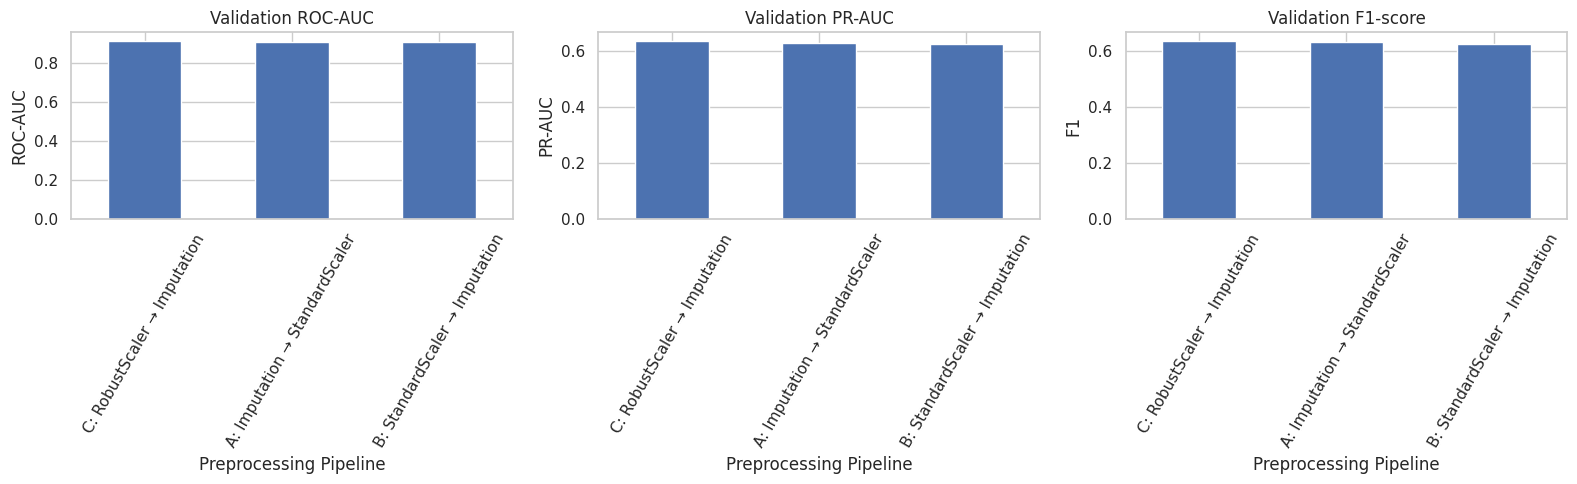

In [89]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = [
    ("ROC-AUC", "Validation ROC-AUC"),
    ("PR-AUC", "Validation PR-AUC"),
    ("F1", "Validation F1-score")
]

for ax, (metric, title) in zip(axes, metrics):

    summary = (
        preprocessing_results_df
        .groupby("Pipeline")[metric]
        .mean()
        .sort_values(ascending=False)
    )

    summary.plot(
        kind="bar",
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Preprocessing Pipeline")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

## 5.3 Task 5 Conclusions

Task 5 evaluated the contribution of the selected feature groups and investigated the effect of preprocessing choices on F1 podium prediction.

### Feature-group ablation

Each feature group was removed separately,and the selected models were retrained using the remaining features. The resulting validation metrics show how predictive performance changes when grid position,driver recent form,or constructor recent form is excluded.

A reduction in performance suggests that the removed feature group provides useful predictive information. An improvement may indicate that the group introduces redundancy or information that is less useful for the particular model. These effects may differ between models.

### Preprocessing-order experiments

Three preprocessing configurations were compared: median imputation followed by StandardScaler,StandardScaler followed by median imputation,and RobustScaler followed by median imputation.

The experiments were evaluated using validation ROC-AUC,PR-AUC,and F1. The results identify which configurations performed best on the validation set for each selected model.

The experiments change both the order and,in some configurations,the scaling method. Therefore,the results should be interpreted as a comparison of complete preprocessing configurations rather than as a perfectly isolated test of order alone.

### Experimental limitations

- Preprocessing transformations were fitted using training data only.
- The same chronological training and validation splits were maintained.
- Decision thresholds were selected using validation data only.
- The test set was not used to choose feature groups or preprocessing configurations.
- The results measure predictive performance and do not establish causal relationships.

The strongest configuration is selected using validation PR-AUC. Final generalization performance must be assessed separately using the held-out test set,without using test results to revise the selection.

# Task 6 — Model Explainability (XAI)

This section explains what the trained models rely on when predicting whether an F1 driver will finish on the podium. It includes global permutation importance,grouped importance,global and local SHAP explanations,LIME,and interpretation. Feature importance describes model behaviour and does not establish causation. All explanations use the three pre-race features selected in Task 3.


In [90]:
import importlib
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, precision_recall_curve
from IPython.display import Markdown, display


def ensure_package(pip_name, module_name=None):
    try:
        importlib.import_module(module_name or pip_name)
    except ImportError:
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", pip_name
        ])


ensure_package("shap")
ensure_package("lime")

import shap
from lime.lime_tabular import LimeTabularExplainer

XAI_SEED = RANDOM_SEED

feature_names = list(final_features)

print("SHAP version:", shap.__version__)
print("Features explained:", feature_names)

SHAP version: 0.52.0
Features explained: ['grid', 'driver_recent_podium_rate_5', 'constructor_recent_podium_rate_5']


## 6.1 Model Selection and Evaluation Data

The model explained in detail is selected from the dynamically chosen validation-ranked statistical models and the shallow neural network using validation PR-AUC. The test set is not used to select the model. Global explanations use validation data,and the test set is used only for descriptive stability checks and local examples. The classification threshold is selected using validation data only. The three features are grid position,driver recent form,and constructor recent form.


In [91]:
# Select the model with the highest validation PR-AUC among the models retained for Task 5.
val_pr = validation_comparison.set_index("Model")["Validation PR-AUC"]
selected_model_names_for_xai = list(selected_models.keys())
explain_name = val_pr.loc[selected_model_names_for_xai].idxmax()
explain_model = trained_models[explain_name]
xai_threshold = float(model_thresholds[explain_name])

print("Model selected for detailed explanation:", explain_name)
print("Validation PR-AUC:", round(float(val_pr.loc[explain_name]), 4))
print(f"Frozen validation-selected threshold: {xai_threshold:.4f}")
print("The test set is not used to select the model or threshold.")

Model selected for detailed explanation: Logistic Regression
Validation PR-AUC: 0.6474
Frozen validation-selected threshold: 0.3372
The test set is not used to select the model or threshold.


## 6.2 Global Explanation I — Permutation Importance

Permutation importance measures how much model performance decreases when one feature is randomly shuffled. A large decrease in PR-AUC indicates that the model relies on that feature. PR-AUC is used because podium finishes are the minority class. Twenty repetitions estimate the average decrease and its variability.


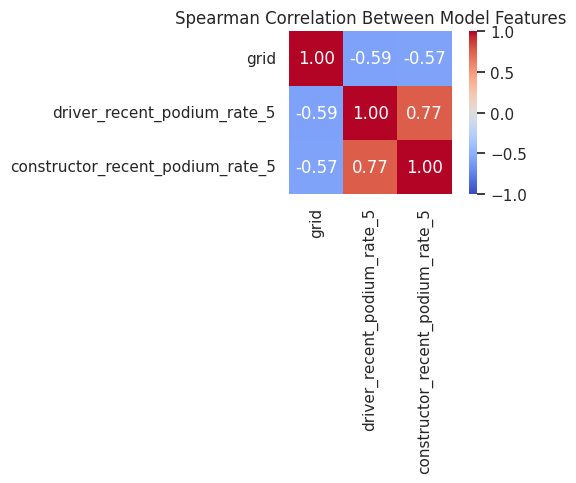

In [92]:
# Examine correlations among the three selected features.
corr_train = X_train[feature_names].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr_train, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Spearman Correlation Between Model Features")
plt.tight_layout()
plt.show()

Permutation importance: Logistic Regression


,feature,mean_drop_validation,std_validation,mean_drop_test,std_test
0,grid,0.3835,0.0159,0.3862,0.0157
1,driver_recent_podium_rate_5,0.0271,0.0091,0.0205,0.0072
2,constructor_recent_podium_rate_5,0.0235,0.0097,0.0228,0.0076


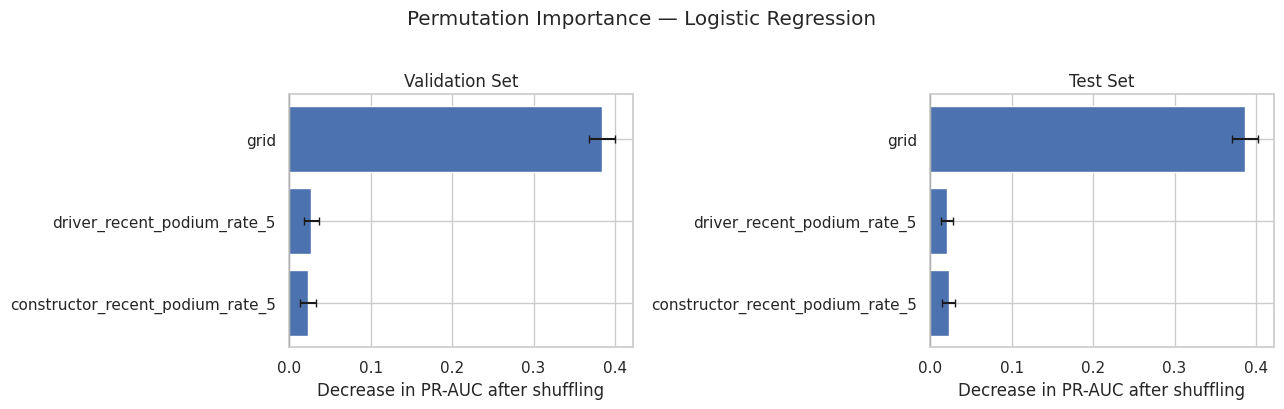

In [93]:
def perm_importance_table(model, X_prepared, y, n_repeats=20):
    result = permutation_importance(
        model,
        X_prepared,
        y,
        scoring="average_precision",
        n_repeats=n_repeats,
        random_state=XAI_SEED,
        n_jobs=1
    )

    return (
        pd.DataFrame({
            "feature": feature_names,
            "mean_drop": result.importances_mean,
            "std": result.importances_std
        })
        .sort_values("mean_drop", ascending=False)
        .reset_index(drop=True)
    )


# Global importance on validation and test data.
pi_val = perm_importance_table(
    explain_model,
    X_val_prepared,
    y_val
)

pi_test = perm_importance_table(
    explain_model,
    X_test_prepared,
    y_test
)

print("Permutation importance:", explain_name)

display(
    pi_val.merge(
        pi_test,
        on="feature",
        suffixes=("_validation", "_test")
    ).round(4)
)

# Plot validation and test results side by side.
order = pi_val["feature"].tolist()[::-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True)

for ax, table, title in zip(
    axes,
    [pi_val, pi_test],
    ["Validation Set", "Test Set"]
):
    plot_data = table.set_index("feature").loc[order]

    ax.barh(
        plot_data.index,
        plot_data["mean_drop"],
        xerr=plot_data["std"],
        capsize=3
    )

    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel("Decrease in PR-AUC after shuffling")

fig.suptitle(
    f"Permutation Importance — {explain_name}",
    y=1.02
)

plt.tight_layout()
plt.show()

### 6.2.1 Grouped Permutation Importance and Cross-Model Comparison

The feature groups are grid position,driver recent form,and constructor recent form. Features are shuffled together within each group using the same row permutation. The analysis is repeated across the three selected models to compare their reliance on the retained features.


Grouped permutation importance: Logistic Regression


,group,mean_drop_validation,std_validation,mean_drop_test,std_test
0,Grid position,0.3743,0.0153,0.3851,0.0130
1,Driver form,0.0305,0.0085,0.0246,0.0081
2,Constructor form,0.0273,0.0135,0.0250,0.0096


,Logistic Regression,Gradient Boosting,Shallow Neural Network
feature,,,
grid,0.3831,0.3227,0.1875
driver_recent_podium_rate_5,0.0242,0.0772,0.1619
constructor_recent_podium_rate_5,0.0210,0.0260,0.1311


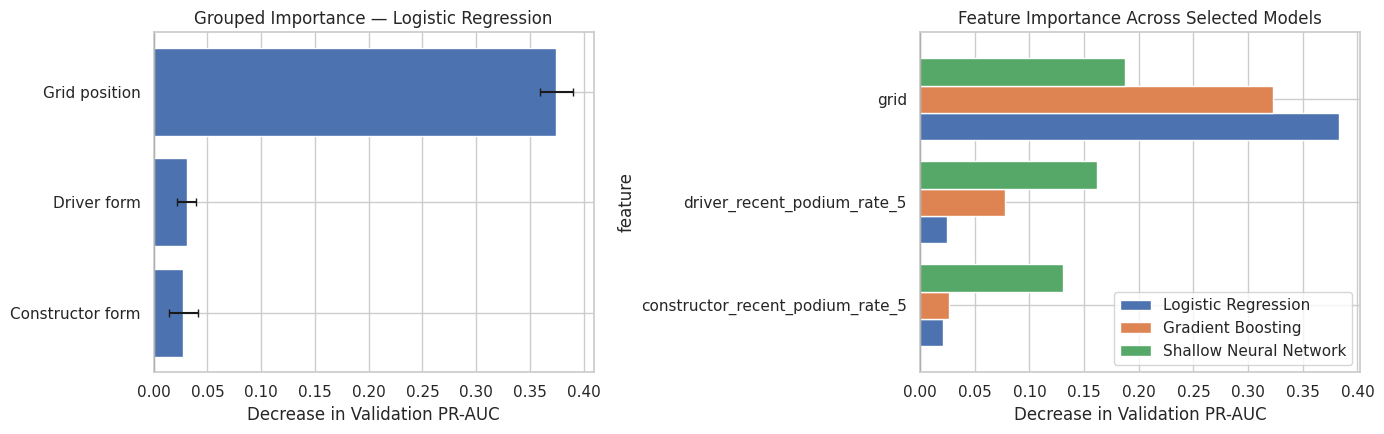

In [94]:
FEATURE_GROUPS = {
    "Grid position": ["grid"],
    "Driver form": ["driver_recent_podium_rate_5"],
    "Constructor form": ["constructor_recent_podium_rate_5"]
}


def grouped_permutation_drop(
    model,
    X_prepared,
    y,
    groups,
    n_repeats=20
):
    rng = np.random.default_rng(XAI_SEED)

    baseline_score = average_precision_score(
        y,
        model.predict_proba(X_prepared)[:, 1]
    )

    rows = []

    for group_name, columns in groups.items():
        column_indices = [feature_names.index(column) for column in columns]
        drops = []

        for _ in range(n_repeats):
            X_permuted = X_prepared.copy()
            permutation = rng.permutation(len(X_permuted))
            X_permuted[:, column_indices] = X_prepared[permutation][:, column_indices]

            score = average_precision_score(
                y,
                model.predict_proba(X_permuted)[:, 1]
            )
            drops.append(baseline_score - score)

        rows.append({
            "group": group_name,
            "mean_drop": np.mean(drops),
            "std": np.std(drops)
        })

    return pd.DataFrame(rows).sort_values(
        "mean_drop",ascending=False
    ).reset_index(drop=True)


gp_val = grouped_permutation_drop(
    explain_model,X_val_prepared,y_val,FEATURE_GROUPS
)
gp_test = grouped_permutation_drop(
    explain_model,X_test_prepared,y_test,FEATURE_GROUPS
)

print("Grouped permutation importance:",explain_name)
display(gp_val.merge(gp_test,on="group",suffixes=("_validation","_test")).round(4))

cross = {}
for name in selected_models:
    cross[name] = (
        perm_importance_table(
            trained_models[name],X_val_prepared,y_val,n_repeats=10
        ).set_index("feature")["mean_drop"]
    )

cross_df = pd.DataFrame(cross).loc[feature_names]
display(cross_df.round(4))

fig, axes = plt.subplots(1,2,figsize=(14,4.5))
group_plot = gp_val.set_index("group").loc[gp_val["group"][::-1]]
axes[0].barh(group_plot.index,group_plot["mean_drop"],xerr=group_plot["std"],capsize=3)
axes[0].axvline(0,color="black",linewidth=0.8)
axes[0].set_title(f"Grouped Importance — {explain_name}")
axes[0].set_xlabel("Decrease in Validation PR-AUC")
cross_df.iloc[::-1].plot.barh(ax=axes[1],width=0.8)
axes[1].axvline(0,color="black",linewidth=0.8)
axes[1].set_title("Feature Importance Across Selected Models")
axes[1].set_xlabel("Decrease in Validation PR-AUC")
plt.tight_layout()
plt.show()


## 6.3 Global Explanation II — SHAP

SHAP assigns each feature a contribution to an individual prediction relative to a baseline prediction.

The mean absolute SHAP value measures the average magnitude of a feature's contribution. Positive and negative SHAP values show whether a feature moves the model output up or down.

For XGBoost,a tree-specific explainer is used. For other models,a model-agnostic explainer is used.

SHAP values are calculated on a sample of validation observations using a background sample from the training data.

The resulting explanations describe the trained model's behaviour;they do not establish causal effects.

In [95]:
rng = np.random.default_rng(XAI_SEED)

# Background sample from training data.
bg_idx = rng.choice(
    len(X_train_prepared),
    size=min(200, len(X_train_prepared)),
    replace=False
)

background = X_train_prepared[bg_idx]

# Validation sample to explain.
ex_idx = np.sort(
    rng.choice(
        len(X_val_prepared),
        size=min(2000, len(X_val_prepared)),
        replace=False
    )
)

X_ex_prepared = X_val_prepared[ex_idx]
X_ex_raw = pd.DataFrame(
    preprocessor.named_steps["imputer"].transform(X_val.iloc[ex_idx][feature_names]),
    columns=feature_names
)

IS_TREE_MODEL = hasattr(explain_model, "get_booster")

if IS_TREE_MODEL:
    shap_explainer = shap.TreeExplainer(explain_model)

    shap_units = "log-odds of podium"

    model_output_fn = lambda Xp: explain_model.predict(
        Xp,
        output_margin=True
    )

else:
    predict_podium = lambda Xp: explain_model.predict_proba(Xp)[:, 1]

    shap_explainer = shap.Explainer(
        predict_podium,
        shap.maskers.Independent(
            background,
            max_samples=min(100, len(background))
        ),
        algorithm="exact",
        feature_names=feature_names
    )

    shap_units = "probability"

    model_output_fn = predict_podium


def as_explanation(raw_sv, raw_data):
    # Display the original feature values rather than scaled values.
    n = raw_sv.values.shape[0]

    base = np.asarray(
        raw_sv.base_values,
        dtype=float
    ).reshape(-1)

    if len(base) == 1:
        base = np.repeat(base, n)

    return shap.Explanation(
        values=np.asarray(raw_sv.values, dtype=float),
        base_values=base,
        data=np.asarray(raw_data, dtype=float),
        feature_names=feature_names
    )


sv_raw = shap_explainer(X_ex_prepared)

sv = as_explanation(
    sv_raw,
    X_ex_raw.to_numpy()
)

# Check whether the SHAP values reconstruct the model output.
reconstructed = (
    sv.base_values +
    sv.values.sum(axis=1)
)

actual_output = np.asarray(
    model_output_fn(X_ex_prepared)
).reshape(-1)

max_err = float(
    np.max(np.abs(reconstructed - actual_output))
)

print(
    "Explainer:",
    "TreeExplainer" if IS_TREE_MODEL else "Exact model-agnostic"
)

print("Output units:", shap_units)

print(
    f"SHAP values: {sv.values.shape[0]} rows x "
    f"{sv.values.shape[1]} features"
)

print(
    f"Maximum reconstruction error: {max_err:.2e}"
)

assert max_err < 1e-3, (
    "SHAP values do not reconstruct the model output within tolerance."
)

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


Explainer: Exact model-agnostic
Output units: probability
SHAP values: 2000 rows x 3 features
Maximum reconstruction error: 2.00e-15


,feature,mean_abs_shap
0,grid,0.1172
1,constructor_recent_podium_rate_5,0.0286
2,driver_recent_podium_rate_5,0.0243


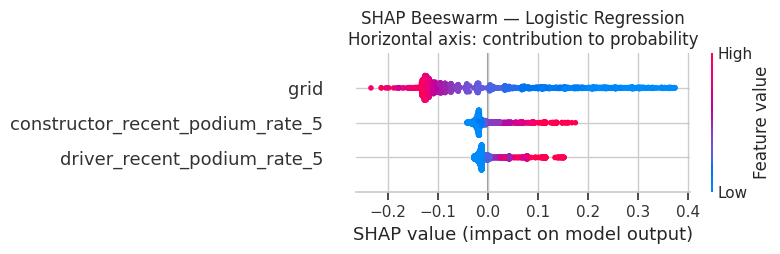

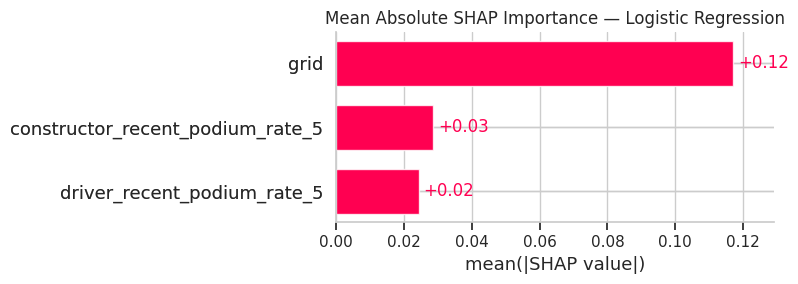

In [96]:
# Rank features by mean absolute SHAP value.
shap_rank = (
    pd.DataFrame({
        "feature": feature_names,
        "mean_abs_shap": np.abs(sv.values).mean(axis=0)
    })
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

display(shap_rank.round(4))

# SHAP beeswarm plot.
plt.figure()

shap.plots.beeswarm(
    sv,
    show=False
)

plt.title(
    f"SHAP Beeswarm — {explain_name}\n"
    f"Horizontal axis: contribution to {shap_units}"
)

plt.tight_layout()
plt.show()

# Global mean absolute SHAP importance.
plt.figure()

shap.plots.bar(
    sv,
    show=False
)

plt.title(
    f"Mean Absolute SHAP Importance — {explain_name}"
)

plt.tight_layout()
plt.show()

### 6.3.1 SHAP Dependence Plots

Each point represents one validation observation.

The horizontal axis shows a feature's raw value,and the vertical axis shows its SHAP contribution to the model output.

These plots help reveal how the model uses a feature across different values. They can show patterns such as increasing contributions,thresholds,or diminishing changes.

These patterns describe the model's behaviour and should not be interpreted as causal effects.

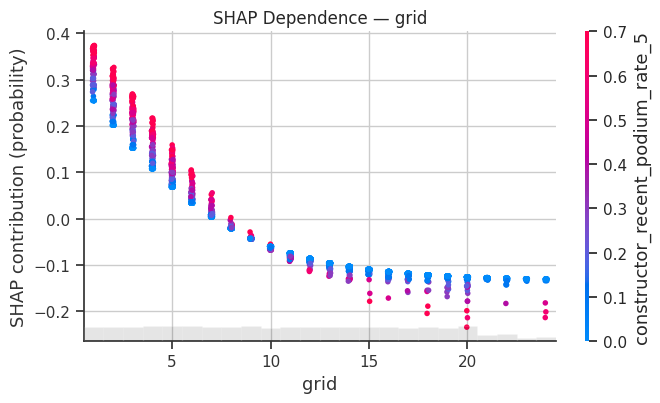

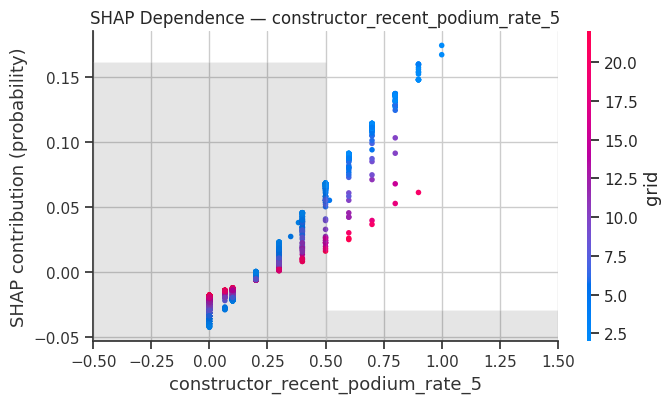

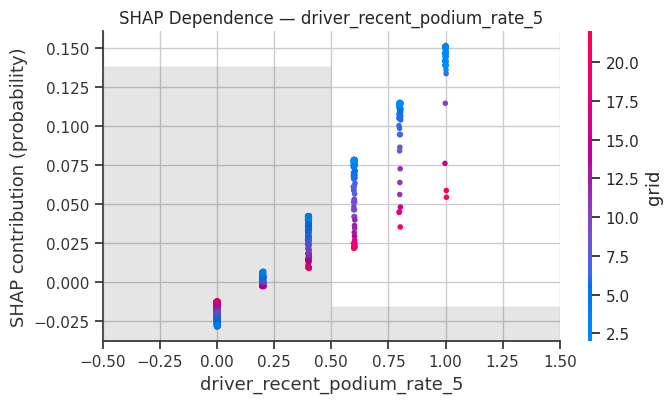

In [97]:
top_feats = shap_rank["feature"].tolist()[:3]

for feature in top_feats:
    fig, ax = plt.subplots(figsize=(7, 4.2))

    shap.plots.scatter(
        sv[:, feature],
        color=sv,
        ax=ax,
        show=False
    )

    ax.set_title(
        f"SHAP Dependence — {feature}"
    )

    ax.set_ylabel(
        f"SHAP contribution ({shap_units})"
    )

    plt.tight_layout()
    plt.show()

## 6.4 Comparison of Permutation Importance and SHAP

Permutation importance and SHAP measure feature importance in different ways.

Permutation importance measures the reduction in predictive performance when a feature is shuffled.

SHAP measures the magnitude of a feature's contribution to model predictions.

Their rankings may agree or differ,particularly when features contain overlapping information.

The following table and plot compare the rankings using validation data.

,feature,perm_importance_drop,mean_abs_shap,rank_perm,rank_shap
0,grid,0.3835,0.1172,1.0,1.0
2,constructor_recent_podium_rate_5,0.0235,0.0286,3.0,2.0
1,driver_recent_podium_rate_5,0.0271,0.0243,2.0,3.0


Spearman rank correlation between permutation importance and SHAP rankings: 0.50


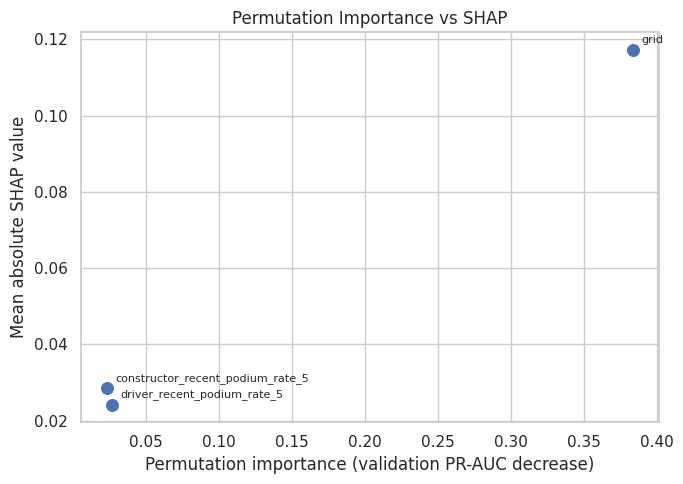

In [98]:
agree = (
    pi_val[
        ["feature", "mean_drop"]
    ]
    .rename(
        columns={
            "mean_drop": "perm_importance_drop"
        }
    )
    .merge(
        shap_rank,
        on="feature"
    )
)

agree["rank_perm"] = (
    agree["perm_importance_drop"]
    .rank(ascending=False, method="average")
)

agree["rank_shap"] = (
    agree["mean_abs_shap"]
    .rank(ascending=False, method="average")
)

display(
    agree.sort_values("rank_shap").round(4)
)

rho_rank = agree["rank_perm"].corr(
    agree["rank_shap"],
    method="spearman"
)

print(
    "Spearman rank correlation between permutation importance "
    f"and SHAP rankings: {rho_rank:.2f}"
)

fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(
    agree["perm_importance_drop"],
    agree["mean_abs_shap"],
    s=70
)

for row in agree.itertuples():
    ax.annotate(
        row.feature,
        (
            row.perm_importance_drop,
            row.mean_abs_shap
        ),
        textcoords="offset points",
        xytext=(6, 5),
        fontsize=8
    )

ax.set_xlabel(
    "Permutation importance (validation PR-AUC decrease)"
)

ax.set_ylabel(
    "Mean absolute SHAP value"
)

ax.set_title(
    "Permutation Importance vs SHAP"
)

plt.tight_layout()
plt.show()

## 6.5 Local Explanation I — SHAP Waterfall Plots

Global explanations describe the model's overall behaviour. Local explanations examine why the model assigned a particular probability to one driver in one race.

Three test-set cases are selected using the threshold determined on validation data:

1. True positive: a podium finisher predicted to finish on the podium.
2. False negative: a podium finisher predicted not to finish on the podium.
3. False positive: a non-podium finisher predicted to finish on the podium.

These examples illustrate different types of predictions and errors. The test set is used only to examine these examples;the model and threshold are not adjusted based on them.

In [99]:
p_test = explain_model.predict_proba(
    X_test_prepared
)[:, 1]

y_t = np.asarray(y_test)

pred_t = p_test >= xai_threshold

tp = np.where((y_t == 1) & pred_t)[0]
fn = np.where((y_t == 1) & ~pred_t)[0]
fp = np.where((y_t == 0) & pred_t)[0]

case_idx = {}

if len(tp):
    case_idx[
        "True positive (most confident podium call)"
    ] = int(tp[np.argmax(p_test[tp])])

if len(fn):
    case_idx[
        "False negative (podium finisher rated lowest)"
    ] = int(fn[np.argmin(p_test[fn])])

if len(fp):
    case_idx[
        "False positive (non-podium rated highest)"
    ] = int(fp[np.argmax(p_test[fp])])


print(
    f"Test cases at threshold {xai_threshold:.3f}: "
    f"TP={len(tp)}, FN={len(fn)}, FP={len(fp)}"
)


def case_label(i):
    row = test_df.iloc[i]

    try:
        driver = (
            clean["drivers"]
            .set_index("driverId")
            .loc[row["driverId"]]
        )

        race = (
            clean["races"]
            .set_index("raceId")
            .loc[row["raceId"]]
        )

        return (
            f"{driver['forename']} {driver['surname']} — "
            f"{int(row['year'])} {race['name']}"
        )

    except Exception:
        return (
            f"driverId {int(row['driverId'])} — "
            f"raceId {int(row['raceId'])} "
            f"({int(row['year'])})"
        )


case_table = pd.DataFrame([
    {
        "case": name,
        "driver / race": case_label(i),
        "actual podium": int(y_t[i]),
        "predicted probability": round(float(p_test[i]), 3),
        **{
            feature: X_test.iloc[i][feature]
            for feature in feature_names
        }
    }
    for name, i in case_idx.items()
])

display(case_table.round(3))

Test cases at threshold 0.337: TP=570, FN=171, FP=329


,case,driver / race,actual podium,predicted probability,grid,driver_recent_podium_rate_5,constructor_recent_podium_rate_5
0,True positive (most confident podium call),Nico Rosberg — 2014 Canadian Grand Prix,1,0.841,1.0,1.0,1.0
1,False negative (podium finisher rated lowest),Carlos Sainz — 2019 Brazilian Grand Prix,1,0.006,20.0,0.0,0.0
2,False positive (non-podium rated highest),Lewis Hamilton — 2015 Hungarian Grand Prix,0,0.841,1.0,1.0,1.0


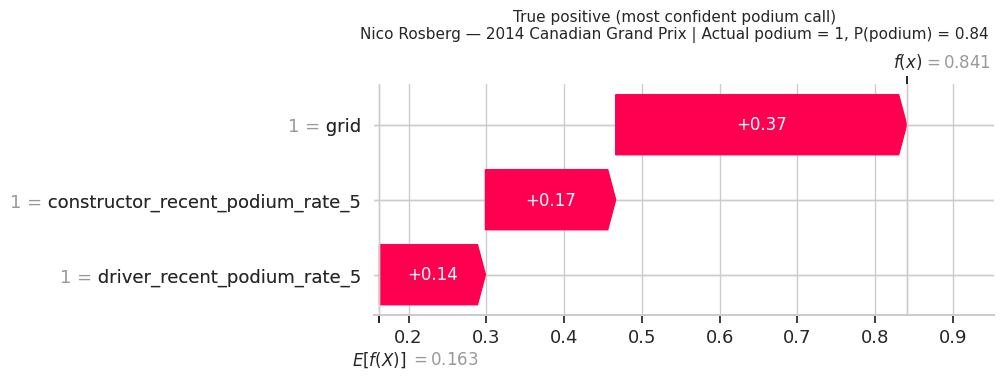

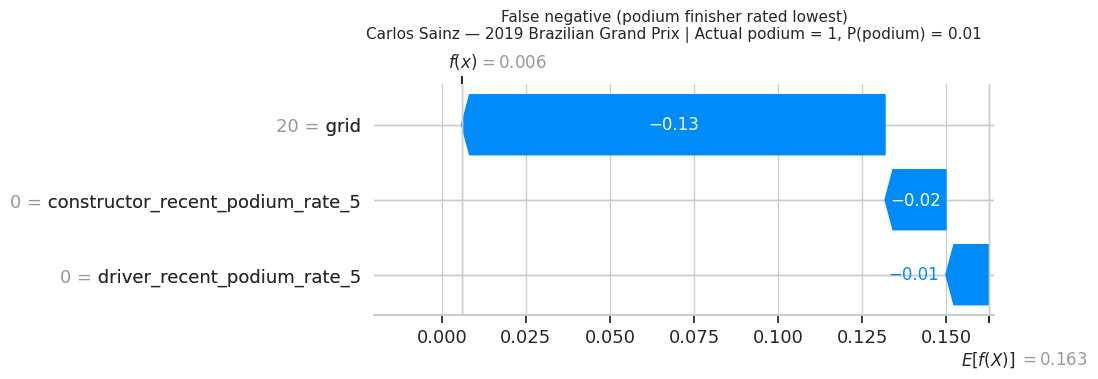

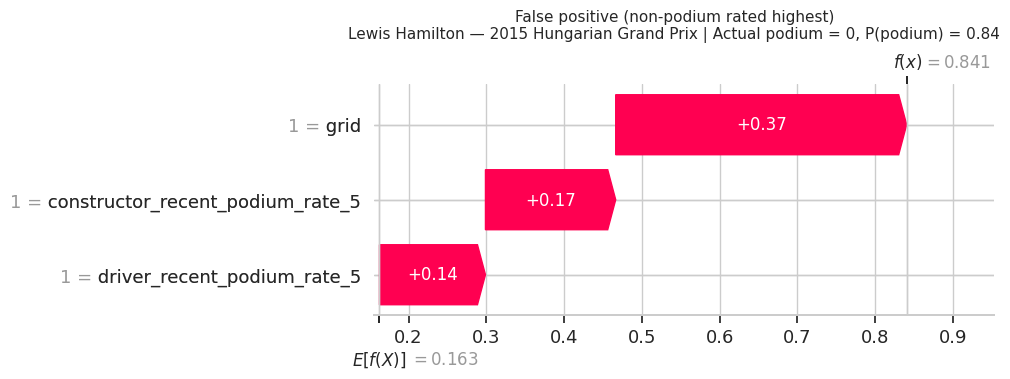

In [100]:
# Explain the selected individual test cases.
if case_idx:

    idxs = list(case_idx.values())

    local_sv_raw = shap_explainer(
        X_test_prepared[idxs]
    )

    local_raw = preprocessor.named_steps["imputer"].transform(
        X_test.iloc[idxs][feature_names]
    )
    local_sv = as_explanation(
        local_sv_raw,
        local_raw
    )

    for k, (name, i) in enumerate(case_idx.items()):

        plt.figure()

        shap.plots.waterfall(
            local_sv[k],
            show=False
        )

        plt.gcf().suptitle(
            f"{name}\n"
            f"{case_label(i)} | "
            f"Actual podium = {int(y_t[i])}, "
            f"P(podium) = {p_test[i]:.2f}",
            y=1.13,
            fontsize=11
        )

        plt.show()

else:
    print(
        "No true-positive,false-negative,or false-positive cases "
        "were found for the selected threshold."
    )

## 6.6 Local Explanation II — LIME

LIME explains a single prediction by generating perturbed versions of the observation and fitting a simple weighted model around that observation.

Its weights describe how the model behaves locally for that driver–race record.

LIME uses the original feature values and applies the fitted preprocessing pipeline before obtaining predictions.

The same individual cases used for SHAP are explained with LIME. The direction of the LIME weights is compared with the direction of the corresponding SHAP values.

LIME is stochastic and local. Its results may differ from SHAP and should be interpreted as a complementary explanation rather than ground truth.

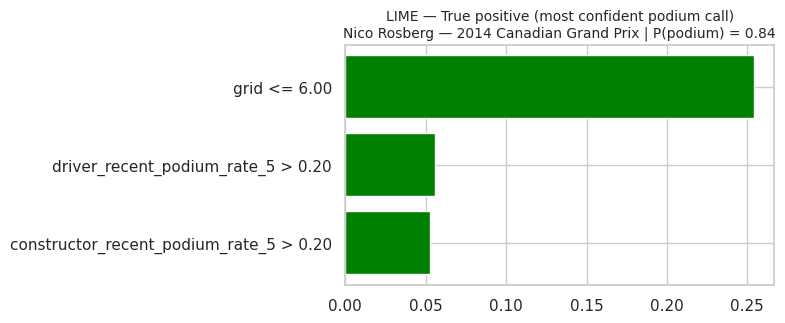

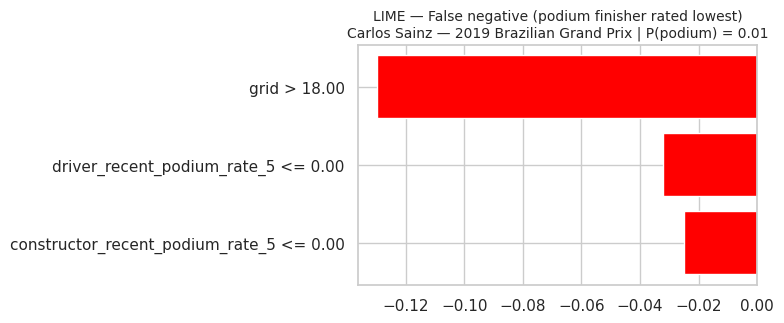

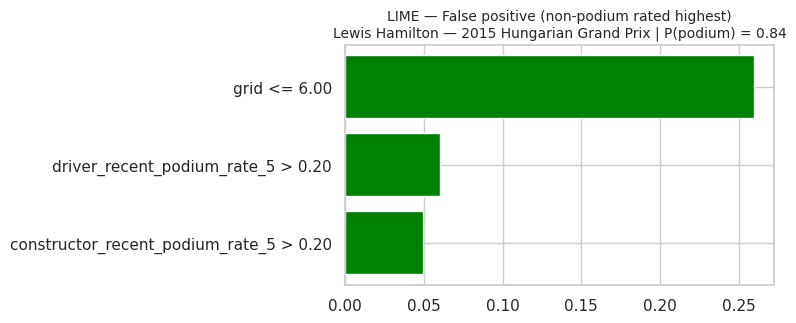

,case,feature,SHAP value,LIME weight,same direction
0,True positive (most confident podium call),grid,0.3742,0.2539,True
1,True positive (most confident podium call),driver_recent_podium_rate_5,0.1363,0.0558,True
2,True positive (most confident podium call),constructor_recent_podium_rate_5,0.1675,0.0527,True
3,False negative (podium finisher rated lowest),grid,-0.1259,-0.1298,True
4,False negative (podium finisher rated lowest),driver_recent_podium_rate_5,-0.0127,-0.0320,True
5,False negative (podium finisher rated lowest),constructor_recent_podium_rate_5,-0.0181,-0.0250,True
6,False positive (non-podium rated highest),grid,0.3742,0.2596,True
7,False positive (non-podium rated highest),driver_recent_podium_rate_5,0.1363,0.0603,True
8,False positive (non-podium rated highest),constructor_recent_podium_rate_5,0.1675,0.0496,True


LIME and SHAP agree on direction for 100% of the 9 case-feature pairs.


In [101]:
def predict_fn_raw(X_raw):
    # LIME perturbs values in the original feature scale.
    X_df = pd.DataFrame(X_raw,columns=feature_names)
    X_prepared = preprocessor.transform(X_df)
    return explain_model.predict_proba(X_prepared)


# LIME needs complete numeric values to generate local perturbations. Use the
# imputer already fitted on the training set; do not fit a new imputer here.
lime_imputer = preprocessor.named_steps["imputer"]
lime_train_data = lime_imputer.transform(X_train[feature_names])

lime_explainer = LimeTabularExplainer(
    training_data=lime_train_data,
    feature_names=feature_names,
    class_names=["not podium","podium"],
    mode="classification",
    discretize_continuous=True,
    random_state=XAI_SEED
)

sign_rows = []

for k,(name,i) in enumerate(case_idx.items()):

    # Impute missing raw feature values using training-set medians before LIME.
    x_row = lime_imputer.transform(
        X_test.iloc[[i]][feature_names]
    )[0]

    exp = lime_explainer.explain_instance(
        x_row,
        predict_fn_raw,
        num_features=len(feature_names),
        num_samples=5000,
        labels=(1,)
    )

    fig = exp.as_pyplot_figure(label=1)
    fig.set_size_inches(8,3.4)
    fig.axes[0].set_title(
        f"LIME — {name}\n{case_label(i)} | P(podium) = {p_test[i]:.2f}",
        fontsize=10
    )
    plt.tight_layout()
    plt.show()

    lime_weights = dict(exp.as_map()[1])

    for j,feature in enumerate(feature_names):
        shap_value = float(local_sv.values[k,j])
        lime_weight = float(lime_weights.get(j,0.0))

        sign_rows.append({
            "case": name,
            "feature": feature,
            "SHAP value": shap_value,
            "LIME weight": lime_weight,
            "same direction": np.sign(shap_value) == np.sign(lime_weight)
        })

sign_df = pd.DataFrame(sign_rows)
display(sign_df.round(4))

if len(sign_df):
    agree_share = sign_df["same direction"].mean()
    print(
        "LIME and SHAP agree on direction for "
        f"{agree_share:.0%} of the {len(sign_df)} case-feature pairs."
    )
else:
    agree_share = np.nan
    print("No local cases were available for comparison.")


## 6.7 Interpretation

The results from permutation importance,SHAP,and LIME are used together to understand the trained model.

Permutation importance shows which features cause the greatest decrease in predictive performance when shuffled.

Grouped permutation importance evaluates the contribution of related information sources.

SHAP provides global importance rankings and shows how individual features contribute to particular predictions.

LIME provides a local approximation of the model's behaviour around selected driver–race records.

The numerical results and plots above should be used to support the conclusions below.

In [102]:
def direction_word(feature):
    # Correlation between raw feature values and SHAP values.
    rho = pd.Series(
        X_ex_raw[feature].to_numpy()
    ).corr(
        pd.Series(
            sv.values[:, feature_names.index(feature)]
        ),
        method="spearman"
    )

    if pd.isna(rho):
        return "has an unclear direction", rho

    if rho > 0:
        return "higher values tend to raise", rho

    if rho < 0:
        return "higher values tend to lower", rho

    return "has no clear monotonic direction", rho


top_perm = pi_val.iloc[0]
top_shap = shap_rank.iloc[0]
top_group = gp_val.iloc[0]

direction_text = []

for feature in shap_rank["feature"]:
    word, rho = direction_word(feature)

    if pd.isna(rho):
        direction_text.append(
            f"- `{feature}`: direction is unclear."
        )
    else:
        direction_text.append(
            f"- `{feature}`: {word} the model output "
            f"(Spearman rho = {rho:+.2f})."
        )


false_negative_text = (
    "The false-negative example illustrates a limitation of pre-race "
    "prediction:the model may assign a low probability to a driver who "
    "eventually finishes on the podium. Events during the race are not "
    "available at the prediction cutoff."
    if any(
        name.startswith("False negative")
        for name in case_idx
    )
    else
    "No false-negative example was available at the selected threshold."
)


same_top_feature = (
    pi_val["feature"].iloc[0] ==
    pi_test["feature"].iloc[0]
)

display(Markdown(f"""
**Global findings — {explain_name}**

- **Highest permutation importance:** `{top_perm['feature']}`.
  Shuffling it changed PR-AUC by {top_perm['mean_drop']:.3f} on average.

- **Highest mean absolute SHAP:** `{top_shap['feature']}`.
  Its mean absolute SHAP value was {top_shap['mean_abs_shap']:.3f}.

- **Highest grouped permutation importance:** `{top_group['group']}`.
  Its average PR-AUC decrease was {top_group['mean_drop']:.3f}.

- **Validation/test comparison:** the most important feature by permutation
  importance was {'the same' if same_top_feature else 'different'} between
  the validation and test sets.

**Direction of model contributions**

{chr(10).join(direction_text)}

**Local findings**

{false_negative_text}

LIME and SHAP agreed on direction for {agree_share:.0%} of the
case-feature comparisons when local cases were available.

These findings describe the model's learned patterns and do not establish
causal relationships.
"""))


**Global findings — Logistic Regression**

- **Highest permutation importance:** `grid`.
  Shuffling it changed PR-AUC by 0.383 on average.

- **Highest mean absolute SHAP:** `grid`.
  Its mean absolute SHAP value was 0.117.

- **Highest grouped permutation importance:** `Grid position`.
  Its average PR-AUC decrease was 0.374.

- **Validation/test comparison:** the most important feature by permutation
  importance was the same between
  the validation and test sets.

**Direction of model contributions**

- `grid`: higher values tend to lower the model output (Spearman rho = -0.99).
- `constructor_recent_podium_rate_5`: higher values tend to raise the model output (Spearman rho = +0.84).
- `driver_recent_podium_rate_5`: higher values tend to raise the model output (Spearman rho = +0.83).

**Local findings**

The false-negative example illustrates a limitation of pre-race prediction:the model may assign a low probability to a driver who eventually finishes on the podium. Events during the race are not available at the prediction cutoff.

LIME and SHAP agreed on direction for 100% of the
case-feature comparisons when local cases were available.

These findings describe the model's learned patterns and do not establish
causal relationships.


### Reading These Explanations Responsibly

**Importance is not causation.**

Permutation importance,SHAP,and LIME describe how the trained model uses features to produce predictions. They do not prove that changing a feature would change the real-world outcome.

- Grid position can reflect driver and car performance,but importance does not establish a causal effect.
- Driver and constructor recent form can contain overlapping information.
- A feature with low individual importance may still be useful alongside related features.
- Explanations may differ across models because each model can learn different patterns.

**Known limitations**

- **Correlated features:** individual permutation importance may understate a feature's importance when related features remain available.
- **Era sensitivity:** results may not generalize to earlier seasons or future regulation changes.
- **Model specificity:** explanations describe the selected fitted model,not every possible model.
- **LIME variability:** LIME is stochastic and local.
- **Sampling:** SHAP uses a validation sample,and local cases are selected examples rather than typical observations.
- **Limited features:** the analysis uses only three pre-race features. Weather,tyre strategy,reliability,and circuit characteristics are not directly represented.


# Final Deliverable — Inference Function

This function uses the same three feature names and the same preprocessing pipeline fitted on the training set. Missing feature values are imputed with training-set medians. It returns a podium probability and a binary decision using the threshold chosen on validation data for the selected model. Do not interpret the probability as a guarantee or a causal estimate.

**Input rules.** The function expects the three pre-computed features, not a raw race record: `grid`, `driver_recent_podium_rate_5` and `constructor_recent_podium_rate_5`. A pit-lane start can be passed as `grid = 0`; it is converted to the back of the grid (`field_size + 1`, default field size 20) exactly as in Section 3.6. Invalid values (negative grid, rates outside 0–1, text) raise an error instead of being silently imputed.

In [103]:
# Select the final model using validation PR-AUC only.
final_model_name = val_pr.loc[list(selected_models.keys())].idxmax()
final_model = trained_models[final_model_name]
final_threshold = float(model_thresholds[final_model_name])

def predict_podium_record(record, field_size=20):
    """Predict podium probability for one driver-race record.

    Parameters
    ----------
    record : dict or pandas.Series
        Must include grid,driver_recent_podium_rate_5,and
        constructor_recent_podium_rate_5. Values may be missing.

    Returns
    -------
    dict with selected model,probability,threshold,binary prediction,and which features were imputed.
    """
    row = pd.DataFrame([dict(record)])
    for feature in final_features:
        if feature not in row.columns:
            row[feature] = np.nan
    for feature in final_features:
        value = row.at[0, feature]
        if value is not None and not (isinstance(value, float) and np.isnan(value)):
            try:
                float(value)
            except (TypeError, ValueError):
                raise ValueError(f"{feature} must be numeric or missing, got {value!r}")
    row = row[final_features].apply(pd.to_numeric, errors="coerce")

    grid_value = row.at[0, "grid"]
    if pd.notna(grid_value):
        if grid_value < 0:
            raise ValueError("grid must be 0 (pit-lane start) or a positive grid slot")
        if grid_value == 0:
            # Same rule as Section 3.6: a pit-lane start goes to the back of the grid.
            row.at[0, "grid"] = field_size + 1
    for feature in ["driver_recent_podium_rate_5", "constructor_recent_podium_rate_5"]:
        rate = row.at[0, feature]
        if pd.notna(rate) and not 0 <= rate <= 1:
            raise ValueError(f"{feature} must be between 0 and 1")

    imputed = [f for f in final_features if pd.isna(row.at[0, f])]
    prepared = preprocessor.transform(row)
    probability = float(final_model.predict_proba(prepared)[0, 1])
    return {
        "model": final_model_name,
        "podium_probability": probability,
        "threshold": final_threshold,
        "predicted_podium": int(probability >= final_threshold),
        "imputed_features": imputed,
    }

print("Final inference model:", final_model_name)
print("Validation PR-AUC:", round(float(val_pr.loc[final_model_name]), 4))
print("Validation-selected threshold:", round(final_threshold, 4))

Final inference model: Logistic Regression
Validation PR-AUC: 0.6474
Validation-selected threshold: 0.3372


## Inference Example A — Complete Record

The example uses illustrative feature values only; it is not a real race record.

In [104]:
complete_record = {
    "grid": 2,
    "driver_recent_podium_rate_5": 0.40,
    "constructor_recent_podium_rate_5": 0.30,
}
display(predict_podium_record(complete_record))

{'model': 'Logistic Regression',
 'podium_probability': 0.48100775356527853,
 'threshold': 0.33720007915276895,
 'predicted_podium': 1,
 'imputed_features': []}

## Inference Example B — Partially Missing Record

The missing historical-form values are handled using the medians learned from the training split. No statistics are re-fitted during inference.

In [105]:
partially_missing_record = {
    "grid": 8,
    "driver_recent_podium_rate_5": np.nan,
    "constructor_recent_podium_rate_5": None,
}
display(predict_podium_record(partially_missing_record))

{'model': 'Logistic Regression',
 'podium_probability': 0.09961591336571092,
 'threshold': 0.33720007915276895,
 'predicted_podium': 0,
 'imputed_features': ['driver_recent_podium_rate_5',
  'constructor_recent_podium_rate_5']}

# Final Checklist — Tasks 1–6

- [x] **Task 1 — Data cleaning and auditing:** pre/post-cleaning EDA, sentinel handling, semantic typing, duplicate rule, non-starter handling, primary/foreign-key audits,and one-row-per-driver-race validation.
- [x] **Task 2 — Data-engineering questions:** all three questions have calculated answers, visualizations, sample-size/confidence context,and limitations.
- [x] **Task 3 — Feature selection and engineering:** grid and two shifted historical-form features; chronological train/validation/test split; training-only preprocessing; leakage audit.
- [x] **Task 4 — Predictive modeling:** multiple statistical ML models and a shallow neural network; five metrics; validation-only threshold/model selection; train/validation/test reporting.
- [x] **Task 5 — Experiments:** one-group-at-a-time ablation with retraining and three preprocessing pipelines including order reversals; validation comparison plots/tables.
- [x] **Task 6 — Explainability:** global permutation importance,grouped importance,SHAP,and local SHAP/LIME examples; interpretations explicitly avoid causal claims.
- [x] **Inference:** reusable prediction function demonstrated on complete and partially missing records.

**Important:** the actual winning statistical model and all reported scores are data-dependent. Re-run the notebook from a fresh kernel after attaching the intended dataset. The selected models are determined dynamically from validation results; do not carry over model rankings or metrics from an older notebook version.